In [1]:
# =====================================================================
# PHẦN THÊM VÀO: Tự động tải file từ Google Drive mà không cần sửa code cũ
# =====================================================================
!pip install -q gdown
import gdown
import os

file_id = '1cdql5mhzieiZTvT7WuCfqZUMPevT50PR'
zip_path_target = '/content/greenParking.v1i.coco.zip'

if not os.path.exists(zip_path_target):
    print("Đang tải dữ liệu tự động từ Google Drive...")
    url = f'https://drive.google.com/uc?id={file_id}'
    gdown.download(url, zip_path_target, quiet=False)

# =====================================================================
# PHẦN CODE CŨ CỦA BẠN (GIỮ NGUYÊN 100%, KHÔNG THAY ĐỔI)
# =====================================================================
from pathlib import Path
import zipfile, shutil, os

ZIP_PATH = Path("/content/greenParking.v1i.coco.zip")
COCO_ROOT = Path("/content/greenParking_dataset")

if not COCO_ROOT.exists() or not any(COCO_ROOT.rglob("*.jpg")):
    if not ZIP_PATH.exists():
        from google.colab import files
        print("Upload greenParking.v1i.coco.zip")
        up = files.upload()
        zips = [k for k in up if k.lower().endswith(".zip")]
        if not zips:
            raise FileNotFoundError("Không có file ZIP được upload.")
        ZIP_PATH = Path("/content") / zips[0]
    COCO_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        root_abs = COCO_ROOT.resolve()
        for item in zf.infolist():
            target = (COCO_ROOT / item.filename).resolve()
            if os.path.commonpath([str(root_abs), str(target)]) != str(root_abs):
                raise RuntimeError(f"Đường dẫn ZIP không an toàn: {item.filename}")
        zf.extractall(COCO_ROOT)
else:
    print("Dataset đã giải nén; bỏ qua giải nén.")

print("COCO_ROOT:", COCO_ROOT)

Đang tải dữ liệu tự động từ Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1cdql5mhzieiZTvT7WuCfqZUMPevT50PR
From (redirected): https://drive.google.com/uc?id=1cdql5mhzieiZTvT7WuCfqZUMPevT50PR&confirm=t&uuid=75538fdd-1752-49c0-8d3b-753c0d736c9c
To: /content/greenParking.v1i.coco.zip
100%|██████████| 31.0M/31.0M [00:00<00:00, 82.8MB/s]


COCO_ROOT: /content/greenParking_dataset


In [2]:

# ============================================================
# DOWNLOAD DATASET FROM GOOGLE DRIVE
# PHU HOP VOI CODE ALPR HIEN TAI
# KHONG CHAY LAI NHAN DIEN
# ============================================================

import os
import zipfile
import shutil
from pathlib import Path
from datetime import datetime

# ------------------------------------------------------------
# 1. GOOGLE DRIVE FILE
# ------------------------------------------------------------

DRIVE_FILE_ID = "1Me-GppbXtCC-CZgxWDwn62uNkrwyPuI3"

# ------------------------------------------------------------
# 2. PATH - GIU NGUYEN NHU CODE ALPR
# ------------------------------------------------------------

ZIP_PATH = "/content/dataset_coco.zip"

EXTRACT_DIR = "/content/dataset_coco"

IMAGE_ROOT = EXTRACT_DIR

# True: thay dataset cu bang dataset tu Google Drive
# False: giu dataset cu neu da co anh
REPLACE_EXISTING_DATA = True

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp", ".tif", ".tiff"
}

# ------------------------------------------------------------
# 3. INSTALL GDOWN
# ------------------------------------------------------------

import subprocess
import sys

subprocess.check_call([
    sys.executable,
    "-m", "pip", "install", "-q", "gdown"
])

import gdown

# ------------------------------------------------------------
# 4. CHECK EXISTING DATA
# ------------------------------------------------------------

def count_images(folder):

    if not os.path.isdir(folder):
        return 0

    count = 0

    for root, dirs, files in os.walk(folder):
        for name in files:
            if Path(name).suffix.lower() in IMAGE_EXTENSIONS:
                count += 1

    return count


old_count = count_images(EXTRACT_DIR)

print("=" * 60)
print("GOOGLE DRIVE DATASET DOWNLOADER")
print("=" * 60)

print("Dataset cu:", EXTRACT_DIR)
print("So anh hien tai:", old_count)

if old_count > 0 and not REPLACE_EXISTING_DATA:

    print("Dataset cu van duoc giu nguyen.")
    print("Bo qua download va extraction.")

else:

    # --------------------------------------------------------
    # 5. DOWNLOAD ZIP FROM GOOGLE DRIVE
    # --------------------------------------------------------

    print("\nDang tai dataset tu Google Drive...")

    download_result = gdown.download(
        id=DRIVE_FILE_ID,
        output=ZIP_PATH,
        quiet=False,
        resume=True
    )

    if not download_result or not os.path.isfile(ZIP_PATH):
        raise RuntimeError(
            "Khong tai duoc file Google Drive. "
            "Kiem tra quyen chia se Anyone with the link."
        )

    print("\nTai ZIP thanh cong!")
    print("ZIP path:", ZIP_PATH)
    print(
        "Dung luong:",
        round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2),
        "MB"
    )

    # --------------------------------------------------------
    # 6. VALIDATE ZIP
    # --------------------------------------------------------

    if not zipfile.is_zipfile(ZIP_PATH):
        raise RuntimeError(
            "File tai ve khong phai ZIP hop le."
        )

    # --------------------------------------------------------
    # 7. SAFE EXTRACTION TO TEMP DIRECTORY
    # --------------------------------------------------------

    TEMP_EXTRACT = "/content/_dataset_coco_staging"

    if os.path.isdir(TEMP_EXTRACT):
        shutil.rmtree(TEMP_EXTRACT)

    os.makedirs(TEMP_EXTRACT, exist_ok=True)

    print("\nDang giai nen dataset...")

    destination = os.path.abspath(TEMP_EXTRACT)

    with zipfile.ZipFile(ZIP_PATH, "r") as zf:

        for member in zf.infolist():

            target = os.path.abspath(
                os.path.join(TEMP_EXTRACT, member.filename)
            )

            if os.path.commonpath(
                [destination, target]
            ) != destination:

                raise RuntimeError(
                    "ZIP chua duong dan khong an toan: "
                    + member.filename
                )

        zf.extractall(TEMP_EXTRACT)

    # --------------------------------------------------------
    # 8. VERIFY EXTRACTED IMAGES
    # --------------------------------------------------------

    new_count = count_images(TEMP_EXTRACT)

    if new_count == 0:
        shutil.rmtree(TEMP_EXTRACT, ignore_errors=True)

        raise RuntimeError(
            "Khong tim thay anh trong dataset sau khi giai nen."
        )

    print("Giai nen thanh cong!")
    print("Tong so anh:", new_count)

    # --------------------------------------------------------
    # 9. REPLACE DATASET, KEEP OLD BACKUP
    # --------------------------------------------------------

    BACKUP_DIR = (
        "/content/dataset_coco_backup_"
        + datetime.now().strftime("%Y%m%d_%H%M%S")
    )

    if os.path.isdir(EXTRACT_DIR):

        os.rename(EXTRACT_DIR, BACKUP_DIR)

        try:
            os.rename(TEMP_EXTRACT, EXTRACT_DIR)

        except Exception:
            os.rename(BACKUP_DIR, EXTRACT_DIR)
            raise

        print("Dataset cu duoc backup tai:", BACKUP_DIR)

    else:
        os.rename(TEMP_EXTRACT, EXTRACT_DIR)

    # --------------------------------------------------------
    # 10. UPDATE VARIABLES FOR ALPR
    # --------------------------------------------------------

    IMAGE_ROOT = EXTRACT_DIR
    EXTRACT_DIR = EXTRACT_DIR

    print("\nDa cap nhat duong dan ALPR:")
    print("ZIP_PATH:", ZIP_PATH)
    print("EXTRACT_DIR:", EXTRACT_DIR)
    print("IMAGE_ROOT:", IMAGE_ROOT)

    print("Tong so anh moi:", count_images(IMAGE_ROOT))

# ------------------------------------------------------------
# 11. FINAL CHECK
# ------------------------------------------------------------

assert os.path.isdir(IMAGE_ROOT), "Dataset folder khong ton tai!"

assert count_images(IMAGE_ROOT) > 0, "Dataset khong co anh!"

print("\n" + "=" * 60)
print("GOOGLE DRIVE DATASET READY")
print("=" * 60)
print("IMAGE_ROOT:", IMAGE_ROOT)
print("Total images:", count_images(IMAGE_ROOT))
print("OUTPUT_ROOT:", "/content/alpr_output")
print("=" * 60)

print(
    "\nKHONG CHAY LAI ALPR. "
    "Cell nay chi download va giai nen dataset."
)


GOOGLE DRIVE DATASET DOWNLOADER
Dataset cu: /content/dataset_coco
So anh hien tai: 0

Dang tai dataset tu Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1Me-GppbXtCC-CZgxWDwn62uNkrwyPuI3
From (redirected): https://drive.google.com/uc?id=1Me-GppbXtCC-CZgxWDwn62uNkrwyPuI3&confirm=t&uuid=9abe0323-c9de-4ac4-955b-a9c674815dd3
To: /content/dataset_coco.zip
100%|██████████| 196M/196M [00:02<00:00, 93.7MB/s]



Tai ZIP thanh cong!
ZIP path: /content/dataset_coco.zip
Dung luong: 186.89 MB

Dang giai nen dataset...
Giai nen thanh cong!
Tong so anh: 4434

Da cap nhat duong dan ALPR:
ZIP_PATH: /content/dataset_coco.zip
EXTRACT_DIR: /content/dataset_coco
IMAGE_ROOT: /content/dataset_coco
Tong so anh moi: 4434

GOOGLE DRIVE DATASET READY
IMAGE_ROOT: /content/dataset_coco
Total images: 4434
OUTPUT_ROOT: /content/alpr_output

KHONG CHAY LAI ALPR. Cell nay chi download va giai nen dataset.


In [4]:
# Kiểm tra GPU/PyTorch trước khi cài Ultralytics.
import sys, os, subprocess

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if not torch.cuda.is_available():
        raise RuntimeError("Colab chưa cấp GPU CUDA. Chọn T4 GPU trong Runtime settings.")
    print("GPU:", torch.cuda.get_device_name(0))
except Exception as e:
    raise RuntimeError(
        "Runtime huấn luyện YOLO cần PyTorch CUDA hoạt động. "
        "Đây là notebook riêng, không gỡ/cài lại PaddlePaddle ở đây. "
        f"Chi tiết: {e}"
    )

%pip install -q -U ultralytics pyyaml

from ultralytics import YOLO
import ultralytics
print("Ultralytics:", ultralytics.__version__)

PyTorch: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.210


In [5]:
!nvidia-smi

Wed Nov 11 20:44:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [6]:
import os
import glob
import shutil

print("NVIDIA SMI:", shutil.which("nvidia-smi"))
print("NVIDIA DEVICES:", glob.glob("/dev/nvidia*"))

import torch

print("PYTORCH:", torch.__version__)
print("CUDA AVAILABLE:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

NVIDIA SMI: /opt/bin/nvidia-smi
NVIDIA DEVICES: ['/dev/nvidia-caps', '/dev/nvidiactl', '/dev/nvidia0', '/dev/nvidia-uvm-tools', '/dev/nvidia-uvm']
PYTORCH: 2.14.1+cu130
CUDA AVAILABLE: True
GPU: Tesla T4


In [7]:
# 1. GỠ PYTORCH CPU
!pip uninstall -y torch torchvision torchaudio

# 2. CÀI PYTORCH GPU CUDA 13.0
!pip install --no-cache-dir --force-reinstall \
    torch==2.11.0 \
    torchvision==0.26.0 \
    --index-url https://download.pytorch.org/whl/cu130

print("PYTORCH CUDA INSTALLATION COMPLETED!")

Found existing installation: torch 2.14.1+cu130
Uninstalling torch-2.14.1+cu130:
  Successfully uninstalled torch-2.14.1+cu130
Found existing installation: torchvision 0.29.1+cu130
Uninstalling torchvision-0.29.1+cu130:
  Successfully uninstalled torchvision-0.29.1+cu130
Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130
Looking in indexes: https://download.pytorch.org/whl/cu130
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.1/366.1 MB 68.6 MB/s  0:00:05
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.9/169.9 MB 48.1 MB/s  0:00:03
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 147.9 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 42.3 MB/s  0:00:07
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 206.0 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 152.1 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/

PYTORCH CUDA INSTALLATION COMPLETED!


In [1]:
import torch

print("PYTORCH:", torch.__version__)
print("CUDA AVAILABLE:", torch.cuda.is_available())
print("CUDA VERSION:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    raise RuntimeError("PyTorch chưa nhận được GPU!")

PYTORCH: 2.11.0+cu130
CUDA AVAILABLE: True
CUDA VERSION: 13.0
GPU: Tesla T4
VRAM: 14.56 GB


In [2]:
%pip install -q ultralytics pyyaml

from ultralytics import YOLO

print("YOLO READY!")

YOLO READY!


In [3]:
from pathlib import Path
import zipfile, shutil, os

ZIP_PATH = Path("/content/greenParking.v1i.coco.zip")
COCO_ROOT = Path("/content/greenParking_dataset")

if not COCO_ROOT.exists() or not any(COCO_ROOT.rglob("*.jpg")):
    if not ZIP_PATH.exists():
        from google.colab import files
        print("Upload greenParking.v1i.coco.zip")
        up = files.upload()
        zips = [k for k in up if k.lower().endswith(".zip")]
        if not zips:
            raise FileNotFoundError("Không có file ZIP được upload.")
        ZIP_PATH = Path("/content") / zips[0]
    COCO_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH) as zf:
        root_abs = COCO_ROOT.resolve()
        for item in zf.infolist():
            target = (COCO_ROOT / item.filename).resolve()
            if os.path.commonpath([str(root_abs), str(target)]) != str(root_abs):
                raise RuntimeError(f"Đường dẫn ZIP không an toàn: {item.filename}")
        zf.extractall(COCO_ROOT)
else:
    print("Dataset đã giải nén; bỏ qua giải nén.")

print("COCO_ROOT:", COCO_ROOT)

Dataset đã giải nén; bỏ qua giải nén.
COCO_ROOT: /content/greenParking_dataset


In [4]:
import json
from collections import Counter, defaultdict

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

coco_jsons = []
for jp in COCO_ROOT.rglob("*.json"):
    try:
        d = json.loads(jp.read_text(encoding="utf-8"))
        if isinstance(d, dict) and all(k in d for k in ("images", "annotations", "categories")):
            coco_jsons.append(jp)
    except Exception:
        pass

if not coco_jsons:
    raise RuntimeError("Không tìm thấy JSON COCO có images/annotations/categories.")

print("COCO annotation files:", len(coco_jsons))
for jp in coco_jsons:
    d = json.loads(jp.read_text(encoding="utf-8"))
    cats = {c["id"]: c.get("name", str(c["id"])) for c in d["categories"]}
    counts = Counter(a.get("category_id") for a in d["annotations"])
    print("\nFILE:", jp)
    print("Images:", len(d["images"]), "Annotations:", len(d["annotations"]))
    for cid, name in cats.items():
        print(f"  category_id={cid:<5} name={name!r:<28} boxes={counts.get(cid, 0)}")

COCO annotation files: 2

FILE: /content/greenParking_dataset/valid/_annotations.coco.json
Images: 245 Annotations: 245
  category_id=0     name='plate'                      boxes=0
  category_id=1     name='0'                          boxes=245

FILE: /content/greenParking_dataset/train/_annotations.coco.json
Images: 1503 Annotations: 1503
  category_id=0     name='plate'                      boxes=0
  category_id=1     name='0'                          boxes=1503


In [5]:
from pathlib import Path
from collections import defaultdict

# Đường dẫn thư mục dataset đã giải nén
COCO_ROOT = Path("/content/greenParking_dataset")

# Kiểm tra thư mục
if not COCO_ROOT.exists():
    raise FileNotFoundError(
        f"Không tìm thấy dataset: {COCO_ROOT}"
    )

print("COCO ROOT:", COCO_ROOT)
print("Dataset exists:", COCO_ROOT.exists())

# Kiểm tra ảnh
IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

image_files = [
    p for p in COCO_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
]

# Kiểm tra annotation COCO
json_files = list(COCO_ROOT.rglob("*.json"))

print("Total images:", len(image_files))
print("COCO annotation files:", len(json_files))

print("\nAnnotation files:")
for p in json_files:
    print(p)

COCO ROOT: /content/greenParking_dataset
Dataset exists: True
Total images: 1748
COCO annotation files: 2

Annotation files:
/content/greenParking_dataset/valid/_annotations.coco.json
/content/greenParking_dataset/train/_annotations.coco.json


In [6]:
import json
from collections import Counter
from pathlib import Path

print("=" * 65)
print("KIỂM TRA COCO ANNOTATIONS")
print("=" * 65)

annotation_files = sorted(COCO_ROOT.rglob("*.json"))

for json_path in annotation_files:

    print("\n" + "=" * 65)
    print("FILE:", json_path)
    print("=" * 65)

    with open(json_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images = coco.get("images", [])
    annotations = coco.get("annotations", [])
    categories = coco.get("categories", [])

    category_map = {
        cat["id"]: cat["name"]
        for cat in categories
    }

    print("Số ảnh khai báo:", len(images))
    print("Số annotation:", len(annotations))
    print("Số class:", len(categories))

    print("\nDANH SÁCH CLASS:")

    for cat in categories:
        print(
            f"ID: {cat['id']} | "
            f"Name: {cat['name']}"
        )

    print("\nSỐ LƯỢNG BOUNDING BOX THEO CLASS:")

    class_counts = Counter(
        ann["category_id"]
        for ann in annotations
    )

    for category_id, count in class_counts.items():
        print(
            f"{category_map.get(category_id, 'UNKNOWN')}: "
            f"{count} bounding boxes"
        )

    print("\nKIỂM TRA BOUNDING BOX MẪU:")

    for ann in annotations[:5]:
        print({
            "image_id": ann.get("image_id"),
            "category": category_map.get(
                ann.get("category_id"), "UNKNOWN"
            ),
            "bbox": ann.get("bbox")
        })

    print("\nKIỂM TRA BBOX KHÔNG HỢP LỆ:")

    invalid = 0

    for ann in annotations:
        bbox = ann.get("bbox")

        if (
            not isinstance(bbox, list)
            or len(bbox) != 4
            or bbox[2] <= 0
            or bbox[3] <= 0
        ):
            invalid += 1

    print("Bounding boxes không hợp lệ:", invalid)

print("\nHOÀN TẤT KIỂM TRA COCO!")

KIỂM TRA COCO ANNOTATIONS

FILE: /content/greenParking_dataset/train/_annotations.coco.json
Số ảnh khai báo: 1503
Số annotation: 1503
Số class: 2

DANH SÁCH CLASS:
ID: 0 | Name: plate
ID: 1 | Name: 0

SỐ LƯỢNG BOUNDING BOX THEO CLASS:
0: 1503 bounding boxes

KIỂM TRA BOUNDING BOX MẪU:
{'image_id': 0, 'category': '0', 'bbox': [163, 49, 70, 64]}
{'image_id': 1, 'category': '0', 'bbox': [193, 64, 71, 63]}
{'image_id': 2, 'category': '0', 'bbox': [193, 170, 83, 76]}
{'image_id': 3, 'category': '0', 'bbox': [159, 95, 81, 73]}
{'image_id': 4, 'category': '0', 'bbox': [171, 100, 81, 65]}

KIỂM TRA BBOX KHÔNG HỢP LỆ:
Bounding boxes không hợp lệ: 0

FILE: /content/greenParking_dataset/valid/_annotations.coco.json
Số ảnh khai báo: 245
Số annotation: 245
Số class: 2

DANH SÁCH CLASS:
ID: 0 | Name: plate
ID: 1 | Name: 0

SỐ LƯỢNG BOUNDING BOX THEO CLASS:
0: 245 bounding boxes

KIỂM TRA BOUNDING BOX MẪU:
{'image_id': 0, 'category': '0', 'bbox': [272, 104, 91, 83]}
{'image_id': 1, 'category': '0', '

TRAIN ANNOTATIONS


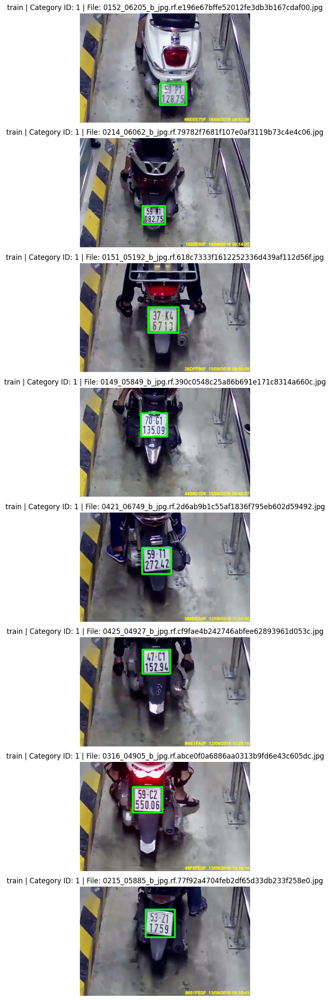

VALID ANNOTATIONS


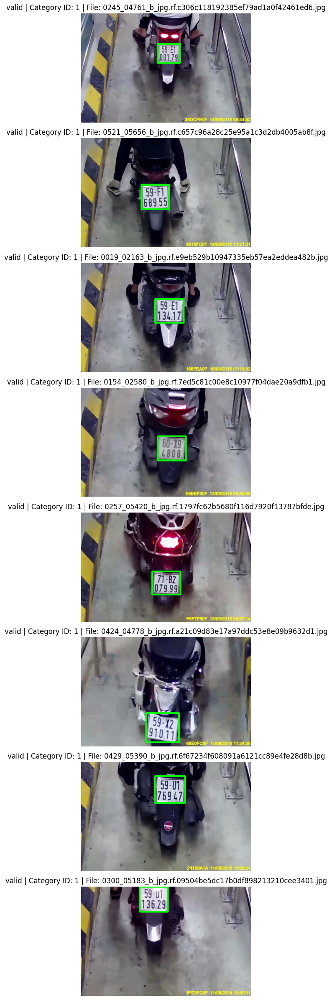

In [7]:
import json
import cv2
import matplotlib.pyplot as plt
import random
from pathlib import Path

random.seed(42)

def resolve_image(json_path, file_name):
    candidates = [
        json_path.parent / file_name,
        COCO_ROOT / file_name,
        json_path.parent / Path(file_name).name,
        COCO_ROOT / Path(file_name).name
    ]

    for path in candidates:
        if path.exists():
            return path

    return None


def show_coco_annotations(split, max_samples=8):

    json_path = COCO_ROOT / split / "_annotations.coco.json"

    with open(json_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    image_map = {
        img["id"]: img for img in coco["images"]
    }

    samples = random.sample(
        coco["annotations"],
        min(max_samples, len(coco["annotations"]))
    )

    fig, axes = plt.subplots(
        len(samples), 1,
        figsize=(12, len(samples) * 3)
    )

    if len(samples) == 1:
        axes = [axes]

    for ax, ann in zip(axes, samples):

        img_info = image_map.get(ann["image_id"])

        if img_info is None:
            ax.set_title("Không tìm thấy image_id")
            ax.axis("off")
            continue

        image_path = resolve_image(
            json_path,
            img_info["file_name"]
        )

        if image_path is None:
            ax.set_title(
                f"Không tìm thấy: {img_info['file_name']}"
            )
            ax.axis("off")
            continue

        image = cv2.imread(str(image_path))

        if image is None:
            ax.axis("off")
            continue

        image = cv2.cvtColor(
            image, cv2.COLOR_BGR2RGB
        )

        x, y, w, h = ann["bbox"]

        x1, y1 = int(x), int(y)
        x2, y2 = int(x + w), int(y + h)

        cv2.rectangle(
            image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            3
        )

        ax.imshow(image)
        ax.set_title(
            f"{split} | Category ID: {ann['category_id']} | "
            f"File: {Path(img_info['file_name']).name}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


print("TRAIN ANNOTATIONS")
show_coco_annotations("train", 8)

print("VALID ANNOTATIONS")
show_coco_annotations("valid", 8)

In [8]:

# ============================================================
# COCO TO YOLO CONVERSION
# GREEN PARKING DATASET
# ============================================================

import json
import cv2
import shutil
from pathlib import Path
from collections import defaultdict

COCO_ROOT = Path("/content/greenParking_dataset")
YOLO_ROOT = Path("/content/greenParking_yolo")

IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

# Category COCO thực tế đang chứa bounding box biển số
CATEGORY_ID_TO_YOLO = {
    1: 0
}

# Tạo thư mục YOLO
for split in ["train", "valid"]:
    (YOLO_ROOT / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (YOLO_ROOT / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

# Index ảnh để tìm theo tên file
image_index = defaultdict(list)

for p in COCO_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        image_index[p.name.lower()].append(p)


def resolve_image(json_path, split, file_name):
    file_name = str(file_name)
    original = Path(file_name)

    candidates = [
        json_path.parent / file_name,
        COCO_ROOT / split / file_name,
        COCO_ROOT / file_name
    ]

    if original.is_absolute():
        candidates.insert(0, original)

    for path in candidates:
        if path.is_file():
            return path

    matches = image_index.get(original.name.lower(), [])

    # Ưu tiên đúng thư mục train hoặc valid
    split_matches = [
        p for p in matches
        if split.lower() in [x.lower() for x in p.parts]
    ]

    if len(split_matches) == 1:
        return split_matches[0]

    if len(matches) == 1:
        return matches[0]

    raise FileNotFoundError(
        f"Không tìm thấy hoặc bị trùng tên ảnh: {file_name}"
    )


total_images = 0
total_boxes = 0

for split in ["train", "valid"]:

    print("\n" + "=" * 60)
    print("CONVERTING:", split.upper())
    print("=" * 60)

    json_path = (
        COCO_ROOT / split / "_annotations.coco.json"
    )

    if not json_path.exists():
        raise FileNotFoundError(json_path)

    with open(json_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    image_map = {
        img["id"]: img
        for img in coco["images"]
    }

    annotations_map = defaultdict(list)

    for ann in coco["annotations"]:
        category_id = int(ann["category_id"])

        if category_id not in CATEGORY_ID_TO_YOLO:
            raise ValueError(
                f"Category ID chưa được ánh xạ: {category_id}"
            )

        annotations_map[ann["image_id"]].append(ann)

    used_names = set()
    split_images = 0
    split_boxes = 0

    for img_info in coco["images"]:

        image_path = resolve_image(
            json_path,
            split,
            img_info["file_name"]
        )

        image = cv2.imread(str(image_path))

        if image is None:
            print("SKIP unreadable:", image_path)
            continue

        height, width = image.shape[:2]

        # Tránh trùng tên file
        output_name = image_path.name

        if output_name.lower() in used_names:
            output_name = (
                image_path.stem
                + f"_id{img_info['id']}"
                + image_path.suffix
            )

        used_names.add(output_name.lower())

        image_out = (
            YOLO_ROOT / "images" / split / output_name
        )

        label_out = (
            YOLO_ROOT / "labels" / split /
            (Path(output_name).stem + ".txt")
        )

        shutil.copy2(image_path, image_out)

        yolo_labels = []

        for ann in annotations_map.get(img_info["id"], []):

            x, y, w, h = map(float, ann["bbox"])

            # Clip bounding box vào kích thước ảnh
            x1 = max(0.0, x)
            y1 = max(0.0, y)
            x2 = min(float(width), x + w)
            y2 = min(float(height), y + h)

            box_w = x2 - x1
            box_h = y2 - y1

            if box_w <= 0 or box_h <= 0:
                continue

            # COCO xywh -> YOLO normalized xywh
            center_x = ((x1 + x2) / 2) / width
            center_y = ((y1 + y2) / 2) / height
            norm_w = box_w / width
            norm_h = box_h / height

            class_id = CATEGORY_ID_TO_YOLO[
                int(ann["category_id"])
            ]

            yolo_labels.append(
                f"{class_id} "
                f"{center_x:.8f} "
                f"{center_y:.8f} "
                f"{norm_w:.8f} "
                f"{norm_h:.8f}"
            )

        # Một dòng cho mỗi bounding box
        label_out.write_text(
            "\n".join(yolo_labels),
            encoding="utf-8"
        )

        split_images += 1
        split_boxes += len(yolo_labels)

    total_images += split_images
    total_boxes += split_boxes

    print("Images converted:", split_images)
    print("Bounding boxes:", split_boxes)

# Tạo data.yaml
yaml_content = f"""path: {YOLO_ROOT}
train: images/train
val: images/valid

nc: 1

names:
  0: plate
"""

(YOLO_ROOT / "data.yaml").write_text(
    yaml_content,
    encoding="utf-8"
)

print("\n" + "=" * 60)
print("COCO TO YOLO COMPLETED")
print("=" * 60)
print("Total images:", total_images)
print("Total bounding boxes:", total_boxes)
print("YOLO dataset:", YOLO_ROOT)
print("Config:", YOLO_ROOT / "data.yaml")



CONVERTING: TRAIN
Images converted: 1503
Bounding boxes: 1503

CONVERTING: VALID
Images converted: 245
Bounding boxes: 245

COCO TO YOLO COMPLETED
Total images: 1748
Total bounding boxes: 1748
YOLO dataset: /content/greenParking_yolo
Config: /content/greenParking_yolo/data.yaml


In [9]:
from pathlib import Path

YOLO_ROOT = Path("/content/greenParking_yolo")

for split in ["train", "valid"]:

    images = list(
        (YOLO_ROOT / "images" / split).glob("*")
    )

    labels = list(
        (YOLO_ROOT / "labels" / split).glob("*.txt")
    )

    non_empty = sum(
        bool(p.read_text().strip())
        for p in labels
    )

    print("\n", split.upper())
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Non-empty labels:", non_empty)

print("\ndata.yaml:")
print((YOLO_ROOT / "data.yaml").read_text())


 TRAIN
Images: 1503
Labels: 1503
Non-empty labels: 1503

 VALID
Images: 245
Labels: 245
Non-empty labels: 245

data.yaml:
path: /content/greenParking_yolo
train: images/train
val: images/valid

nc: 1

names:
  0: plate



In [10]:
from pathlib import Path

YOLO_ROOT = Path("/content/greenParking_yolo")

for split in ["train", "valid"]:

    images = list(
        (YOLO_ROOT / "images" / split).glob("*")
    )

    labels = list(
        (YOLO_ROOT / "labels" / split).glob("*.txt")
    )

    non_empty = sum(
        bool(p.read_text().strip())
        for p in labels
    )

    print("\n", split.upper())
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Non-empty labels:", non_empty)

print("\ndata.yaml:")
print((YOLO_ROOT / "data.yaml").read_text())


 TRAIN
Images: 1503
Labels: 1503
Non-empty labels: 1503

 VALID
Images: 245
Labels: 245
Non-empty labels: 245

data.yaml:
path: /content/greenParking_yolo
train: images/train
val: images/valid

nc: 1

names:
  0: plate



In [11]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")
else:
    raise RuntimeError("PyTorch chưa nhận GPU. Không tiếp tục huấn luyện!")

PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
VRAM: 14.56 GB


In [12]:
%pip install -q ultralytics

from ultralytics import YOLO
import ultralytics

print("Ultralytics:", ultralytics.__version__)
print("YOLO READY!")

Ultralytics: 8.4.210
YOLO READY!


In [13]:

# ============================================================
# TRAIN YOLOv8n - VIETNAM LICENSE PLATE DETECTION
# GPU: NVIDIA TESLA T4
# ============================================================

import torch
from ultralytics import YOLO

assert torch.cuda.is_available(), "GPU CUDA chưa sẵn sàng!"

DATA_YAML = "/content/greenParking_yolo/data.yaml"

print("GPU:", torch.cuda.get_device_name(0))
print("Loading pretrained YOLOv8n...")

# Sử dụng trọng số pretrained
model = YOLO("yolov8n.pt")

# Huấn luyện mô hình
results = model.train(
    data=DATA_YAML,
    epochs=100,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=20,
    optimizer="auto",
    pretrained=True,
    save=True,
    plots=True,
    project="/content/alpr_yolo_training",
    name="greenparking_yolov8n",
    exist_ok=True,
    seed=42,
    verbose=True
)

print("\nYOLO TRAINING COMPLETED!")
print("Best model:")
print("/content/alpr_yolo_training/greenparking_yolov8n/weights/best.pt")


GPU: Tesla T4
Loading pretrained YOLOv8n...
Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/greenParking_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=greenpar

In [14]:
from ultralytics import YOLO

BEST_MODEL = (
    "/content/alpr_yolo_training/"
    "greenparking_yolov8n/weights/best.pt"
)

model = YOLO(BEST_MODEL)

metrics = model.val(
    data="/content/greenParking_yolo/data.yaml",
    split="val",
    imgsz=640,
    device=0,
    plots=True
)

print("=" * 50)
print("YOLO VALIDATION RESULTS")
print("=" * 50)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 647.0±144.7 MB/s, size: 16.8 KB)
val: Scanning /content/greenParking_yolo/labels/valid.cache... 245 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 245/245 68.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 4.7it/s 3.4s
                   all        245        245          1          1      0.995      0.937
Speed: 1.1ms preprocess, 4.2ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val
YOLO VALIDATION RESULTS
Precision: 0.999774156946097
Recall: 1.0
mAP50: 0.995
mAP50-95: 0.9372301078095109


In [15]:
onnx_path = model.export(
    format="onnx",
    imgsz=640,
    opset=12,
    simplify=False
)

print("ONNX EXPORTED:", onnx_path)

Ultralytics 8.4.210 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from '/content/alpr_yolo_training/greenparking_yolov8n/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (6.2 MB)
requirements: Ultralytics requirement ['onnx>=1.12.0,<2.0.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 220ms
Prepared 1 package in 395ms
Installed 1 package in 26ms
 + onnx==1.23.2

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 12...
ONNX: export success ✅ 1.6s, saved as '/content/alpr_yolo_training/greenparking_yolov8n/weights/best

Loading /content/alpr_yolo_training/greenparking_yolov8n/weights/best.onnx for ONNX Runtime inference...
requirements: Ultralytics requirement ['onnxruntime'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 5 packages in 317ms
Prepared 1 package in 590ms
Installed 1 package in 7ms
 + onnxruntime==1.31.1

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Using ONNX Runtime 1.31.1 with CPUExecutionProvider

image 1/245 /content/greenParking_yolo/images/valid/0000_08244_b_jpg.rf.89ba7bb36c0bf34f58039e02a8415bf8.jpg: 640x640 1 plate, 93.1ms
image 2/245 /content/greenParking_yolo/images/valid/0003_02063_b_jpg.rf.23bdad4856b42951178be7bd05523d5c.jpg: 640x640 1 plate, 107.8ms
image 3/245 /content/greenParking_yolo/images/valid/0005_02171_b_jpg.rf.2626d55e2b8eb3f45a1639fc5de3d610.jpg: 640x640 1 plate, 112.4ms
image 4/245 /content/greenParking_yolo/images/valid/0006_05286_b_jpg.rf.

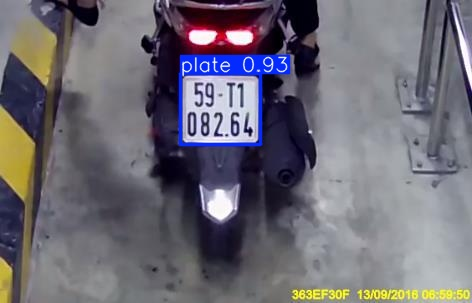

0003_02063_b_jpg.rf.23bdad4856b42951178be7bd05523d5c.jpg


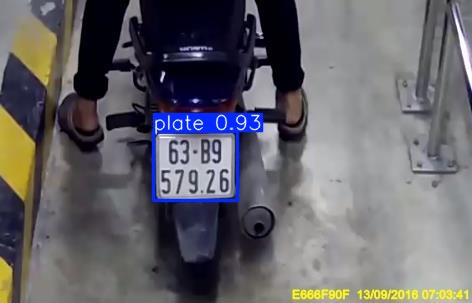

0005_02171_b_jpg.rf.2626d55e2b8eb3f45a1639fc5de3d610.jpg


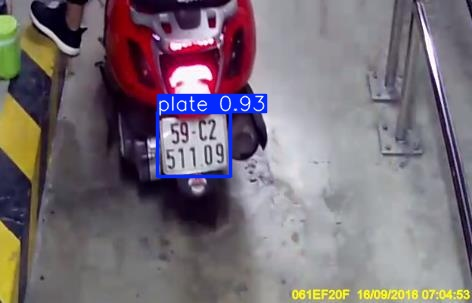

0006_05286_b_jpg.rf.257172de1cd94399567ed24873e6508e.jpg


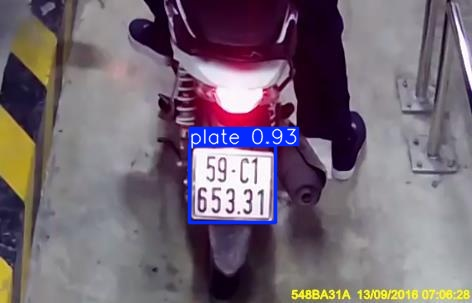

0007_02188_b_jpg.rf.50e9c14d9ab459ed93ce97efc250977d.jpg


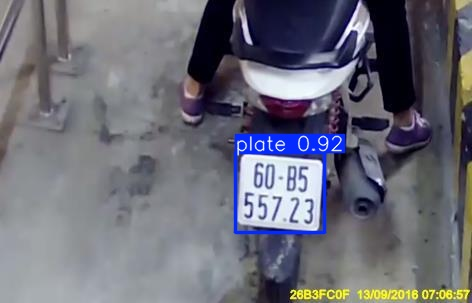

0012_04539_b_jpg.rf.ff99acd284e51ee0fb7e2c27935205ca.jpg


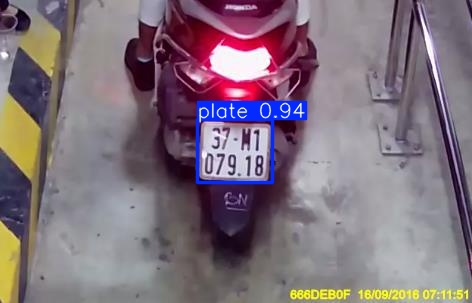

0017_00195_b_jpg.rf.a97bf61f4403a13eb0367327073b67bf.jpg


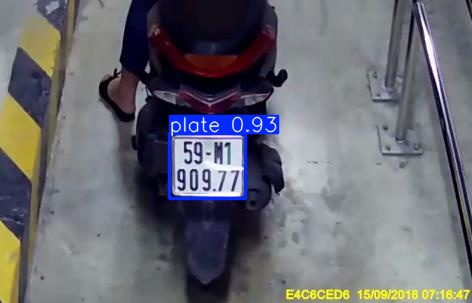

0019_02163_b_jpg.rf.e9eb529b10947335eb57ea2eddea482b.jpg


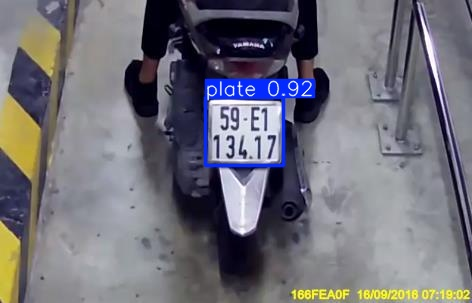

In [16]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image as IPyImage

ONNX_PATH = (
    "/content/alpr_yolo_training/"
    "greenparking_yolov8n/weights/best.onnx"
)

VALID_DIR = "/content/greenParking_yolo/images/valid"

# Nạp ONNX
onnx_model = YOLO(ONNX_PATH)

# Chạy dự đoán trên tập valid
results = onnx_model.predict(
    source=VALID_DIR,
    imgsz=640,
    conf=0.25,
    iou=0.45,
    device="cpu",
    save=True,
    project="/content/alpr_yolo_training",
    name="onnx_valid_preview",
    exist_ok=True
)

print("ONNX prediction completed!")

# Hiển thị 8 ảnh đầu tiên
output_dir = Path(
    "/content/alpr_yolo_training/onnx_valid_preview"
)

saved_images = sorted([
    *output_dir.glob("*.jpg"),
    *output_dir.glob("*.png"),
    *output_dir.glob("*.jpeg")
])

print("Images generated:", len(saved_images))

for path in saved_images[:8]:
    print(path.name)
    display(IPyImage(filename=str(path), width=650))

In [17]:
import os
import shutil

SOURCE = "/content/alpr_yolo_training/greenparking_yolov8n/weights/best.onnx"
DESTINATION = "/content/license_plate_yolov8n.onnx"

if not os.path.isfile(SOURCE):
    raise FileNotFoundError(f"Không tìm thấy mô hình: {SOURCE}")

shutil.copy2(SOURCE, DESTINATION)

print("Đã chuyển YOLO ONNX sang vị trí nhận diện!")
print("Model:", DESTINATION)

Đã chuyển YOLO ONNX sang vị trí nhận diện!
Model: /content/license_plate_yolov8n.onnx


In [18]:
import os

YOLO_ONNX_PATH = "/content/license_plate_yolov8n.onnx"

if os.path.isfile(YOLO_ONNX_PATH):
    print("YOLO ONNX đã sẵn sàng!")
    print("Đường dẫn:", YOLO_ONNX_PATH)
    print(f"Kích thước: {os.path.getsize(YOLO_ONNX_PATH) / (1024 * 1024):.2f} MB")
else:
    raise FileNotFoundError(
        f"Không tìm thấy mô hình YOLO: {YOLO_ONNX_PATH}"
    )

YOLO ONNX đã sẵn sàng!
Đường dẫn: /content/license_plate_yolov8n.onnx
Kích thước: 12.16 MB


In [19]:
import os

print("YOLO:", os.path.isfile(
    "/content/license_plate_yolov8n.onnx"
))

print("DATASET:", os.path.isdir(
    "/content/greenParking_dataset"
))

print("ZIP:", os.path.isfile(
    "/content/greenParking.v1i.coco.zip"
))

YOLO: True
DATASET: True
ZIP: True


In [20]:

# ============================================================
# INSTALL ALPR ENVIRONMENT - GOOGLE COLAB T4
# PaddlePaddle 3.2.0 + PaddleOCR 3.2.0
# ============================================================

import os

# Paddle configuration
os.environ["FLAGS_enable_pir_api"] = "0"
os.environ["FLAGS_enable_pir_in_executor"] = "0"
os.environ["PADDLE_PDX_ENABLE_MKLDNN_BYDEFAULT"] = "0"
os.environ["FLAGS_use_mkldnn"] = "0"
os.environ["PADDLE_PDX_EAGER_INIT"] = "False"

# 1. Remove old Paddle packages
!pip uninstall -y paddlepaddle paddlepaddle-gpu

# 2. Install Paddle GPU CUDA 11.8
!pip install paddlepaddle-gpu==3.2.0 \
-i https://www.paddlepaddle.org.cn/packages/stable/cu118/

# 3. Install PaddleOCR
!pip install paddleocr==3.2.0

# 4. Remove incompatible optional LangChain packages
!pip uninstall -y langchain langchain-community langchain-core langchain-text-splitters langchain-classic

# 5. Install supporting libraries
!pip install matplotlib tqdm pandas opencv-python-headless

print("ALPR ENVIRONMENT INSTALLATION COMPLETED!")


Looking in indexes: https://www.paddlepaddle.org.cn/packages/stable/cu118/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 GB 4.7 MB/s  0:02:25
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 7.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 9.5 MB/s  0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 699.9/699.9 MB 8.2 MB/s  0:01:17
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 7.3 MB/s  0:00:50
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.4/168.4 MB 9.3 MB/s  0:00:18
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 MB 8.4 MB/s  0:00:06
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 8.9 MB/s  0:00:14
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.1/204.1 MB 7.5 MB/s  0:00:27
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.3/135.3 MB 9.3 MB/s  0:00:14
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.2/23.2 MB 9.5 MB/s  0:00:02
  Attempting uninstall: opt_einsum
    Found existing installation

Found existing installation: langchain 1.4.8
Uninstalling langchain-1.4.8:
  Successfully uninstalled langchain-1.4.8
Found existing installation: langchain-core 1.7.4
Uninstalling langchain-core-1.7.4:
  Successfully uninstalled langchain-core-1.7.4
ALPR ENVIRONMENT INSTALLATION COMPLETED!


In [21]:
# ============================================================
# REMOVE BROKEN PYTORCH FROM ALPR RUNTIME
# KHÔNG GỠ PADDLE
# ============================================================

!pip uninstall -y torch torchvision torchaudio

print("PYTORCH REMOVAL COMPLETED!")

Found existing installation: torch 2.11.0+cu130
Uninstalling torch-2.11.0+cu130:
  Successfully uninstalled torch-2.11.0+cu130
Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
PYTORCH REMOVAL COMPLETED!


In [1]:

# ============================================================
# FIX TORCH NAMESPACE / MODELSCOPE IMPORT
# ALPR RUNTIME
# ============================================================

# 1. Gỡ các bản Torch cũ
!pip uninstall -y torch torchvision torchaudio

# 2. Xóa thư mục Torch còn sót sau khi uninstall
import shutil
import site
from pathlib import Path

for site_dir in site.getsitepackages():
    torch_dir = Path(site_dir) / "torch"

    if torch_dir.exists():
        shutil.rmtree(torch_dir, ignore_errors=True)
        print("Removed residual:", torch_dir)

# 3. Cài PyTorch CPU đầy đủ
!pip install --no-cache-dir --force-reinstall \
    torch==2.11.0 \
    --index-url https://download.pytorch.org/whl/cpu

print("TORCH CPU INSTALLATION COMPLETED!")


Removed residual: /usr/local/lib/python3.13/dist-packages/torch
Looking in indexes: https://download.pytorch.org/whl/cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.3/190.3 MB 181.3 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 86.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 20.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.3/6.3 MB 48.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 27.8 MB/s  0:00:00
  Attempting uninstall: mpmath
    Found existing installation: mpmath 1.3.0
    Uninstalling mpmath-1.3.0:
      Successfully uninstalled mpmath-1.3.0
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.16.0
    Uninstalling typing_extensions-4.16.0:
      Successfully uninstalled typing_extensions-4.16.0
  Attempting uninstall: sympy
    Found existing installation: sympy 1.14.0
    Uninstalling sympy-1.14.0:
      Successfully uninstalled sympy-1.14.

TORCH CPU INSTALLATION COMPLETED!


In [1]:

# ============================================================
# REPAIR PYTORCH CPU - GOOGLE COLAB PYTHON 3.13
# KHÔNG GỠ PADDLEPADDLE
# ============================================================

import os
import sys
import site
import shutil
import subprocess
from pathlib import Path

print("PYTHON:", sys.version)

# 1. Gỡ các gói Torch cũ
subprocess.run([
    sys.executable, "-m", "pip",
    "uninstall", "-y",
    "torch", "torchvision", "torchaudio"
])

# 2. Xóa Torch còn sót trong TẤT CẢ đường dẫn Python
paths = set(sys.path)

try:
    paths.update(site.getsitepackages())
except Exception:
    pass

try:
    paths.add(site.getusersitepackages())
except Exception:
    pass

for root in paths:
    if not root or not os.path.isdir(root):
        continue

    root = Path(root)

    for pattern in [
        "torch",
        "torch-*.dist-info",
        "torch-*.data",
        "torch.libs",
        "torchgen",
        "functorch",
        "torchvision",
        "torchvision-*.dist-info",
        "torchaudio",
        "torchaudio-*.dist-info"
    ]:
        for target in root.glob(pattern):
            if target.is_dir():
                shutil.rmtree(target, ignore_errors=True)
            elif target.exists():
                target.unlink(missing_ok=True)
            print("REMOVED:", target)

# 3. Cài chính xác bản Torch CPU cho Python 3.13
command = [
    sys.executable, "-m", "pip",
    "install",
    "--no-cache-dir",
    "--force-reinstall",
    "torch==2.11.0+cpu",
    "--index-url",
    "https://download.pytorch.org/whl/cpu",
    "--extra-index-url",
    "https://pypi.org/simple"
]

subprocess.run(command, check=True)

print("\nPYTORCH REPAIR COMPLETED!")
print("NOW RESTART COLAB SESSION!")


PYTHON: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

PYTORCH REPAIR COMPLETED!
NOW RESTART COLAB SESSION!


In [2]:
import torch
import torch.multiprocessing as mp

print("TORCH VERSION:", torch.__version__)
print("TORCH PATH:", torch.__file__)
print("TORCH CUDA:", torch.cuda.is_available())
print("TORCH MULTIPROCESSING:", mp)

print("TORCH _C:", torch._C)
print("TORCH IMPORT SUCCESS!")

TORCH VERSION: 2.11.0+cpu
TORCH PATH: /usr/local/lib/python3.13/dist-packages/torch/__init__.py
TORCH CUDA: False
TORCH MULTIPROCESSING: <module 'torch.multiprocessing' from '/usr/local/lib/python3.13/dist-packages/torch/multiprocessing/__init__.py'>
TORCH _C: <module 'torch._C' from '/usr/local/lib/python3.13/dist-packages/torch/_C.cpython-313-x86_64-linux-gnu.so'>
TORCH IMPORT SUCCESS!


In [3]:
import paddle
from paddleocr import PaddleOCR

print("PADDLE:", paddle.__version__)
print("CUDA:", paddle.is_compiled_with_cuda())
print("GPU COUNT:", paddle.device.cuda.device_count())

paddle.device.set_device("gpu:0")

# Tái sử dụng OCR đã khởi tạo ở cell kiểm tra trước đó
if "ocr" in globals() and ocr is not None:
    print("REUSING EXISTING PADDLEOCR INSTANCE")
else:
    ocr = PaddleOCR(
        use_textline_orientation=True,
        lang="en",
        device="gpu:0"
    )

print("PADDLEOCR READY!")

/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)
Creating model: ('PP-LCNet_x1_0_doc_ori', None)
Using official model (PP-LCNet_x1_0_doc_ori), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-LCNet_x1_0_doc_ori`.


PADDLE: 3.2.0
CUDA: True
GPU COUNT: 1


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Creating model: ('UVDoc', None)
Using official model (UVDoc), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/UVDoc`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

... (7 outputs left out)

Creating model: ('en_PP-OCRv5_mobile_rec', None)
Using official model (en_PP-OCRv5_mobile_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/en_PP-OCRv5_mobile_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

PADDLEOCR READY!


In [4]:
import os

print("YOLO ONNX:",
      os.path.exists("/content/license_plate_yolov8n.onnx"))

print("DATASET ZIP:",
      os.path.exists("/content/greenParking.v1i.coco.zip"))

print("DATASET EXTRACTED:",
      os.path.exists("/content/greenParking_dataset"))

YOLO ONNX: True
DATASET ZIP: True
DATASET EXTRACTED: True


Đã tìm thấy dataset đã giải nén; bỏ qua bước giải nén ZIP.
Dataset ZIP: /content/greenParking.v1i.coco.zip
Image root: /content/greenParking_dataset
Output root: /content/alpr_output

INITIALIZING PADDLEOCR
PaddlePaddle: 3.2.0
CUDA compiled: True
GPU count: 1
OCR device: gpu:0
Reusing the PaddleOCR instance already initialized in this notebook.
YOLO ONNX loaded: /content/license_plate_yolov8n.onnx

SCANNING DATASET IMAGES
Input root: /content/greenParking_dataset
Images selected: 1748
YOLO active: True
OCR device: gpu:0

STARTING PLATE LOCALIZATION + OCR


ALPR:   0%|          | 0/1748 [00:00<?, ?image/s]

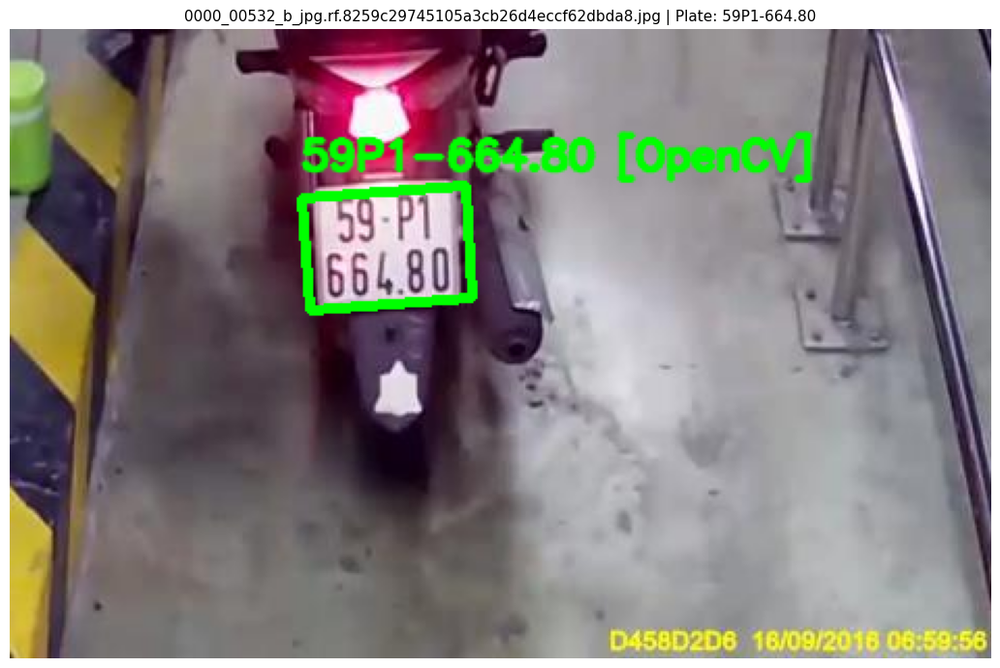

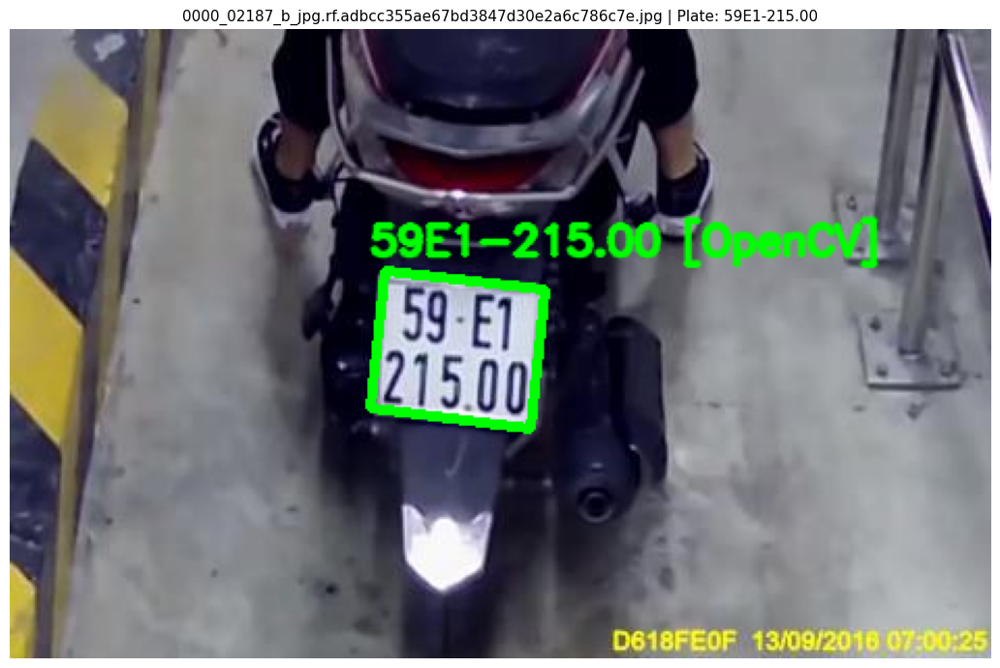

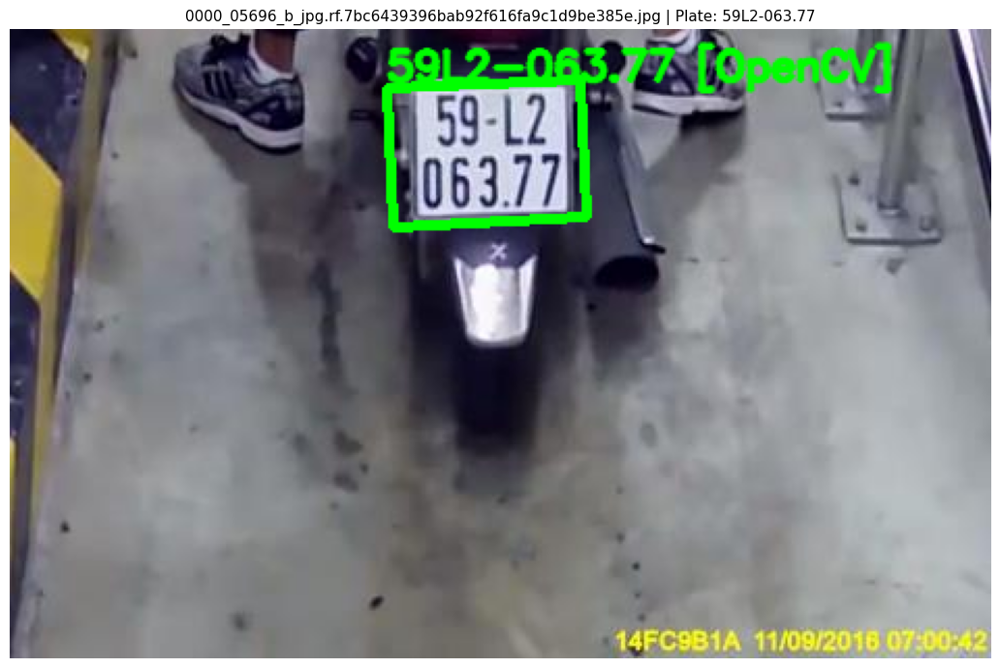

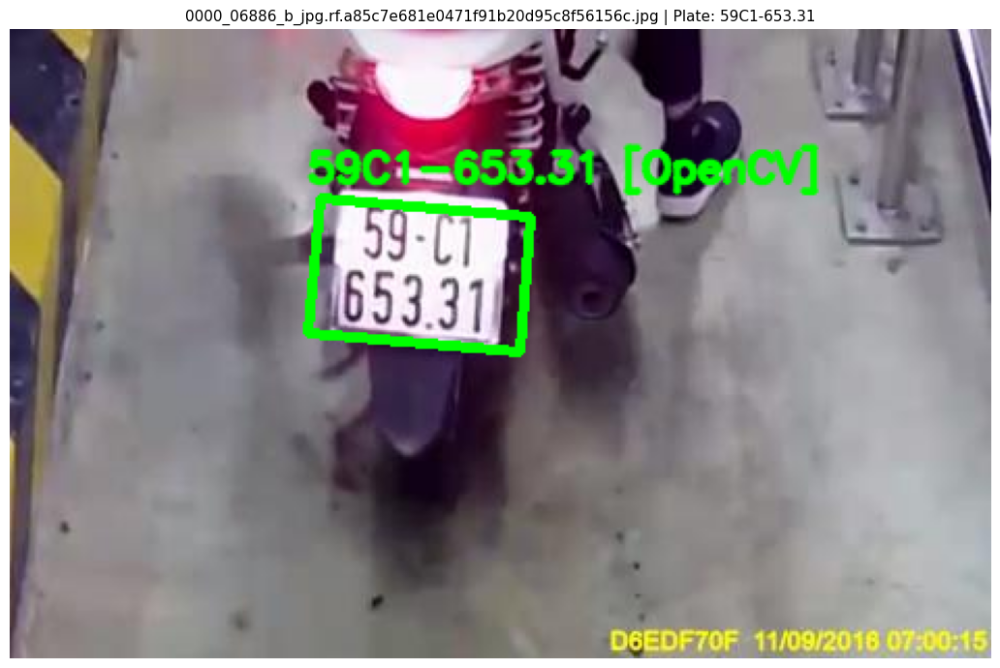

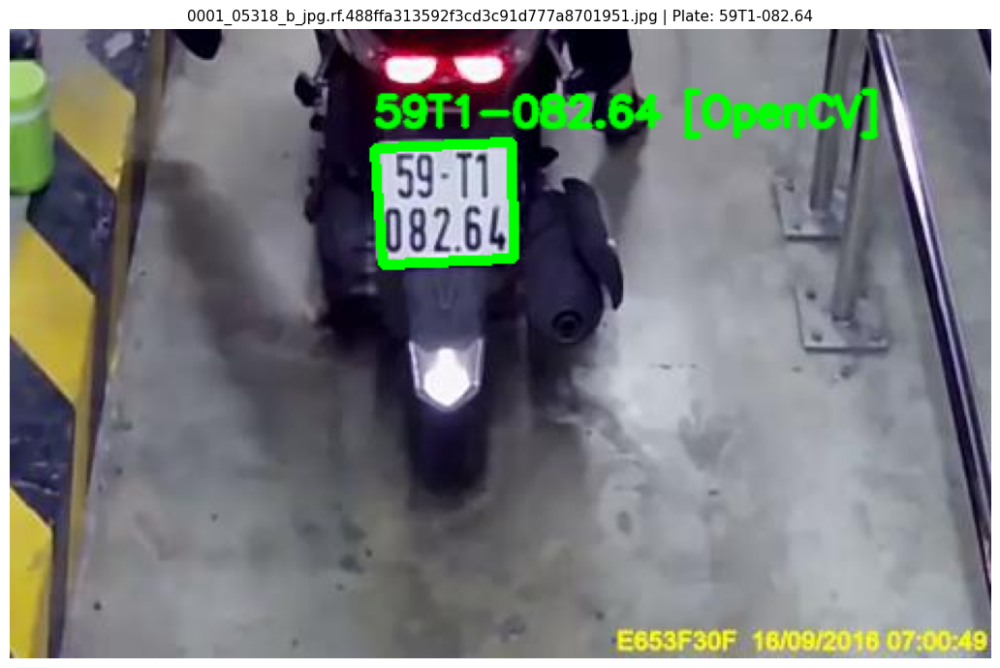

...

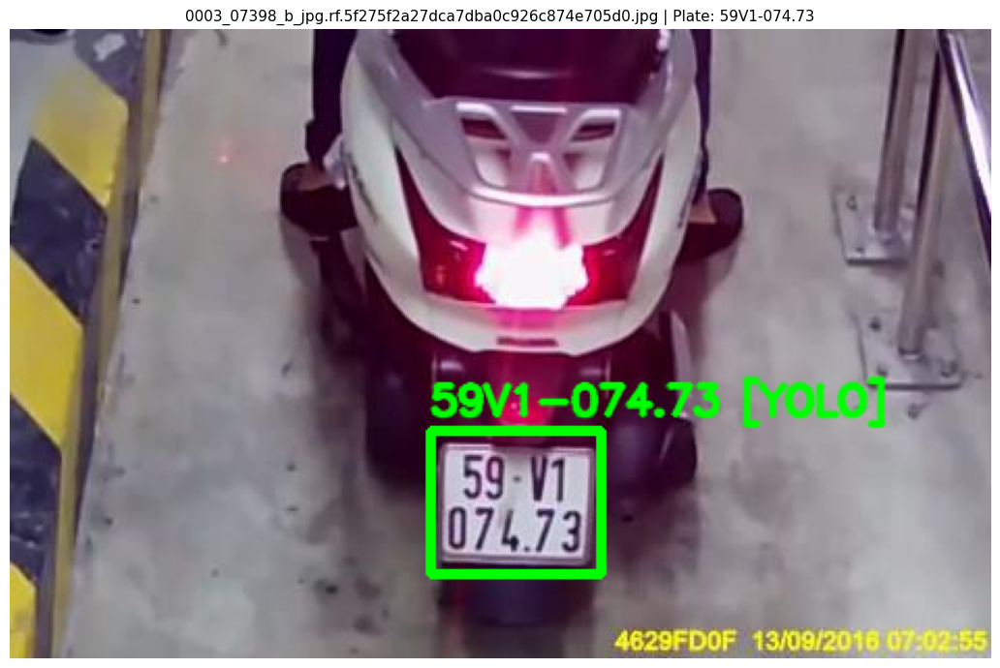

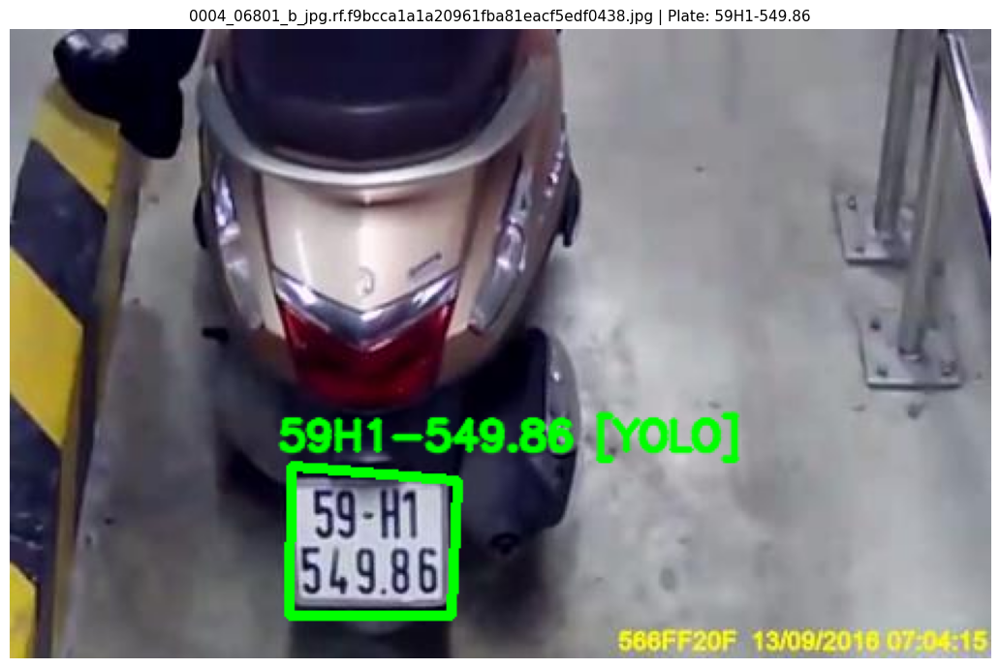

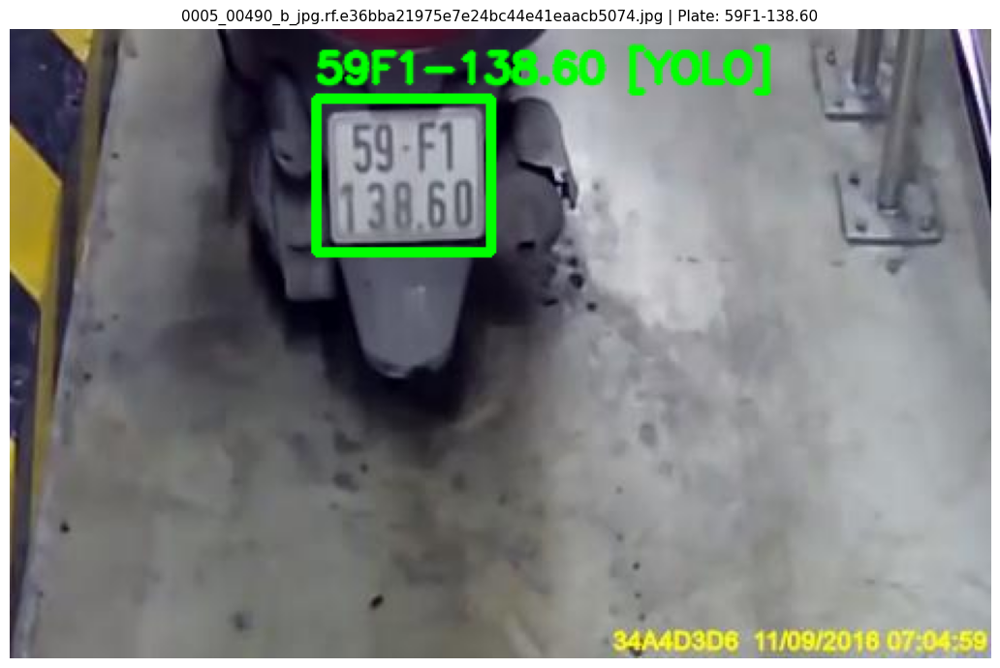

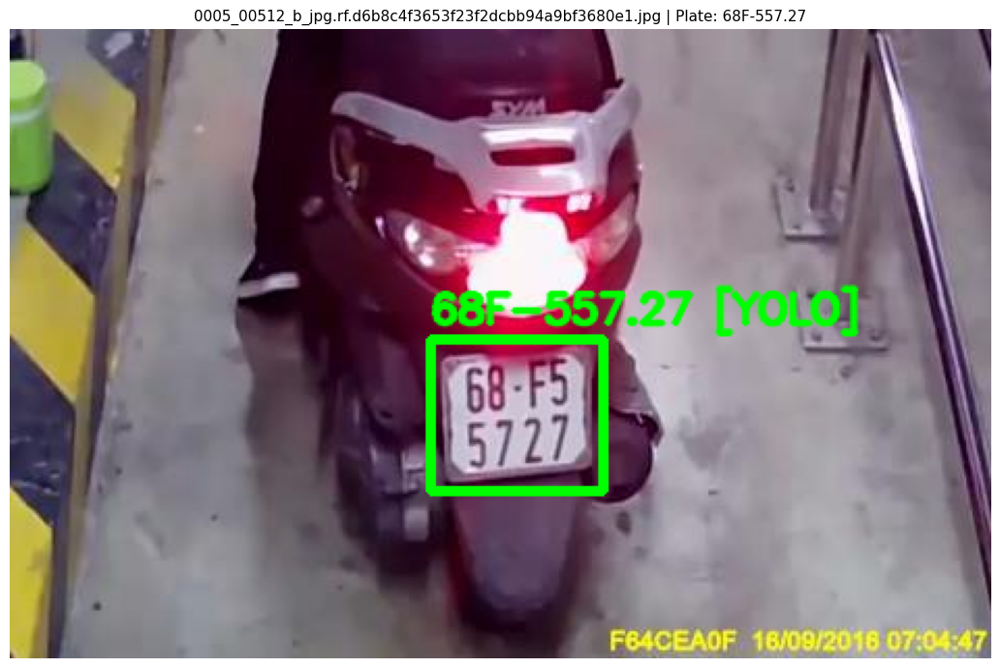

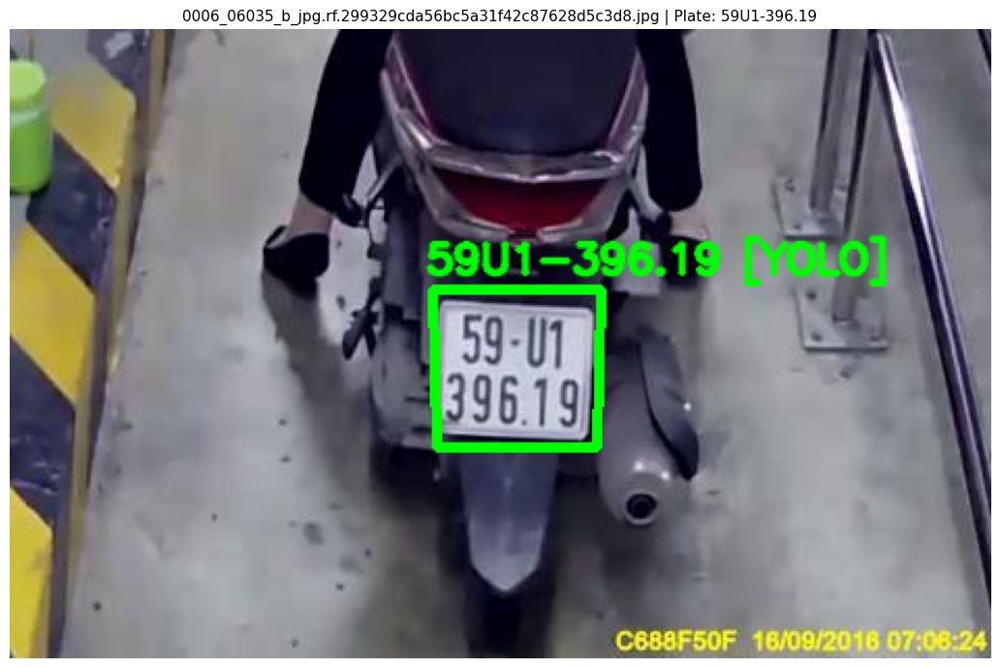


FINAL REPORT
Total images:                 1748
Recognized:                   1720
Not recognized:               28
Errors:                       0
Image recognition success:    98.40%
Average time per image:       0.79 seconds
CSV report: /content/alpr_output/plate_ocr_results.csv
Annotated images: /content/alpr_output/annotated_images
Rectified candidate crops: /content/alpr_output/rectified_plate_crops


,file,plate,status,candidate_count,method,raw_text,processing_seconds
0,0000_00532_b_jpg.rf.8259c29745105a3cb26d4eccf6...,59P1-664.80,RECOGNIZED,6,opencv_original,59-P1 | 664.80,2.782
1,0000_02187_b_jpg.rf.adbcc355ae67bd3847d30e2a6c...,59E1-215.00,RECOGNIZED,6,opencv_original,59.E1 | 215.00,1.266
2,0000_05696_b_jpg.rf.7bc6439396bab92f616fa9c1d9...,59L2-063.77,RECOGNIZED,6,opencv_original,59-L2 | 063.77,1.260
3,0000_06886_b_jpg.rf.a85c7e681e0471f91b20d95c8f...,59C1-653.31,RECOGNIZED,6,opencv_original,59-C1 | 653.31,0.628
4,0001_05318_b_jpg.rf.488ffa313592f3cd3c91d777a8...,59T1-082.64,RECOGNIZED,6,opencv_original,59-T1 | 082.64,0.671
5,0002_02183_b_jpg.rf.6f9075544b7de63e84f26c4bbe...,52U-786.93,RECOGNIZED,6,yolo_original,52-U7 | 8693,1.763
6,0002_02554_b_jpg.rf.29ddf7e9d649578f6b544eff14...,59F1-689.55,RECOGNIZED,6,opencv_original,59-F1 | 689.55,1.465
7,0003_07398_b_jpg.rf.5f275f2a27dca7dba0c926c874...,59V1-074.73,RECOGNIZED,6,yolo_original,59-V1 | 074.73,1.266
8,0004_06801_b_jpg.rf.f9bcca1a1a20961fba81eacf5e...,59H1-549.86,RECOGNIZED,6,yolo_original,59-H1 | 549.86,1.186
9,0005_00490_b_jpg.rf.e36bba21975e7e24bc44e41eaa...,59F1-138.60,RECOGNIZED,6,yolo_original,59-F1 | 138.60,1.524



Số ảnh chưa nhận diện thành công (NOT_RECOGNIZED + ERROR): 28


,file,status,candidate_count,raw_text,error
133,0114_00145_b_jpg.rf.a58123b5a58b0dc83fbd059b90...,NOT_RECOGNIZED,6,47-81 | 428.72,
220,0126_00136_b_jpg.rf.bf9431cd7dcd0f973d713db940...,NOT_RECOGNIZED,6,6187 | LA-TS,
280,0134_01049_b_jpg.rf.de9683f5de5c87b53367d38c29...,NOT_RECOGNIZED,6,8101 | 57-75,
286,0135_00503_b_jpg.rf.31c9911935db3a274d254a28d4...,NOT_RECOGNIZED,6,60 86 | 280.32,
329,0139_08121_b_jpg.rf.e20b3e937639bbaa46a3219bdf...,NOT_RECOGNIZED,6,N6 | 00 | 5519,
351,0142_06535_b_jpg.rf.bac896a8cb9b8d52a4a461581e...,NOT_RECOGNIZED,6,613.861 | 81-815,
483,0200_06533_b_jpg.rf.65aa714b27adb6772bbed64864...,NOT_RECOGNIZED,6,81.4.7 | 54-K4,
501,0203_06622_b_jpg.rf.d41374f5a985beb9e0ed8073cd...,NOT_RECOGNIZED,6,47-81 | 426.42,
511,0205_08135_b_jpg.rf.2a55865990c12122ac7bdc3f72...,NOT_RECOGNIZED,6,59-01 | 399.97,
559,0212_07303_b_jpg.rf.7edf4d006742569b870e617b39...,NOT_RECOGNIZED,6,54-77 | 3400,



Results ZIP: /content/alpr_results.zip
Tải toàn bộ kết quả bằng cell:
from google.colab import files; files.download('/content/alpr_results.zip')


In [5]:
# -*- coding: utf-8 -*-
"""
VIETNAM MOTORBIKE / CAR ALPR - GOOGLE COLAB
YOLOv8n ONNX + OpenCV localization/rectification + image enhancement + PaddleOCR.

- YOLO ONNX is optional. If it is missing or fails to load, OpenCV localization is used.
- PaddleOCR 3.x is preferred; a PaddleOCR 2.x fallback is included.
- The script processes all images by default. Set MAX_IMAGES = 20 for a quick test.
- This is an inference script. Train/export YOLO separately and put the ONNX file at
  /content/license_plate_yolov8n.onnx.

IMPORTANT:
Recognition success means the text passed the heuristic Vietnamese plate parser.
It is not the same as independently verified exact-match accuracy.
"""

# ============================================================
# 1. CONFIGURATION + ENVIRONMENT
# ============================================================
import os
os.environ["FLAGS_enable_pir_api"] = "0"
os.environ["FLAGS_enable_pir_in_executor"] = "0"
os.environ["PADDLE_PDX_ENABLE_MKLDNN_BYDEFAULT"] = "0"
os.environ["FLAGS_use_mkldnn"] = "0"
os.environ["PADDLE_PDX_EAGER_INIT"] = "False"

import re
import json
import csv
import math
import time
import traceback
import zipfile
import shutil
from pathlib import Path
from collections.abc import Iterable

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

# -------- Dataset --------
ZIP_PATH = "/content/greenParking.v1i.coco.zip"
EXTRACT_DIR = "/content/greenParking_dataset"
IMAGE_ROOT = EXTRACT_DIR

# -------- Output --------
OUTPUT_ROOT = "/content/alpr_output"
ANNOTATED_DIR = os.path.join(OUTPUT_ROOT, "annotated_images")
CROPS_DIR = os.path.join(OUTPUT_ROOT, "rectified_plate_crops")
CSV_OUTPUT_PATH = os.path.join(OUTPUT_ROOT, "plate_ocr_results.csv")
RESULTS_ZIP_PATH = "/content/alpr_results.zip"

# -------- Batch options --------
MAX_IMAGES = None          # None = all images; set 20 for a short test run
SHOW_PREVIEWS = True
MAX_PREVIEWS = 12
MAX_PLATE_CANDIDATES = 6

# -------- YOLO ONNX --------
YOLO_ONNX_PATH = "/content/license_plate_yolov8n.onnx"
USE_YOLO_ONNX = True
YOLO_INPUT_SIZE = 640      # Must match the exported ONNX input size
YOLO_CONF_THRESHOLD = 0.22
YOLO_NMS_THRESHOLD = 0.45
YOLO_MAX_CANDIDATES = 3

# -------- OCR retry --------
# 12 lets the first candidate test all enhancement variants, including rotations.
MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE = 12
RETRY_CANDIDATE_COUNT = 2
REUSE_EXISTING_OCR = True

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

for folder in (OUTPUT_ROOT, ANNOTATED_DIR, CROPS_DIR):
    os.makedirs(folder, exist_ok=True)


def has_images(folder):
    if not os.path.isdir(folder):
        return False
    for root, _dirs, names in os.walk(folder):
        if any(Path(name).suffix.lower() in IMAGE_EXTENSIONS for name in names):
            return True
    return False


def obtain_dataset_zip():
    """Upload ZIP only when the extracted dataset is not already available."""
    global ZIP_PATH
    if os.path.isfile(ZIP_PATH):
        return ZIP_PATH

    try:
        from google.colab import files
        print(f"Không tìm thấy ZIP tại {ZIP_PATH}.")
        print("Hãy chọn file greenParking.v1i.coco.zip.")
        uploaded = files.upload()
        names = [name for name in uploaded if name.lower().endswith(".zip")]
        if not names:
            raise FileNotFoundError("Bạn chưa tải lên file ZIP.")
        ZIP_PATH = os.path.join("/content", names[0])
        return ZIP_PATH
    except ImportError as exc:
        raise FileNotFoundError(
            f"Không tìm thấy {ZIP_PATH}. Hãy tải ZIP vào /content trước khi chạy."
        ) from exc


if not has_images(EXTRACT_DIR):
    zip_path = obtain_dataset_zip()
    if not zipfile.is_zipfile(zip_path):
        raise RuntimeError(f"File không phải ZIP hợp lệ: {zip_path}")

    if os.path.isdir(EXTRACT_DIR):
        shutil.rmtree(EXTRACT_DIR)
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    print("Đang giải nén dataset...")

    # Prevent ZIP path traversal (Zip Slip).
    destination = os.path.abspath(EXTRACT_DIR)
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = os.path.abspath(os.path.join(EXTRACT_DIR, member.filename))
            if os.path.commonpath([destination, target]) != destination:
                raise RuntimeError(f"ZIP chứa đường dẫn không an toàn: {member.filename}")
        zf.extractall(EXTRACT_DIR)
    print("Đã giải nén xong.")
else:
    print("Đã tìm thấy dataset đã giải nén; bỏ qua bước giải nén ZIP.")

if not has_images(IMAGE_ROOT):
    raise RuntimeError(f"Không tìm thấy ảnh trong thư mục: {IMAGE_ROOT}")

print("Dataset ZIP:", ZIP_PATH if os.path.isfile(ZIP_PATH) else "(using extracted folder)")
print("Image root:", IMAGE_ROOT)
print("Output root:", OUTPUT_ROOT)

# ============================================================
# 2. INITIALIZE / REUSE PADDLEOCR
# ============================================================
print("\n" + "=" * 70)
print("INITIALIZING PADDLEOCR")
print("=" * 70)

import paddle
from paddleocr import PaddleOCR

paddle_version = getattr(paddle, "__version__", "unknown")
try:
    gpu_count = int(paddle.device.cuda.device_count())
except Exception:
    gpu_count = 0

try:
    cuda_compiled = bool(paddle.is_compiled_with_cuda())
except Exception:
    cuda_compiled = False

USE_PADDLE_GPU = cuda_compiled and gpu_count > 0
OCR_DEVICE = "gpu:0" if USE_PADDLE_GPU else "cpu"
print("PaddlePaddle:", paddle_version)
print("CUDA compiled:", cuda_compiled)
print("GPU count:", gpu_count)
print("OCR device:", OCR_DEVICE)

_existing_ocr = globals().get("ocr") if REUSE_EXISTING_OCR else None
if _existing_ocr is not None and (callable(getattr(_existing_ocr, "predict", None)) or
                                  callable(getattr(_existing_ocr, "ocr", None))):
    ocr = _existing_ocr
    print("Reusing the PaddleOCR instance already initialized in this notebook.")
else:
    try:
        try:
            paddle.device.set_device(OCR_DEVICE)
        except Exception as device_error:
            print("Thông báo: không đặt được Paddle device:", device_error)

        try:
            # PaddleOCR 3.x
            ocr = PaddleOCR(
                use_textline_orientation=True,
                lang="en",
                device=OCR_DEVICE
            )
        except TypeError:
            # PaddleOCR 2.x compatibility
            ocr = PaddleOCR(
                use_angle_cls=True,
                lang="en",
                use_gpu=USE_PADDLE_GPU
            )
        print("PaddleOCR initialized successfully.")
    except Exception as exc:
        raise RuntimeError(
            "Không thể khởi tạo PaddleOCR. Kiểm tra phiên bản PaddlePaddle/PaddleOCR "
            "và runtime.\nChi tiết: " + repr(exc)
        ) from exc

# ============================================================
# 3. VIETNAMESE LICENSE-PLATE FORMAT FILTER
# ============================================================
def parse_vietnam_plate(text):
    """Heuristic parser for common Vietnamese plate patterns; not legal validation."""
    if text is None:
        return None

    clean = re.sub(r"[^A-Z0-9]", "", str(text).upper())
    if len(clean) < 7:
        return None

    digit_map = str.maketrans({
        "O": "0", "Q": "0", "D": "0",
        "I": "1", "L": "1", "Z": "2",
        "S": "5", "G": "6", "B": "8"
    })

    matches = []
    # Common compact lengths: 7, 8, or 9 characters after removing punctuation.
    for start in range(len(clean)):
        for length in (9, 8, 7):
            sample = clean[start:start + length]
            if len(sample) != length:
                continue

            province = sample[:2].translate(digit_map)
            if not province.isdigit() or not (11 <= int(province) <= 99):
                continue

            rest = sample[2:]
            if not rest or not rest[0].isalpha():
                continue

            for series_len in (1, 2):
                if len(rest) <= series_len:
                    continue
                series = rest[:series_len]
                # Series should begin with a letter; a second character may be a digit.
                if not series[0].isalpha():
                    continue
                number = rest[series_len:].translate(digit_map)
                if number.isdigit() and len(number) in (4, 5):
                    if len(number) == 4:
                        formatted = f"{province}{series}-{number}"
                    else:
                        formatted = f"{province}{series}-{number[:3]}.{number[3:]}"
                    matches.append(formatted)

    return max(matches, key=len) if matches else None

# ============================================================
# 4. GENERAL IMAGE HELPERS
# ============================================================
def gamma_correct(image, gamma=1.0):
    """gamma > 1 darkens; gamma < 1 brightens."""
    if image is None or image.size == 0:
        return image
    gamma = max(0.1, float(gamma))
    table = np.array([
        np.clip(((i / 255.0) ** gamma) * 255.0, 0, 255)
        for i in range(256)
    ], dtype=np.uint8)
    return cv2.LUT(image, table)


def clahe_bgr(image, clip_limit=2.5, tile_grid=(8, 8)):
    if image is None or image.size == 0:
        return image
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_chan, a_chan, b_chan = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    enhanced = clahe.apply(l_chan)
    return cv2.cvtColor(cv2.merge((enhanced, a_chan, b_chan)), cv2.COLOR_LAB2BGR)


def suppress_red_influence(image):
    """Alternative luminance view that reduces red-channel influence."""
    b, g, _r = cv2.split(image)
    gray = cv2.addWeighted(g, 0.86, b, 0.14, 0)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)


def order_points(points):
    """Order a quadrilateral as top-left, top-right, bottom-right, bottom-left."""
    pts = np.asarray(points, dtype=np.float32).reshape(4, 2)
    ordered = np.zeros((4, 2), dtype=np.float32)
    sums = pts.sum(axis=1)
    diffs = np.diff(pts, axis=1).reshape(-1)
    ordered[0] = pts[np.argmin(sums)]
    ordered[2] = pts[np.argmax(sums)]
    ordered[1] = pts[np.argmin(diffs)]
    ordered[3] = pts[np.argmax(diffs)]
    return ordered


def rectify_plate(image, points):
    """Perspective-transform a four-point candidate to a rectangular crop."""
    try:
        rect = order_points(points)
        tl, tr, br, bl = rect
        width = int(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
        height = int(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))
        if width < 8 or height < 8:
            return None

        destination = np.array([
            [0, 0], [width - 1, 0],
            [width - 1, height - 1], [0, height - 1]
        ], dtype=np.float32)
        matrix = cv2.getPerspectiveTransform(rect, destination)
        warped = cv2.warpPerspective(
            image, matrix, (width, height),
            flags=cv2.INTER_CUBIC,
            borderMode=cv2.BORDER_REPLICATE
        )
        return warped if warped is not None and warped.size else None
    except Exception:
        return None

# ============================================================
# 5. OPENCV PLATE LOCALIZATION
# ============================================================
def make_detection_gray_variants(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8)).apply(gray)
    b, g, _r = cv2.split(image)
    red_reduced = cv2.addWeighted(g, 0.86, b, 0.14, 0)
    return [gray, clahe, red_reduced]


def make_localization_masks(gray, scale):
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    sobel_x = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
    sobel_x = cv2.convertScaleAbs(sobel_x)
    _, otsu = cv2.threshold(sobel_x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    def odd_size(value):
        value = max(3, int(round(value)))
        return value if value % 2 else value + 1

    kernel_sizes = [
        (odd_size(23 * scale), odd_size(3 * scale)),
        (odd_size(13 * scale), odd_size(9 * scale)),
        (odd_size(9 * scale), odd_size(15 * scale)),
        (odd_size(7 * scale), odd_size(7 * scale))
    ]
    masks = []
    for kw, kh in kernel_sizes:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kw, kh))
        masks.append(cv2.morphologyEx(otsu, cv2.MORPH_CLOSE, kernel))

    blackhat_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (odd_size(17 * scale), odd_size(5 * scale))
    )
    blackhat = cv2.morphologyEx(blurred, cv2.MORPH_BLACKHAT, blackhat_kernel)
    _, blackhat_threshold = cv2.threshold(
        blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    close_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (odd_size(15 * scale), odd_size(5 * scale))
    )
    masks.append(cv2.morphologyEx(blackhat_threshold, cv2.MORPH_CLOSE, close_kernel))
    edges = cv2.Canny(blurred, 50, 150)
    return masks, edges


def box_iou(box_a, box_b):
    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b
    x1, y1 = max(ax, bx), max(ay, by)
    x2, y2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - intersection
    return intersection / union if union > 0 else 0.0


def candidate_score(image, points, contour_area):
    """Heuristic ranking score, not an OCR probability."""
    points = order_points(points)
    tl, tr, br, bl = points
    width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
    height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
    if min(width, height) <= 0:
        return 0.0

    ratio = max(width, height) / max(1.0, min(width, height))
    square_score = math.exp(-abs(math.log(max(ratio, 1e-6) / 1.45)) / 0.70)
    long_score = math.exp(-abs(math.log(max(ratio, 1e-6) / 3.5)) / 0.85)
    ratio_score = max(square_score, long_score)
    rect_area = max(width * height, 1.0)
    shape_score = float(np.clip(contour_area / rect_area, 0.0, 1.0))

    x, y, bw, bh = cv2.boundingRect(points.astype(np.int32))
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(image.shape[1], x + bw), min(image.shape[0], y + bh)
    roi = image[y1:y2, x1:x2]
    if roi.size:
        gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
        contrast_score = float(np.clip(np.std(gray_roi) / 65.0, 0.0, 1.0))
        edge_density = float(np.mean(cv2.Canny(gray_roi, 50, 150) > 0))
        edge_score = float(np.clip(edge_density / 0.20, 0.0, 1.0))
    else:
        contrast_score = edge_score = 0.0

    image_area = max(1, image.shape[0] * image.shape[1])
    area_fraction = rect_area / image_area
    area_score = math.exp(-abs(math.log(max(area_fraction, 1e-8) / 0.003)) / 4.5)
    return float(
        0.30 * ratio_score + 0.17 * shape_score
        + 0.21 * contrast_score + 0.17 * edge_score
        + 0.15 * area_score
    )


def locate_plate_candidates(image, max_candidates=MAX_PLATE_CANDIDATES):
    """Find near-square motorcycle plates and long rectangular car plates."""
    if image is None or image.size == 0:
        return []

    img_h, img_w = image.shape[:2]
    image_area = img_h * img_w
    scale = max(0.70, min(max(img_h, img_w) / 1000.0, 2.4))
    min_rect_area = max(200.0, image_area * 0.00002)
    max_rect_area = image_area * 0.12
    min_short_side = max(9.0, 5.0 * scale)
    candidates = []

    def add_candidate(points, contour_area):
        try:
            points = order_points(np.asarray(points, dtype=np.float32).reshape(4, 2))
            tl, tr, br, bl = points
            width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
            height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
            if width < 8 or height < 8:
                return
            ratio = max(width, height) / max(1.0, min(width, height))
            rect_area = width * height
            if ratio > 7.5 or rect_area < min_rect_area or rect_area > max_rect_area:
                return
            if min(width, height) < min_short_side:
                return

            crop = rectify_plate(image, points)
            if crop is None or min(crop.shape[:2]) < 6:
                return

            x, y, bw, bh = cv2.boundingRect(points.astype(np.int32))
            x, y = max(0, x), max(0, y)
            bw, bh = min(img_w - x, bw), min(img_h - y, bh)
            if bw <= 0 or bh <= 0:
                return

            candidates.append({
                "points": points,
                "bbox": (x, y, bw, bh),
                "crop": crop,
                "ratio": float(ratio),
                "area": float(rect_area),
                "score": candidate_score(image, points, float(contour_area)),
                "source": "OpenCV"
            })
        except Exception:
            return

    for view_index, gray in enumerate(make_detection_gray_variants(image)):
        masks, edges = make_localization_masks(gray, scale)
        for mask in masks:
            contours, _ = cv2.findContours(
                mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            contours = sorted(contours, key=cv2.contourArea, reverse=True)[:120]
            for contour in contours:
                if len(contour) < 4:
                    continue
                rect = cv2.minAreaRect(contour)
                rw, rh = rect[1]
                if rw >= 1 and rh >= 1:
                    add_candidate(cv2.boxPoints(rect), cv2.contourArea(contour))

        if view_index < 2:
            contours, _ = cv2.findContours(
                edges.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
            )
            contours = sorted(contours, key=cv2.contourArea, reverse=True)[:180]
            for contour in contours:
                perimeter = cv2.arcLength(contour, True)
                if perimeter <= 0:
                    continue
                approx = cv2.approxPolyDP(contour, 0.025 * perimeter, True)
                if len(approx) == 4 and cv2.isContourConvex(approx):
                    add_candidate(approx.reshape(4, 2), cv2.contourArea(approx))

    candidates.sort(key=lambda item: item["score"], reverse=True)
    selected = []
    for candidate in candidates:
        if not any(box_iou(candidate["bbox"], old["bbox"]) > 0.55 for old in selected):
            selected.append(candidate)
        if len(selected) >= max_candidates:
            break
    return selected

# ============================================================
# 6. CROP ENHANCEMENT FOR OCR
# ============================================================
def upscale_and_pad_plate(crop):
    if crop is None or crop.size == 0:
        return None
    h, w = crop.shape[:2]
    short_side = max(1, min(h, w))
    factor = min(3.0, max(1.0, 100.0 / short_side))
    if max(h, w) * factor > 1800:
        factor = 1800.0 / max(h, w)
    if factor > 1.01:
        crop = cv2.resize(
            crop,
            (max(8, int(w * factor)), max(8, int(h * factor))),
            interpolation=cv2.INTER_CUBIC
        )
    pad = max(5, int(min(crop.shape[:2]) * 0.08))
    return cv2.copyMakeBorder(
        crop, pad, pad, pad, pad,
        cv2.BORDER_CONSTANT, value=(255, 255, 255)
    )


def retinex_ssr_luminance(image, sigma=25.0):
    """Single-scale Retinex on LAB luminance for low-light crops."""
    if image is None or image.size == 0:
        return image
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    luminance = lab[:, :, 0].astype(np.float32) + 1.0
    illumination = cv2.GaussianBlur(
        luminance, (0, 0), sigmaX=sigma, sigmaY=sigma
    ) + 1.0
    ret = np.log(luminance) - np.log(illumination)
    low, high = np.percentile(ret, (1, 99))
    if high <= low:
        return image.copy()
    lab[:, :, 0] = np.clip(
        (ret - low) * 255.0 / (high - low), 0, 255
    ).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


def unsharp_mask(image, amount=0.45, sigma=1.0):
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=sigma)
    return cv2.addWeighted(image, 1.0 + amount, blurred, -amount, 0)


def kmeans_binary_variant(image):
    """Two-cluster grayscale segmentation used as an auxiliary OCR view."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    original_h, original_w = gray.shape[:2]
    work = gray
    max_dim = max(original_h, original_w)
    if max_dim > 900:
        scale = 900.0 / max_dim
        work = cv2.resize(
            gray,
            (max(2, int(original_w * scale)), max(2, int(original_h * scale))),
            interpolation=cv2.INTER_AREA
        )

    samples = work.reshape((-1, 1)).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    cv2.setRNGSeed(42)
    _compactness, labels, centers = cv2.kmeans(
        samples, 2, None, criteria, 3, cv2.KMEANS_PP_CENTERS
    )
    sorted_centers = np.argsort(centers.reshape(-1))
    binary = np.where(
        labels.reshape(work.shape) == sorted_centers[0], 0, 255
    ).astype(np.uint8)
    if binary.shape != gray.shape:
        binary = cv2.resize(
            binary, (original_w, original_h), interpolation=cv2.INTER_NEAREST
        )
    opened = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    )
    return cv2.cvtColor(opened, cv2.COLOR_GRAY2BGR)


def make_plate_ocr_variants(crop):
    """Generate a bounded set of OCR views, keeping original first."""
    base = upscale_and_pad_plate(crop)
    if base is None:
        return {}

    gray = cv2.cvtColor(base, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8)).apply(gray)
    variants = {
        "original": base,
        "clahe": cv2.cvtColor(clahe, cv2.COLOR_GRAY2BGR),
        "gamma_bright": gamma_correct(base, 0.78),
        "gamma_dark": gamma_correct(base, 1.22),
        "retinex": retinex_ssr_luminance(base),
        "denoise": cv2.fastNlMeansDenoisingColored(base, None, 3, 3, 7, 21),
        "unsharp": unsharp_mask(base, amount=0.45, sigma=1.0)
    }

    min_dim = min(gray.shape[:2])
    block_size = min(31, min_dim if min_dim % 2 else min_dim - 1)
    if block_size >= 3:
        adaptive = cv2.adaptiveThreshold(
            clahe, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, block_size, 5
        )
        variants["adaptive"] = cv2.cvtColor(adaptive, cv2.COLOR_GRAY2BGR)

    _threshold, otsu = cv2.threshold(
        clahe, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    variants["otsu"] = cv2.cvtColor(otsu, cv2.COLOR_GRAY2BGR)
    variants["kmeans_open"] = kmeans_binary_variant(base)
    variants["rotate180"] = cv2.rotate(base, cv2.ROTATE_180)

    if base.shape[0] > base.shape[1] * 1.20:
        variants["rotate90"] = cv2.rotate(base, cv2.ROTATE_90_CLOCKWISE)
        variants["rotate270"] = cv2.rotate(base, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return variants


def make_full_image_variants(image):
    """Limited full-frame variants; these may be costly for high-resolution images."""
    return {
        "full_original": image,
        "full_clahe": clahe_bgr(image),
        "full_gamma_dark": gamma_correct(image, 1.18),
        "full_red_suppressed": suppress_red_influence(image),
        "full_retinex": retinex_ssr_luminance(image)
    }

# ============================================================
# 7. YOLO ONNX + OPENCV DNN (OPTIONAL)
# ============================================================
# No torch/ultralytics import is required in this inference runtime.
YOLO_NET = None
if USE_YOLO_ONNX and os.path.isfile(YOLO_ONNX_PATH):
    try:
        YOLO_NET = cv2.dnn.readNetFromONNX(YOLO_ONNX_PATH)
        YOLO_NET.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
        YOLO_NET.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
        print("YOLO ONNX loaded:", YOLO_ONNX_PATH)
    except Exception as exc:
        YOLO_NET = None
        print("WARNING: YOLO ONNX could not be loaded; using OpenCV-only mode.")
        print("YOLO load error:", repr(exc))
else:
    print("YOLO ONNX missing/disabled; OpenCV-only localization will be used.")
    print("Expected model path:", YOLO_ONNX_PATH)


def letterbox_for_yolo(image, size=YOLO_INPUT_SIZE):
    h, w = image.shape[:2]
    scale = min(size / max(1, w), size / max(1, h))
    nw = max(1, int(round(w * scale)))
    nh = max(1, int(round(h * scale)))
    resized = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_LINEAR)
    dw, dh = size - nw, size - nh
    left, right = dw // 2, dw - dw // 2
    top, bottom = dh // 2, dh - dh // 2
    canvas = cv2.copyMakeBorder(
        resized, top, bottom, left, right,
        cv2.BORDER_CONSTANT, value=(114, 114, 114)
    )
    return canvas, scale, left, top


def rectify_inside_yolo_box(image, bbox):
    """Try to find a plate quadrilateral inside a YOLO box; otherwise use box crop."""
    x, y, bw, bh = map(int, bbox)
    img_h, img_w = image.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(img_w, x + bw), min(img_h, y + bh)
    roi = image[y1:y2, x1:x2]
    if roi.size == 0:
        return None, None

    roi_h, roi_w = roi.shape[:2]
    roi_area = max(1, roi_h * roi_w)
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), 35, 130)
    edges = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)), iterations=1
    )
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)[:40]

    best = None
    best_score = -1.0
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < roi_area * 0.22 or area > roi_area * 1.10:
            continue
        perimeter = cv2.arcLength(contour, True)
        if perimeter <= 0:
            continue
        approx = cv2.approxPolyDP(contour, 0.018 * perimeter, True)
        if len(approx) != 4 or not cv2.isContourConvex(approx):
            continue
        rect = order_points(approx.reshape(4, 2).astype(np.float32))
        tl, tr, br, bl = rect
        width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
        height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
        if min(width, height) < 8:
            continue
        ratio = max(width, height) / max(1.0, min(width, height))
        if ratio > 7.5:
            continue
        fill = float(area / roi_area)
        shape = float(np.clip(area / max(width * height, 1.0), 0.0, 1.0))
        score = 0.55 * fill + 0.45 * shape
        if score > best_score:
            best_score, best = score, rect

    if best is not None:
        global_points = best + np.array([x1, y1], dtype=np.float32)
        warped = rectify_plate(image, global_points)
        if warped is not None and warped.size:
            return global_points, warped

    # This fallback is a rectangular crop, not a perspective-corrected crop.
    points = np.array([
        [x1, y1], [x2 - 1, y1],
        [x2 - 1, y2 - 1], [x1, y2 - 1]
    ], dtype=np.float32)
    return points, roi.copy()


def detect_yolo_plate_candidates(image, max_candidates=YOLO_MAX_CANDIDATES):
    if YOLO_NET is None or image is None or image.size == 0:
        return []

    canvas, scale, pad_x, pad_y = letterbox_for_yolo(image)
    blob = cv2.dnn.blobFromImage(
        canvas, scalefactor=1.0 / 255.0,
        size=(YOLO_INPUT_SIZE, YOLO_INPUT_SIZE),
        swapRB=True, crop=False
    )
    YOLO_NET.setInput(blob)
    output = YOLO_NET.forward()
    if isinstance(output, (list, tuple)):
        if not output:
            return []
        output = output[0]

    prediction = np.asarray(output)
    if prediction.ndim == 3:
        prediction = prediction[0]
    if prediction.ndim != 2:
        raise RuntimeError(f"Unexpected YOLO ONNX output dimensions: {prediction.shape}")

    # This decoder targets the trained single-class YOLOv8 export: [1, 5, N].
    if prediction.shape[0] <= 16 and prediction.shape[1] > prediction.shape[0]:
        prediction = prediction.T
    if prediction.shape[1] < 5:
        raise RuntimeError(f"Unexpected YOLO ONNX output shape: {prediction.shape}")

    img_h, img_w = image.shape[:2]
    boxes_xywh, scores = [], []
    for row in prediction:
        cx, cy, bw, bh = map(float, row[:4])
        score = float(np.max(row[4:]))
        if not np.isfinite(score) or score < YOLO_CONF_THRESHOLD:
            continue

        x1 = int(round((cx - bw / 2 - pad_x) / scale))
        y1 = int(round((cy - bh / 2 - pad_y) / scale))
        x2 = int(round((cx + bw / 2 - pad_x) / scale))
        y2 = int(round((cy + bh / 2 - pad_y) / scale))
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(img_w, x2), min(img_h, y2)
        if x2 - x1 < 8 or y2 - y1 < 8:
            continue
        boxes_xywh.append([x1, y1, x2 - x1, y2 - y1])
        scores.append(score)

    if not boxes_xywh:
        return []

    keep = cv2.dnn.NMSBoxes(
        boxes_xywh, scores, YOLO_CONF_THRESHOLD, YOLO_NMS_THRESHOLD
    )
    if keep is None or len(keep) == 0:
        return []
    keep = np.asarray(keep).reshape(-1).tolist()

    candidates = []
    for idx in keep:
        x, y, bw, bh = boxes_xywh[idx]
        padx, pady = max(2, int(bw * 0.04)), max(2, int(bh * 0.07))
        x1, y1 = max(0, x - padx), max(0, y - pady)
        x2, y2 = min(img_w, x + bw + padx), min(img_h, y + bh + pady)
        points, crop = rectify_inside_yolo_box(
            image, (x1, y1, x2 - x1, y2 - y1)
        )
        if points is None or crop is None or crop.size == 0:
            continue
        candidates.append({
            "points": points,
            "bbox": (x1, y1, x2 - x1, y2 - y1),
            "crop": crop,
            "ratio": float(max(x2 - x1, y2 - y1) / max(1, min(x2 - x1, y2 - y1))),
            "area": float((x2 - x1) * (y2 - y1)),
            "score": float(scores[idx]),
            "source": "YOLO"
        })

    candidates.sort(key=lambda item: item["score"], reverse=True)
    return candidates[:max_candidates]


def quad_angle_degrees(points):
    pts = order_points(points)
    dx = float(pts[1][0] - pts[0][0])
    dy = float(pts[1][1] - pts[0][1])
    return abs(math.degrees(math.atan2(dy, dx)))


def locate_plate_candidates_hybrid(image, max_candidates=MAX_PLATE_CANDIDATES):
    cv_candidates = locate_plate_candidates(image, max_candidates=max_candidates)
    yolo_candidates = detect_yolo_plate_candidates(
        image, max_candidates=min(YOLO_MAX_CANDIDATES, max_candidates)
    )

    ordered = []
    unused_cv = list(cv_candidates)
    for yolo_item in yolo_candidates:
        match_idx, match_iou = None, 0.0
        for idx, cv_item in enumerate(unused_cv):
            overlap = box_iou(yolo_item["bbox"], cv_item["bbox"])
            if overlap > match_iou:
                match_iou, match_idx = overlap, idx
        if match_idx is not None and match_iou >= 0.25:
            cv_item = unused_cv.pop(match_idx)
            # Prefer a tilted OpenCV quadrilateral first; otherwise try YOLO crop first.
            if quad_angle_degrees(cv_item["points"]) >= 2.0:
                ordered.extend([cv_item, yolo_item])
            else:
                ordered.extend([yolo_item, cv_item])
        else:
            ordered.append(yolo_item)

    ordered.extend(unused_cv)
    selected = []
    for candidate in ordered:
        duplicate = any(
            candidate.get("source") == old.get("source")
            and box_iou(candidate["bbox"], old["bbox"]) > 0.60
            for old in selected
        )
        if not duplicate:
            selected.append(candidate)
        if len(selected) >= max_candidates:
            break
    return selected

# ============================================================
# 8. PADDLEOCR COMPATIBILITY + RESULT EXTRACTION
# ============================================================
def run_paddle_ocr(image_input):
    """Use PaddleOCR 3.x predict(); fall back to ocr() for older versions."""
    predict_func = getattr(ocr, "predict", None)
    if callable(predict_func):
        try:
            return predict_func(image_input)
        except Exception as predict_error:
            ocr_func = getattr(ocr, "ocr", None)
            if not callable(ocr_func):
                raise predict_error

    ocr_func = getattr(ocr, "ocr", None)
    if callable(ocr_func):
        try:
            return ocr_func(image_input)
        except TypeError:
            return ocr_func(image_input, cls=True)
    raise RuntimeError("PaddleOCR object không có predict() hoặc ocr().")


def result_item_to_dict(item):
    data = item
    if not isinstance(data, dict):
        candidate = getattr(item, "json", None)
        if callable(candidate):
            try:
                candidate = candidate()
            except Exception:
                candidate = None
        if candidate is None:
            candidate = getattr(item, "to_dict", None)
            if callable(candidate):
                try:
                    candidate = candidate()
                except Exception:
                    candidate = None
        data = candidate

    if isinstance(data, str):
        try:
            data = json.loads(data)
        except Exception:
            return None
    if not isinstance(data, dict):
        return None
    if isinstance(data.get("res"), dict):
        data = data["res"]
    return data


def is_polygon(value):
    try:
        arr = np.asarray(value)
        if arr.ndim == 1 and arr.size == 4:
            return True
        return arr.ndim == 2 and arr.shape[0] >= 3 and arr.shape[1] >= 2
    except Exception:
        return False


def extract_ocr_items(ocr_output):
    """Normalize common PaddleOCR 2.x and 3.x output structures."""
    blocks = []

    def add_block(poly, text):
        if text is None:
            return
        text = str(text).strip()
        if not text:
            return
        try:
            arr = np.asarray(poly, dtype=np.float32)
        except Exception:
            return

        if arr.ndim == 1 and arr.size == 4:
            x1, y1, x2, y2 = arr.tolist()
            pts = [(x1, y1), (x2, y1), (x2, y2), (x1, y2)]
        elif arr.ndim == 2 and arr.shape[0] >= 3 and arr.shape[1] >= 2:
            pts = [(float(point[0]), float(point[1])) for point in arr]
        else:
            return
        if not all(np.isfinite(value) for point in pts for value in point):
            return
        blocks.append({
            "box": pts,
            "text": text,
            "cx": float(np.mean([point[0] for point in pts])),
            "cy": float(np.mean([point[1] for point in pts]))
        })

    def consume(item, depth=0):
        if item is None or depth > 12:
            return
        data = result_item_to_dict(item)
        if data is not None:
            texts = data.get("rec_texts", data.get("rec_text", data.get("texts")))
            polys = data.get("rec_polys", data.get("dt_polys", data.get("polys")))
            if polys is None:
                polys = data.get("rec_boxes", data.get("boxes"))
            if texts is not None and polys is not None:
                if isinstance(texts, str):
                    add_block(polys, texts)
                    return
                try:
                    for text_value, polygon in zip(list(texts), list(polys)):
                        add_block(polygon, text_value)
                    return
                except Exception:
                    pass
            for key in ("res", "result", "results", "data"):
                if key in data and data[key] is not item:
                    consume(data[key], depth + 1)
            return

        if isinstance(item, (list, tuple)):
            # PaddleOCR 2.x element: [polygon, (recognized_text, confidence)]
            if len(item) >= 2 and is_polygon(item[0]):
                text_info = item[1]
                if isinstance(text_info, (list, tuple)) and len(text_info) > 0:
                    add_block(item[0], text_info[0])
                    return
                if isinstance(text_info, str):
                    add_block(item[0], text_info)
                    return
            for sub_item in item:
                consume(sub_item, depth + 1)
            return

        if isinstance(item, Iterable) and not isinstance(item, (str, bytes, np.ndarray)):
            try:
                for sub_item in item:
                    consume(sub_item, depth + 1)
            except Exception:
                pass

    consume(ocr_output)
    return blocks


def plate_from_blocks(blocks):
    if not blocks:
        return None, "", []

    ordered = sorted(blocks, key=lambda block: (block["cy"], block["cx"]))
    raw_text = " | ".join(block["text"] for block in ordered)
    compact_text = "".join(block["text"] for block in ordered)
    plate = parse_vietnam_plate(compact_text)
    if plate:
        return plate, raw_text, [block["box"] for block in ordered]

    # Try adjacent OCR text blocks in case the detector split a plate into parts.
    for i in range(len(ordered)):
        for j in range(i + 1, len(ordered)):
            plate = parse_vietnam_plate(ordered[i]["text"] + ordered[j]["text"])
            if plate:
                return plate, raw_text, [ordered[i]["box"], ordered[j]["box"]]

    for block in ordered:
        plate = parse_vietnam_plate(block["text"])
        if plate:
            return plate, raw_text, [block["box"]]
    return None, raw_text, []


def run_ocr_and_parse(image_input):
    raw_result = run_paddle_ocr(image_input)
    blocks = extract_ocr_items(raw_result)
    return plate_from_blocks(blocks)

# ============================================================
# 9. OUTPUT PATH HELPERS
# ============================================================
def output_path_for(image_path, root_dir):
    try:
        relative = os.path.relpath(image_path, IMAGE_ROOT)
    except Exception:
        relative = os.path.basename(image_path)
    if relative.startswith(".."):
        relative = os.path.basename(image_path)
    output_path = os.path.join(root_dir, relative)
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    return output_path

# ============================================================
# 10. COMPLETE SINGLE-IMAGE PIPELINE
# ============================================================
def recognize_plate_paddle(image_path, show_preview=False):
    record = {
        "file": os.path.basename(image_path),
        "path": image_path,
        "candidate_count": 0,
        "method": "",
        "raw_text": "",
        "plate": "",
        "status": "NOT_RECOGNIZED",
        "error": "",
        "processing_seconds": 0.0,
        "annotated_path": "",
        "rectified_crop_path": ""
    }
    started = time.time()

    image = cv2.imread(image_path)
    if image is None:
        record["status"] = "ERROR"
        record["error"] = "Could not read image file."
        record["processing_seconds"] = round(time.time() - started, 3)
        return record

    output_image = image.copy()
    best_raw_text = ""
    detected_plate = None
    selected_candidate = None
    selected_method = ""
    target_text_boxes = []

    candidates = locate_plate_candidates_hybrid(
        image, max_candidates=MAX_PLATE_CANDIDATES
    )
    record["candidate_count"] = len(candidates)

    # Pass 1: OCR the original version of every candidate crop.
    for index, candidate in enumerate(candidates):
        try:
            variants = make_plate_ocr_variants(candidate["crop"])
            if not variants:
                continue
            plate, raw_text, _text_boxes = run_ocr_and_parse(variants["original"])
            if len(raw_text) > len(best_raw_text):
                best_raw_text = raw_text
            if plate:
                detected_plate = plate
                selected_candidate = candidate
                selected_method = f"{candidate.get('source', 'candidate').lower()}_original"
                break
        except Exception as exc:
            print(f"Candidate {index + 1} original OCR error: {exc}")

    # Pass 2: enhance only the first few candidates if the original OCR failed.
    if not detected_plate and candidates:
        retry_count = min(RETRY_CANDIDATE_COUNT, len(candidates))
        for index in range(retry_count):
            candidate = candidates[index]
            try:
                variants = make_plate_ocr_variants(candidate["crop"])
                if index == 0:
                    retry_names = [
                        "clahe", "retinex", "gamma_bright", "denoise",
                        "unsharp", "adaptive", "otsu", "kmeans_open",
                        "rotate180", "gamma_dark", "rotate90", "rotate270"
                    ]
                else:
                    retry_names = ["clahe", "retinex", "gamma_bright", "adaptive"]

                retry_names = retry_names[:MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE]
                for variant_name in retry_names:
                    variant_image = variants.get(variant_name)
                    if variant_image is None:
                        continue
                    try:
                        plate, raw_text, _text_boxes = run_ocr_and_parse(variant_image)
                        if len(raw_text) > len(best_raw_text):
                            best_raw_text = raw_text
                        if plate:
                            detected_plate = plate
                            selected_candidate = candidate
                            selected_method = (
                                f"{candidate.get('source', 'candidate').lower()}_{variant_name}"
                            )
                            break
                    except Exception as exc:
                        print(f"Candidate {index + 1} / {variant_name} OCR error: {exc}")
                if detected_plate:
                    break
            except Exception as exc:
                print(f"Candidate {index + 1} enhancement error: {exc}")

    # Pass 3: full-image fallback. Use NumPy arrays (compatible with OCR 2.x and 3.x).
    if not detected_plate:
        try:
            full_variants = make_full_image_variants(image)
            full_attempts = [
                ("full_original", image),
                ("full_clahe", full_variants["full_clahe"]),
                ("full_gamma_dark", full_variants["full_gamma_dark"]),
                ("full_red_suppressed", full_variants["full_red_suppressed"]),
                ("full_retinex", full_variants["full_retinex"])
            ]
            for method, input_image in full_attempts:
                try:
                    plate, raw_text, text_boxes = run_ocr_and_parse(input_image)
                    if len(raw_text) > len(best_raw_text):
                        best_raw_text = raw_text
                    if plate:
                        detected_plate = plate
                        selected_method = method
                        target_text_boxes = text_boxes
                        break
                except Exception as exc:
                    print(f"Full-image OCR ({method}) error: {exc}")
        except Exception as exc:
            print("Full-image enhancement error:", exc)

    # Draw detected plate in green; failed localization candidate in yellow.
    if selected_candidate is not None:
        points = np.asarray(selected_candidate["points"], dtype=np.int32).reshape((-1, 1, 2))
        cv2.polylines(output_image, [points], True, (0, 255, 0), 3)
        x, y, _w, _h = selected_candidate["bbox"]
        source_label = selected_candidate.get("source", "PLATE")
        label = f"{detected_plate or 'PLATE CANDIDATE'} [{source_label}]"
        cv2.putText(
            output_image, label,
            (max(0, x), max(24, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (0, 255, 0), 2, cv2.LINE_AA
        )

        crop_path = output_path_for(image_path, CROPS_DIR)
        crop_path = os.path.splitext(crop_path)[0] + "_rectified.jpg"
        if cv2.imwrite(crop_path, selected_candidate["crop"]):
            record["rectified_crop_path"] = crop_path

    elif detected_plate and target_text_boxes:
        for box in target_text_boxes:
            points = np.asarray(box, dtype=np.int32)
            if points.ndim == 2 and points.shape[1] >= 2:
                cv2.polylines(
                    output_image, [points.reshape((-1, 1, 2))],
                    True, (0, 255, 0), 3
                )

    elif candidates:
        best = candidates[0]
        points = np.asarray(best["points"], dtype=np.int32).reshape((-1, 1, 2))
        cv2.polylines(output_image, [points], True, (0, 255, 255), 2)
        x, y, _w, _h = best["bbox"]
        cv2.putText(
            output_image, "CANDIDATE - OCR FAILED",
            (max(0, x), max(24, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.60,
            (0, 255, 255), 2, cv2.LINE_AA
        )

    annotated_path = output_path_for(image_path, ANNOTATED_DIR)
    if cv2.imwrite(annotated_path, output_image):
        record["annotated_path"] = annotated_path

    record["raw_text"] = best_raw_text
    record["method"] = selected_method
    if detected_plate:
        record["plate"] = detected_plate
        record["status"] = "RECOGNIZED"
    else:
        record["status"] = "NOT_RECOGNIZED"

    record["processing_seconds"] = round(time.time() - started, 3)

    if show_preview:
        plt.figure(figsize=(12, 7))
        plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        title = f"Plate: {detected_plate}" if detected_plate else "Plate not confirmed"
        plt.title(f"{os.path.basename(image_path)} | {title}", fontsize=11)
        plt.tight_layout()
        plt.show()
        plt.close()

    return record

# ============================================================
# 11. DISCOVER INPUT IMAGES
# ============================================================
def find_images(root_dir):
    image_paths = []
    if not os.path.isdir(root_dir):
        print(f"Input directory does not exist: {root_dir}")
        return image_paths
    for root, dirs, filenames in os.walk(root_dir):
        dirs.sort()
        filenames.sort()
        for filename in filenames:
            if Path(filename).suffix.lower() in IMAGE_EXTENSIONS:
                image_paths.append(os.path.join(root, filename))
    return image_paths

# ============================================================
# 12. BATCH PROCESSING + CSV + SUMMARY + ZIP
# ============================================================
print("\n" + "=" * 70)
print("SCANNING DATASET IMAGES")
print("=" * 70)
image_files = find_images(IMAGE_ROOT)
if MAX_IMAGES is not None:
    image_files = image_files[:max(0, int(MAX_IMAGES))]

total_images = len(image_files)
print("Input root:", IMAGE_ROOT)
print("Images selected:", total_images)
print("YOLO active:", YOLO_NET is not None)
print("OCR device:", OCR_DEVICE)

if total_images == 0:
    raise RuntimeError("Không tìm thấy ảnh. Hãy kiểm tra ZIP và cấu trúc thư mục dataset.")

all_results = []
preview_count = 0
print("\nSTARTING PLATE LOCALIZATION + OCR")

for index, image_path in enumerate(tqdm(image_files, desc="ALPR", unit="image"), start=1):
    show_this = SHOW_PREVIEWS and preview_count < MAX_PREVIEWS
    try:
        result = recognize_plate_paddle(image_path, show_preview=show_this)
    except Exception as exc:
        result = {
            "file": os.path.basename(image_path),
            "path": image_path,
            "candidate_count": 0,
            "method": "",
            "raw_text": "",
            "plate": "",
            "status": "ERROR",
            "error": repr(exc),
            "processing_seconds": 0.0,
            "annotated_path": "",
            "rectified_crop_path": ""
        }
        print(f"\nUNHANDLED IMAGE ERROR [{index}/{total_images}]: {exc}")
        traceback.print_exc(limit=1)
    all_results.append(result)
    if show_this:
        preview_count += 1

fieldnames = [
    "file", "path", "candidate_count", "method", "raw_text",
    "plate", "status", "error", "processing_seconds",
    "annotated_path", "rectified_crop_path"
]
with open(CSV_OUTPUT_PATH, "w", newline="", encoding="utf-8-sig") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(all_results)

recognized = sum(item["status"] == "RECOGNIZED" for item in all_results)
not_recognized = sum(item["status"] == "NOT_RECOGNIZED" for item in all_results)
errors = sum(item["status"] == "ERROR" for item in all_results)
success_rate = 100.0 * recognized / total_images if total_images else 0.0
average_seconds = (
    sum(float(item.get("processing_seconds", 0.0)) for item in all_results) / total_images
    if total_images else 0.0
)

print("\n" + "=" * 70)
print("FINAL REPORT")
print("=" * 70)
print(f"Total images:                 {total_images}")
print(f"Recognized:                   {recognized}")
print(f"Not recognized:               {not_recognized}")
print(f"Errors:                       {errors}")
print(f"Image recognition success:    {success_rate:.2f}%")
print(f"Average time per image:       {average_seconds:.2f} seconds")
print("CSV report:", CSV_OUTPUT_PATH)
print("Annotated images:", ANNOTATED_DIR)
print("Rectified candidate crops:", CROPS_DIR)
print("=" * 70)

# Display the first 30 rows for inspection.
df_results = pd.DataFrame(all_results)
display(df_results[[
    "file", "plate", "status", "candidate_count", "method", "raw_text",
    "processing_seconds"
]].head(30))

# Show failed items separately, including ERROR.
df_failed = df_results[df_results["status"] != "RECOGNIZED"]
print(f"\nSố ảnh chưa nhận diện thành công (NOT_RECOGNIZED + ERROR): {len(df_failed)}")
if len(df_failed):
    display(df_failed[[
        "file", "status", "candidate_count", "raw_text", "error"
    ]].head(100))

# Create one archive containing CSV, annotations and candidate crops.
if os.path.exists(RESULTS_ZIP_PATH):
    os.remove(RESULTS_ZIP_PATH)
shutil.make_archive(RESULTS_ZIP_PATH[:-4], "zip", root_dir=OUTPUT_ROOT)
print("\nResults ZIP:", RESULTS_ZIP_PATH)
print("Tải toàn bộ kết quả bằng cell:")
print("from google.colab import files; files.download('/content/alpr_results.zip')")

# Optional direct download (uncomment in Colab if wanted):
# from google.colab import files
# files.download(RESULTS_ZIP_PATH)


In [ ]:
## Tải kết quả
##Sau khi xử lý xong, tải file kết quả bằng cell sau:
from google.colab import files
files.download('/content/alpr_results.zip')
#Nếu muốn kiểm tra cấu hình và kết quả, xem `plate_ocr_results.csv`, `annotated_images/` và `rectified_plate_crops/` trong `/content/alpr_output`.
#Chỉ số `Image recognition success` là tỷ lệ ảnh trả về chuỗi qua bộ lọc định dạng biển số; chưa phải exact-match accuracy nếu chưa đối chiếu nhãn chuẩn.


In [6]:
import os
from PIL import Image
from collections import Counter

dataset_path = "/content/greenParking_dataset"

sizes = Counter()

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            path = os.path.join(root, file)

            try:
                with Image.open(path) as img:
                    sizes[img.size] += 1
            except:
                pass

print("THỐNG KÊ KÍCH THƯỚC ẢNH:")
for size, count in sizes.most_common():
    print(f"{size[0]}x{size[1]}: {count} ảnh")

THỐNG KÊ KÍCH THƯỚC ẢNH:
472x303: 1748 ảnh



[1] THỐNG KÊ DATASET
split  images  annotations
valid     245          245
train    1503         1503


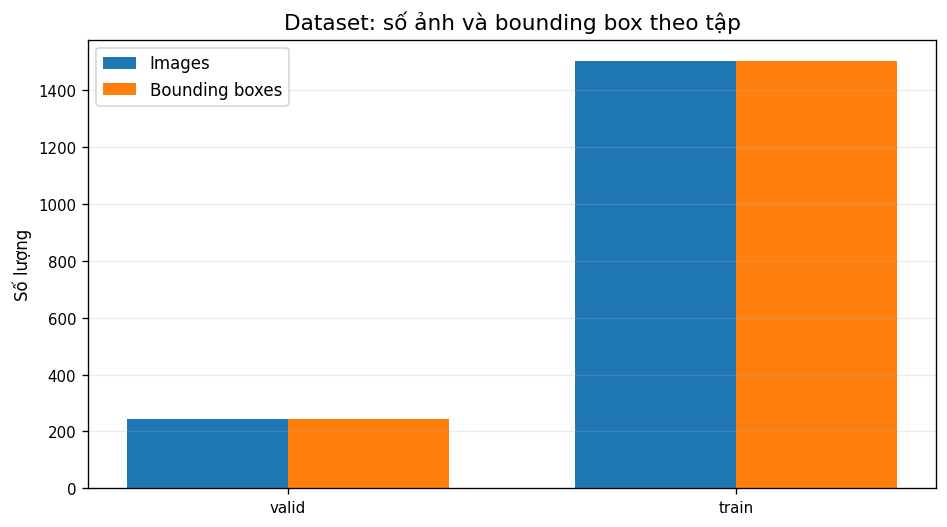

Đã lưu biểu đồ: /content/alpr_matplotlib_report/01_dataset_split.png


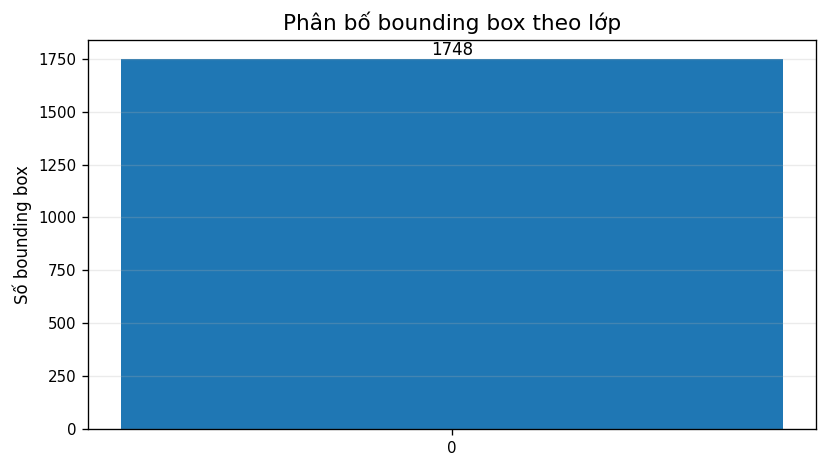

Đã lưu biểu đồ: /content/alpr_matplotlib_report/02_class_distribution.png

[2] HUẤN LUYỆN YOLOv8n THEO EPOCH


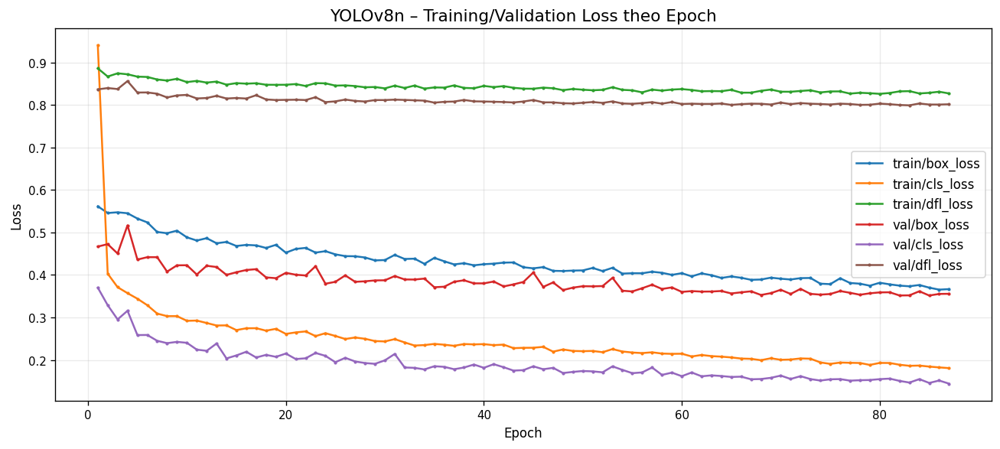

Đã lưu biểu đồ: /content/alpr_matplotlib_report/03_loss_by_epoch.png


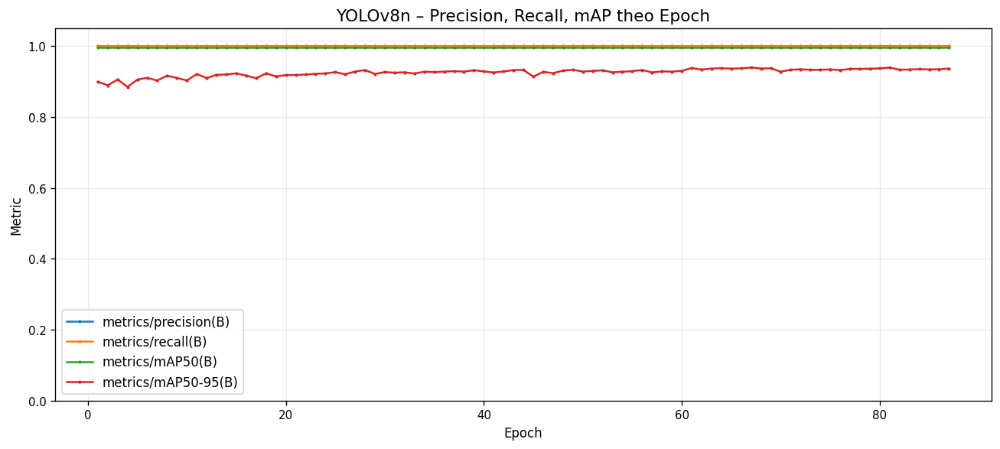

Đã lưu biểu đồ: /content/alpr_matplotlib_report/04_detection_metrics_by_epoch.png

TỔNG HỢP METRIC TỪ results.csv
                         last     best  best_epoch
metrics/precision(B)  0.99977  0.99978        66.0
metrics/recall(B)     1.00000  1.00000         1.0
metrics/mAP50(B)      0.99500  0.99500         1.0
metrics/mAP50-95(B)   0.93642  0.93951        67.0

DÒNG KẾT QUẢ EPOCH CUỐI:
epoch                     87.000000
time                    2203.540000
train/box_loss             0.366590
train/cls_loss             0.180680
train/dfl_loss             0.827240
metrics/precision(B)       0.999770
metrics/recall(B)          1.000000
metrics/mAP50(B)           0.995000
metrics/mAP50-95(B)        0.936420
val/box_loss               0.355610
val/cls_loss               0.144130
val/dfl_loss               0.801690
lr/pg0                     0.000297
lr/pg1                     0.000297
lr/pg2                     0.000297

[3] KẾT QUẢ ĐÁNH GIÁ VALIDATION TỪ CELL 17
Không tìm thấy biến `

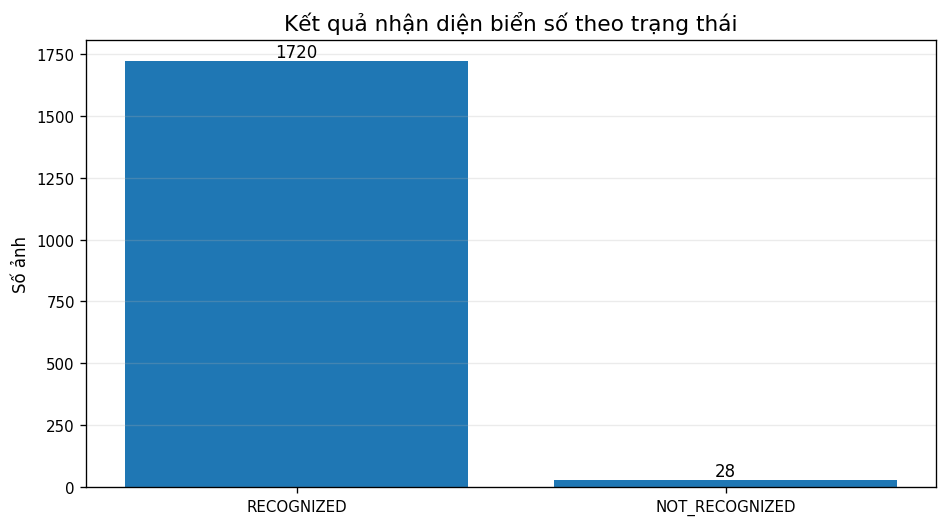

Đã lưu biểu đồ: /content/alpr_matplotlib_report/06_alpr_status.png


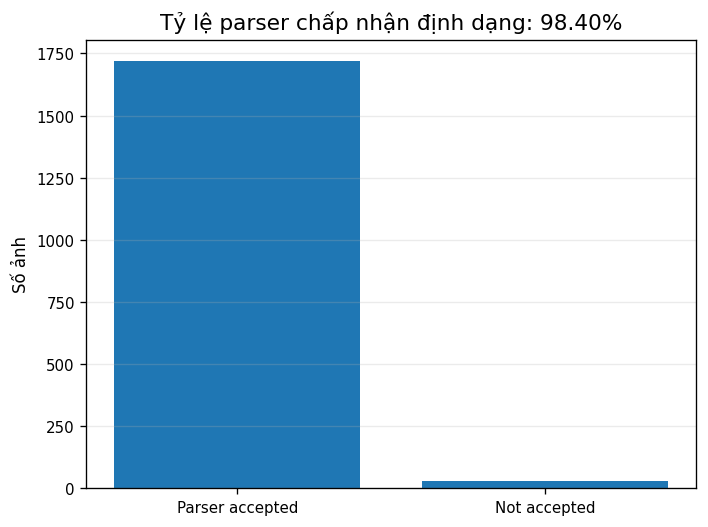

Đã lưu biểu đồ: /content/alpr_matplotlib_report/07_alpr_parser_acceptance.png


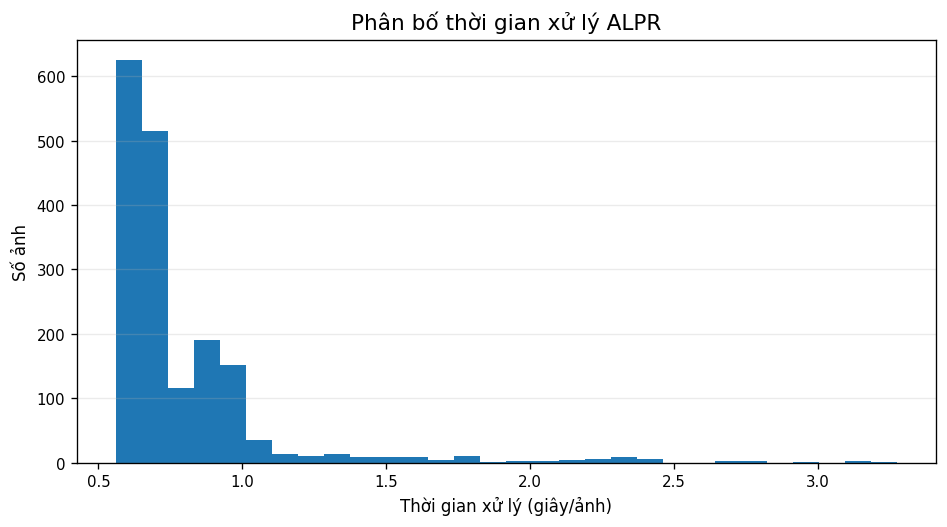

Đã lưu biểu đồ: /content/alpr_matplotlib_report/08_alpr_processing_time.png


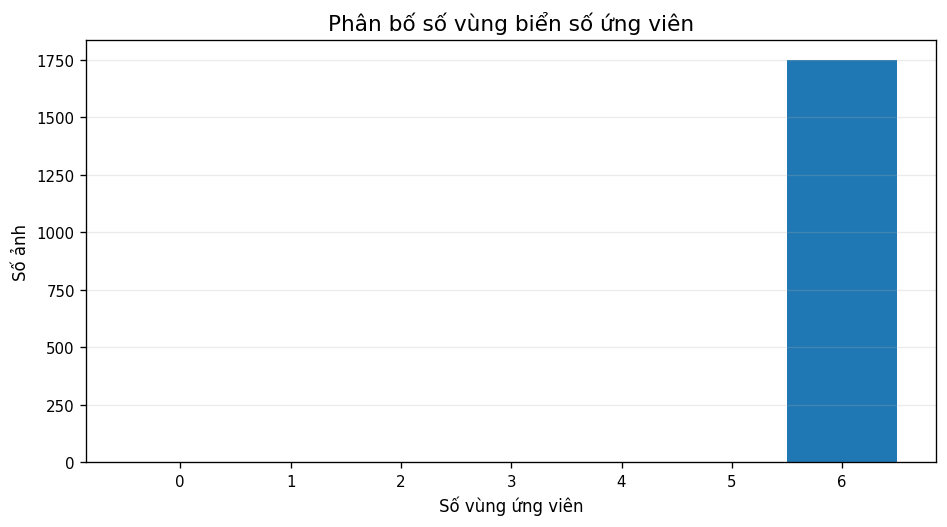

Đã lưu biểu đồ: /content/alpr_matplotlib_report/09_alpr_candidate_counts.png


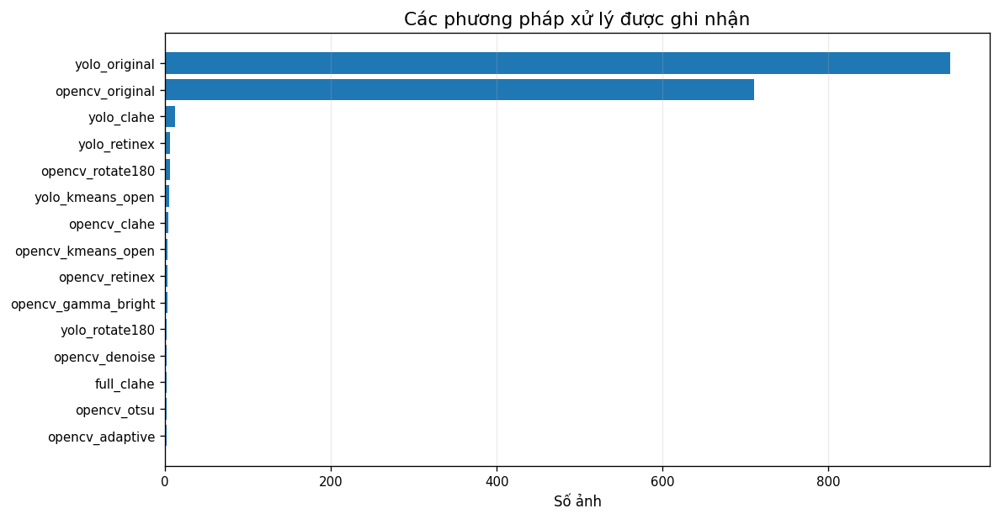

Đã lưu biểu đồ: /content/alpr_matplotlib_report/10_alpr_methods.png
Số trường hợp cần kiểm tra thủ công: 28

HOÀN TẤT XUẤT BIỂU ĐỒ VÀ THỐNG KÊ
Thư mục: /content/alpr_matplotlib_report
Số biểu đồ: 9
 - 01_dataset_split.png
 - 02_class_distribution.png
 - 03_loss_by_epoch.png
 - 04_detection_metrics_by_epoch.png
 - 06_alpr_status.png
 - 07_alpr_parser_acceptance.png
 - 08_alpr_processing_time.png
 - 09_alpr_candidate_counts.png
 - 10_alpr_methods.png
Báo cáo thống kê: /content/alpr_matplotlib_report/summary.txt

Tải toàn bộ kết quả bằng cell Colab:
!cd /content && zip -qr alpr_matplotlib_report.zip alpr_matplotlib_report
from google.colab import files
files.download('/content/alpr_matplotlib_report.zip')


In [7]:
# -*- coding: utf-8 -*-
"""
MATPLOTLIB ANALYSIS – GREENPARKING YOLOv8n + ALPR
Phù hợp trực tiếp với notebook Untitled11.ipynb.

CHẠY SAU KHI:
- Cell 6–13: giải nén, kiểm tra và chuyển COCO -> YOLO.
- Cell 16: huấn luyện YOLOv8n.
- Cell 17: model.val() (để có biến `metrics` trong kernel, nếu dùng %run -i).
- Cell 30: chạy ALPR và tạo plate_ocr_results.csv.

Lệnh chạy trong Colab:
    %run -i /content/matplotlib_report_ALPR.py

Đầu ra:
    /content/alpr_matplotlib_report/
        PNG biểu đồ, CSV thống kê và summary.txt

LƯU Ý:
- Object Detection không có "accuracy" phân loại đơn giản như classification.
  Báo cáo YOLO bằng Precision, Recall, mAP50, mAP50-95.
- Tỷ lệ RECOGNIZED trong CSV ALPR chỉ là tỷ lệ OCR qua bộ kiểm tra định dạng,
  không phải exact-match accuracy vì notebook chưa đối chiếu ground-truth plate text.
"""

from pathlib import Path
from collections import Counter
import json
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------- ĐƯỜNG DẪN ĐÚNG THEO NOTEBOOK --------------------
COCO_ROOT = Path("/content/greenParking_dataset")
YOLO_ROOT = Path("/content/greenParking_yolo")
TRAIN_DIR = Path("/content/alpr_yolo_training/greenparking_yolov8n")
TRAIN_CSV = TRAIN_DIR / "results.csv"
ALPR_CSV = Path("/content/alpr_output/plate_ocr_results.csv")
REPORT_DIR = Path("/content/alpr_matplotlib_report")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Thiết lập hiển thị
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 120,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})


def save_plot(fig, filename):
    path = REPORT_DIR / filename
    fig.tight_layout()
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Đã lưu biểu đồ: {path}")


def find_coco_jsons():
    found = []
    if COCO_ROOT.exists():
        for path in COCO_ROOT.rglob("*.json"):
            try:
                data = json.loads(path.read_text(encoding="utf-8"))
                if all(k in data for k in ("images", "annotations", "categories")):
                    found.append((path, data))
            except Exception:
                continue
    return found


def plot_dataset_statistics(summary_lines):
    print("\n[1] THỐNG KÊ DATASET")
    coco_files = find_coco_jsons()
    if not coco_files:
        print("Không tìm thấy COCO JSON trong", COCO_ROOT)
        return

    split_rows = []
    class_counter = Counter()
    for json_path, data in coco_files:
        # Xác định train/valid từ tên thư mục hoặc đường dẫn
        lower_parts = [p.lower() for p in json_path.parts]
        split = "train" if "train" in lower_parts else (
            "valid" if "valid" in lower_parts or "val" in lower_parts else json_path.parent.name
        )
        split_rows.append({
            "split": split,
            "images": len(data.get("images", [])),
            "annotations": len(data.get("annotations", [])),
            "annotation_file": str(json_path)
        })
        category_names = {
            c["id"]: c.get("name", str(c["id"]))
            for c in data.get("categories", [])
        }
        for ann in data.get("annotations", []):
            class_counter[category_names.get(ann.get("category_id"), str(ann.get("category_id")))] += 1

    split_df = pd.DataFrame(split_rows)
    split_df.to_csv(REPORT_DIR / "dataset_split_statistics.csv", index=False, encoding="utf-8-sig")
    print(split_df[["split", "images", "annotations"]].to_string(index=False))
    summary_lines.append("\nDATASET")
    summary_lines.append(split_df[["split", "images", "annotations"]].to_string(index=False))

    if not split_df.empty:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        x = np.arange(len(split_df))
        width = 0.36
        ax.bar(x - width/2, split_df["images"], width, label="Images")
        ax.bar(x + width/2, split_df["annotations"], width, label="Bounding boxes")
        ax.set_xticks(x, split_df["split"])
        ax.set_ylabel("Số lượng")
        ax.set_title("Dataset: số ảnh và bounding box theo tập")
        ax.legend()
        ax.grid(axis="y", alpha=0.25)
        save_plot(fig, "01_dataset_split.png")

    if class_counter:
        fig, ax = plt.subplots(figsize=(7, 4))
        labels, values = list(class_counter.keys()), list(class_counter.values())
        bars = ax.bar(labels, values)
        ax.set_ylabel("Số bounding box")
        ax.set_title("Phân bố bounding box theo lớp")
        ax.grid(axis="y", alpha=0.25)
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                    str(value), ha="center", va="bottom")
        save_plot(fig, "02_class_distribution.png")


def load_training_results():
    if not TRAIN_CSV.is_file():
        print(f"Không tìm thấy {TRAIN_CSV}. Cần chạy xong cell 16.")
        return None
    df = pd.read_csv(TRAIN_CSV)
    df.columns = [str(c).strip() for c in df.columns]
    if df.empty:
        print("results.csv đang rỗng.")
        return None
    return df


def plot_training_history(summary_lines):
    print("\n[2] HUẤN LUYỆN YOLOv8n THEO EPOCH")
    df = load_training_results()
    if df is None:
        return

    epoch_col = next((c for c in df.columns if c.strip().lower() == "epoch"), None)
    if epoch_col is None:
        df.insert(0, "epoch", np.arange(1, len(df) + 1))
        epoch_col = "epoch"

    epochs = pd.to_numeric(df[epoch_col], errors="coerce")
    loss_cols = [
        c for c in df.columns
        if "loss" in c.lower() and
        (c.lower().startswith("train/") or c.lower().startswith("val/"))
    ]
    metric_cols = [
        c for c in df.columns
        if any(token in c.lower() for token in (
            "metrics/precision", "metrics/recall",
            "metrics/map50", "metrics/map50-95"
        ))
    ]

    # Biểu đồ loss theo epoch
    if loss_cols:
        fig, ax = plt.subplots(figsize=(11, 5))
        for col in loss_cols:
            ax.plot(epochs, pd.to_numeric(df[col], errors="coerce"),
                    marker=".", markersize=3, label=col)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("YOLOv8n – Training/Validation Loss theo Epoch")
        ax.legend()
        ax.grid(alpha=0.25)
        save_plot(fig, "03_loss_by_epoch.png")
    else:
        print("Không thấy cột train/val loss trong results.csv.")

    # Biểu đồ precision, recall, mAP theo epoch
    if metric_cols:
        fig, ax = plt.subplots(figsize=(11, 5))
        for col in metric_cols:
            ax.plot(epochs, pd.to_numeric(df[col], errors="coerce"),
                    marker=".", markersize=3, label=col)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Metric")
        ax.set_ylim(0, 1.05)
        ax.set_title("YOLOv8n – Precision, Recall, mAP theo Epoch")
        ax.legend()
        ax.grid(alpha=0.25)
        save_plot(fig, "04_detection_metrics_by_epoch.png")
    else:
        print("Không thấy cột metrics trong results.csv.")

    # Lưu bảng kết quả từng epoch và thống kê epoch tốt nhất
    df.to_csv(REPORT_DIR / "yolo_epoch_history.csv", index=False, encoding="utf-8-sig")

    summary_lines.append("\nYOLO TRAINING")
    summary_lines.append(f"Số epoch ghi nhận: {len(df)}")
    summary_lines.append(f"Epoch cuối: {epochs.dropna().max() if epochs.notna().any() else 'N/A'}")

    # Các metric mAP / P / R thường có trong Ultralytics results.csv
    preferred = [
        "metrics/precision(B)", "metrics/recall(B)",
        "metrics/mAP50(B)", "metrics/mAP50-95(B)"
    ]
    metric_summary = {}
    for col in preferred:
        if col in df.columns:
            series = pd.to_numeric(df[col], errors="coerce")
            if series.notna().any():
                idx = series.idxmax() if "map" in col.lower() else series.idxmax()
                metric_summary[col] = {
                    "last": float(series.dropna().iloc[-1]),
                    "best": float(series.max()),
                    "best_epoch": int(epochs.loc[idx]) if pd.notna(epochs.loc[idx]) else int(idx + 1)
                }

    if metric_summary:
        summary_df = pd.DataFrame(metric_summary).T
        summary_df.to_csv(REPORT_DIR / "yolo_metric_summary.csv", encoding="utf-8-sig")
        print("\nTỔNG HỢP METRIC TỪ results.csv")
        print(summary_df.to_string())
        summary_lines.append(summary_df.to_string())
    else:
        print("Không trích xuất được metric từ results.csv; kiểm tra tên cột.")
        print("Các cột hiện có:", list(df.columns))

    # In hàng cuối của log huấn luyện
    print("\nDÒNG KẾT QUẢ EPOCH CUỐI:")
    print(df.iloc[-1].to_string())
    summary_lines.append("\nEpoch cuối:\n" + df.iloc[-1].to_string())


def plot_validation_metrics(summary_lines):
    print("\n[3] KẾT QUẢ ĐÁNH GIÁ VALIDATION TỪ CELL 17")
    metric_obj = globals().get("metrics", None)

    if metric_obj is None or not hasattr(metric_obj, "box"):
        print("Không tìm thấy biến `metrics`. Hãy chạy cell 17 trước và dùng %run -i.")
        return

    values = {
        "Precision": float(metric_obj.box.mp),
        "Recall": float(metric_obj.box.mr),
        "mAP50": float(metric_obj.box.map50),
        "mAP50-95": float(metric_obj.box.map),
    }
    values = {k: v for k, v in values.items() if np.isfinite(v)}
    if not values:
        print("Không có metric hợp lệ để vẽ.")
        return

    metric_df = pd.DataFrame(
        [{"metric": k, "value": v} for k, v in values.items()]
    )
    metric_df.to_csv(REPORT_DIR / "yolo_validation_metrics.csv", index=False, encoding="utf-8-sig")

    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(list(values.keys()), list(values.values()))
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Giá trị (0–1)")
    ax.set_title("YOLOv8n – Chỉ số trên tập Validation")
    ax.grid(axis="y", alpha=0.25)
    for bar, val in zip(bars, values.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                f"{val:.4f}", ha="center", va="bottom")
    save_plot(fig, "05_validation_metric_summary.png")

    print(metric_df.to_string(index=False))
    summary_lines.append("\nVALIDATION METRICS\n" + metric_df.to_string(index=False))


def plot_alpr_statistics(summary_lines):
    print("\n[4] THỐNG KÊ KẾT QUẢ NHẬN DIỆN BIỂN SỐ")
    if not ALPR_CSV.is_file():
        print(f"Không tìm thấy {ALPR_CSV}. Hãy chạy cell 30.")
        return

    df = pd.read_csv(ALPR_CSV, encoding="utf-8-sig")
    if df.empty:
        print("CSV ALPR không có bản ghi.")
        return

    # Các cột này được ghi đúng bởi cell 30 của notebook.
    for col in ["status", "processing_seconds", "candidate_count", "method", "plate", "file"]:
        if col not in df.columns:
            df[col] = ""

    df["status"] = df["status"].fillna("").astype(str).str.upper()
    df["processing_seconds"] = pd.to_numeric(df["processing_seconds"], errors="coerce")
    df["candidate_count"] = pd.to_numeric(df["candidate_count"], errors="coerce")

    total = len(df)
    recognized = int((df["status"] == "RECOGNIZED").sum())
    not_recognized = int((df["status"] == "NOT_RECOGNIZED").sum())
    errors = int((df["status"] == "ERROR").sum())
    recognition_rate = 100 * recognized / total if total else 0
    avg_time = df["processing_seconds"].mean()
    median_time = df["processing_seconds"].median()
    throughput = 1 / avg_time if pd.notna(avg_time) and avg_time > 0 else np.nan

    stats = pd.DataFrame([
        ["Tổng số ảnh", total],
        ["Nhận diện được", recognized],
        ["Không nhận diện được", not_recognized],
        ["Lỗi xử lý", errors],
        ["Tỷ lệ parser chấp nhận (%)", recognition_rate],
        ["Thời gian trung bình (giây/ảnh)", avg_time],
        ["Thời gian trung vị (giây/ảnh)", median_time],
        ["Thông lượng tương đương (ảnh/giây)", throughput],
    ], columns=["Chỉ số", "Giá trị"])
    stats.to_csv(REPORT_DIR / "alpr_summary_statistics.csv", index=False, encoding="utf-8-sig")
    print(stats.to_string(index=False))
    summary_lines.append("\nALPR STATISTICS\n" + stats.to_string(index=False))

    # Biểu đồ trạng thái
    status_counts = df["status"].value_counts()
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(status_counts.index.astype(str), status_counts.values)
    ax.set_ylabel("Số ảnh")
    ax.set_title("Kết quả nhận diện biển số theo trạng thái")
    ax.grid(axis="y", alpha=0.25)
    for bar, val in zip(bars, status_counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
                str(val), ha="center", va="bottom")
    save_plot(fig, "06_alpr_status.png")

    # Tỷ lệ parser chấp nhận – không gọi là accuracy exact-match
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.bar(["Parser accepted", "Not accepted"], [recognized, total-recognized])
    ax.set_ylabel("Số ảnh")
    ax.set_title(f"Tỷ lệ parser chấp nhận định dạng: {recognition_rate:.2f}%")
    ax.grid(axis="y", alpha=0.25)
    save_plot(fig, "07_alpr_parser_acceptance.png")

    # Thời gian xử lý
    times = df["processing_seconds"].dropna()
    times = times[times >= 0]
    if len(times):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        ax.hist(times, bins=min(30, max(5, int(np.sqrt(len(times))))))
        ax.set_xlabel("Thời gian xử lý (giây/ảnh)")
        ax.set_ylabel("Số ảnh")
        ax.set_title("Phân bố thời gian xử lý ALPR")
        ax.grid(axis="y", alpha=0.25)
        save_plot(fig, "08_alpr_processing_time.png")

    # Số ứng viên hình học tìm thấy
    candidates = df["candidate_count"].dropna()
    if len(candidates):
        fig, ax = plt.subplots(figsize=(8, 4.5))
        bins = np.arange(-0.5, max(1, int(candidates.max())) + 1.5, 1)
        ax.hist(candidates, bins=bins)
        ax.set_xlabel("Số vùng ứng viên")
        ax.set_ylabel("Số ảnh")
        ax.set_title("Phân bố số vùng biển số ứng viên")
        ax.grid(axis="y", alpha=0.25)
        save_plot(fig, "09_alpr_candidate_counts.png")

    # Phương pháp được ghi trong CSV
    method_counts = df["method"].fillna("").astype(str)
    method_counts = method_counts[method_counts.str.len() > 0].value_counts().head(15)
    if len(method_counts):
        fig, ax = plt.subplots(figsize=(10, max(4, len(method_counts) * 0.35)))
        ax.barh(method_counts.index[::-1], method_counts.values[::-1])
        ax.set_xlabel("Số ảnh")
        ax.set_title("Các phương pháp xử lý được ghi nhận")
        ax.grid(axis="x", alpha=0.25)
        save_plot(fig, "10_alpr_methods.png")

    # Xuất riêng ảnh thất bại để phân tích thủ công
    failed = df[df["status"].isin(["NOT_RECOGNIZED", "ERROR"])]
    failed.to_csv(REPORT_DIR / "alpr_failed_cases.csv", index=False, encoding="utf-8-sig")
    print(f"Số trường hợp cần kiểm tra thủ công: {len(failed)}")


def write_final_report(summary_lines):
    report_file = REPORT_DIR / "summary.txt"
    report_file.write_text("\n".join(summary_lines), encoding="utf-8")
    pngs = sorted(REPORT_DIR.glob("*.png"))
    print("\n" + "=" * 72)
    print("HOÀN TẤT XUẤT BIỂU ĐỒ VÀ THỐNG KÊ")
    print("=" * 72)
    print("Thư mục:", REPORT_DIR)
    print("Số biểu đồ:", len(pngs))
    for p in pngs:
        print(" -", p.name)
    print("Báo cáo thống kê:", report_file)
    print("\nTải toàn bộ kết quả bằng cell Colab:")
    print("!cd /content && zip -qr alpr_matplotlib_report.zip alpr_matplotlib_report")
    print("from google.colab import files")
    print("files.download('/content/alpr_matplotlib_report.zip')")


summary = [
    "BÁO CÁO THỐNG KÊ – GREENPARKING YOLOv8n + ALPR",
    "Nguồn: notebook Untitled11.ipynb",
    "Lưu ý: parser acceptance không phải exact-match accuracy."
]

plot_dataset_statistics(summary)
plot_training_history(summary)
plot_validation_metrics(summary)
plot_alpr_statistics(summary)
write_final_report(summary)


In [8]:
# -*- coding: utf-8 -*-
"""
ALPR evaluation helper for Untitled11(1).ipynb
Run AFTER the main ALPR inference cell (cell 30) with:
    %run -i /content/alpr_evaluation_helper.py

IMPORTANT:
- The COCO annotations in this project contain plate bounding boxes, not plate text.
- Exact Match Accuracy and CER require a manually verified ground_truth.csv.
- Existing valid split is a hold-out validation split, not a fully independent test set.
- To test independently, place unseen images in /content/alpr_test_images and set
  RUN_EXTERNAL_TEST = True below.
"""

from pathlib import Path
from collections import defaultdict, Counter
import os
import re
import json
import time
import hashlib
import math
import warnings

import numpy as np
import pandas as pd

# ============================================================
# 0. SETTINGS
# ============================================================
ALPR_CSV = Path("/content/alpr_output/plate_ocr_results.csv")
EVAL_DIR = Path("/content/alpr_evaluation")
GT_CSV = EVAL_DIR / "ground_truth_valid.csv"
GT_EXTERNAL_CSV = EVAL_DIR / "ground_truth_external_test.csv"
TEST_IMAGE_DIR = Path("/content/alpr_test_images")
EXTERNAL_TEST_CSV = EVAL_DIR / "external_test_results.csv"
COCO_ROOT = Path("/content/greenParking_dataset")

# Set True only after uploading completely unseen images to TEST_IMAGE_DIR.
RUN_EXTERNAL_TEST = False
PREFER_EXTERNAL_TEST = True

# Set True after filling ground_truth.csv to run the controlled comparisons.
RUN_ABLATION = False
MAX_ABLATION_IMAGES = 80  # None = all labeled images; same images are used for each experiment.

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
EVAL_DIR.mkdir(parents=True, exist_ok=True)


def _norm_plate(value):
    """Normalize punctuation/case only. Do not apply OCR character substitutions."""
    if value is None or pd.isna(value):
        return ""
    return re.sub(r"[^A-Z0-9]", "", str(value).upper())


def _path_key(value):
    if value is None or pd.isna(value) or not str(value).strip():
        return ""
    return os.path.normcase(os.path.abspath(os.path.expanduser(str(value).strip())))


def _levenshtein(a, b):
    """Levenshtein edit distance using O(min(len(a), len(b))) memory."""
    if len(a) < len(b):
        a, b = b, a
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(
                current[j - 1] + 1,
                previous[j] + 1,
                previous[j - 1] + (ca != cb)
            ))
        previous = current
    return previous[-1]


def _split_from_path(path):
    parts = [p.lower() for p in Path(str(path)).parts]
    for label in ("train", "valid", "test"):
        if label in parts:
            return label
    if "alpr_test_images" in parts:
        return "test_external"
    return "unknown"


def _write_csv(df, path):
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print("Đã lưu:", path)


def _run_external_test(ns):
    """Run the already-loaded ALPR pipeline over a separate unseen image folder."""
    if not TEST_IMAGE_DIR.is_dir():
        raise FileNotFoundError(
            f"Không có thư mục {TEST_IMAGE_DIR}. Hãy tạo thư mục và tải ảnh Test độc lập vào đó."
        )

    required = ["find_images", "recognize_plate_paddle"]
    missing = [name for name in required if name not in ns]
    if missing:
        raise RuntimeError(
            "Chưa có hàm ALPR trong bộ nhớ: " + ", ".join(missing)
            + ". Hãy chạy cell 30 trước."
        )

    image_paths = ns["find_images"](str(TEST_IMAGE_DIR))
    if not image_paths:
        raise RuntimeError(f"Không tìm thấy ảnh trong {TEST_IMAGE_DIR}.")

    test_annotated = EVAL_DIR / "external_test_annotated"
    test_crops = EVAL_DIR / "external_test_crops"
    test_annotated.mkdir(parents=True, exist_ok=True)
    test_crops.mkdir(parents=True, exist_ok=True)

    keys = ["IMAGE_ROOT", "ANNOTATED_DIR", "CROPS_DIR"]
    old_values = {k: ns.get(k) for k in keys}
    results = []

    try:
        # output_path_for() and recognize_plate_paddle() read these globals.
        ns["IMAGE_ROOT"] = str(TEST_IMAGE_DIR)
        ns["ANNOTATED_DIR"] = str(test_annotated)
        ns["CROPS_DIR"] = str(test_crops)

        print("\nĐANG CHẠY ALPR TRÊN TEST ĐỘC LẬP")
        print("Số ảnh:", len(image_paths))
        for i, image_path in enumerate(image_paths, start=1):
            try:
                rec = ns["recognize_plate_paddle"](str(image_path), show_preview=False)
            except Exception as exc:
                rec = {
                    "file": Path(image_path).name,
                    "path": str(image_path),
                    "candidate_count": 0,
                    "method": "",
                    "raw_text": "",
                    "plate": "",
                    "status": "ERROR",
                    "error": repr(exc),
                    "processing_seconds": 0.0,
                    "annotated_path": "",
                    "rectified_crop_path": ""
                }
            results.append(rec)
            if i % 10 == 0 or i == len(image_paths):
                print(f"Đã xử lý {i}/{len(image_paths)} ảnh")
    finally:
        for key, old_value in old_values.items():
            if old_value is not None:
                ns[key] = old_value

    df_test = pd.DataFrame(results)
    _write_csv(df_test, EXTERNAL_TEST_CSV)
    print("Test inference summary:")
    print(df_test.get("status", pd.Series(dtype=str)).value_counts(dropna=False).to_string())
    return df_test


def _create_ground_truth_template(source_df, source_name, target_gt_csv):
    """Create a manual ground-truth template if none exists yet."""
    df = source_df.copy()
    if "path" not in df.columns:
        raise ValueError("CSV kết quả không có cột 'path'.")
    if "file" not in df.columns:
        df["file"] = df["path"].map(lambda x: Path(str(x)).name)

    df["split"] = df["path"].map(_split_from_path)

    # With no external test, create the first template from validation images only.
    if source_name != "external_test":
        valid_rows = df[df["split"] == "valid"].copy()
        if len(valid_rows):
            df = valid_rows
            print("Tạo Ground Truth từ tập VALID (hold-out validation), không phải Test độc lập.")
        else:
            print("Không nhận ra đường dẫn VALID; tạo template từ toàn bộ kết quả hiện có.")

    template = df[["file", "path", "split"]].copy()
    template["gt_plate"] = ""   # Nhập biển số THỰC TẾ nhìn thấy trong ảnh.
    template["case_type"] = ""  # Gắn nhãn tình huống: thang/nghieng/mo/thieu_sang/loa_sang/che_khuat/xa/xoay/khac.
    template = template.drop_duplicates(subset=["path"]).reset_index(drop=True)
    _write_csv(template, target_gt_csv)
    print("\nĐÃ TẠO FILE NHẬP NHÃN CHUẨN:", target_gt_csv)
    print("Hãy mở CSV và điền:")
    print("  gt_plate : biển số thật, ví dụ 59P1-664.80")
    print("  case_type: thang / nghieng / mo / thieu_sang / loa_sang / che_khuat / xa / xoay / khac")
    print("Không sửa cột file và path. Lưu CSV UTF-8 rồi chạy lại cell này/script này.")
    print("Số ảnh cần gán nhãn:", len(template))


def _evaluate_ground_truth(results_df, gt_df, report_prefix="evaluation"):
    if "path" not in results_df.columns or "path" not in gt_df.columns:
        raise ValueError("Cả hai CSV phải có cột path để ghép đúng ảnh.")

    r = results_df.copy()
    g = gt_df.copy()
    r["_key"] = r["path"].map(_path_key)
    g["_key"] = g["path"].map(_path_key)
    r = r.drop_duplicates(subset=["_key"], keep="last")
    g = g.drop_duplicates(subset=["_key"], keep="last")

    if "gt_plate" not in g.columns:
        raise ValueError("ground_truth.csv cần có cột gt_plate.")
    if "case_type" not in g.columns:
        g["case_type"] = ""

    merged = g.merge(r, on="_key", how="left", suffixes=("_gt", "_pred"))
    if "file_gt" in merged.columns:
        merged["file"] = merged["file_gt"].fillna(merged.get("file_pred"))
    elif "file" not in merged.columns:
        merged["file"] = merged["path_gt"] if "path_gt" in merged.columns else merged["path"]

    merged["gt_norm"] = merged["gt_plate"].map(_norm_plate)
    if "plate" not in merged.columns:
        merged["plate"] = ""
    merged["pred_norm"] = merged["plate"].map(_norm_plate)
    if "status" not in merged.columns:
        merged["status"] = "UNKNOWN"
    merged["status"] = merged["status"].fillna("NO_RESULT").astype(str)

    # Only samples with a manually entered ground-truth plate are scored.
    labeled = merged[merged["gt_norm"] != ""].copy()
    if labeled.empty:
        print("Chưa có nhãn gt_plate. Hãy điền ground_truth.csv rồi chạy lại.")
        print("Không thể tính Exact Match Accuracy/CER chỉ từ OCR prediction.")
        return None

    def classify(row):
        if not row["pred_norm"]:
            return "KHONG_NHAN_DIEN"
        if row["pred_norm"] == row["gt_norm"]:
            return "DUNG"
        return "SAI"

    labeled["evaluation"] = labeled.apply(classify, axis=1)
    labeled["edit_distance"] = labeled.apply(
        lambda x: _levenshtein(x["gt_norm"], x["pred_norm"]), axis=1
    )
    labeled["cer"] = labeled.apply(
        lambda x: x["edit_distance"] / max(1, len(x["gt_norm"])), axis=1
    )

    total = len(labeled)
    correct = int((labeled["evaluation"] == "DUNG").sum())
    wrong = int((labeled["evaluation"] == "SAI").sum())
    not_recognized = int((labeled["evaluation"] == "KHONG_NHAN_DIEN").sum())
    runtime_errors = int((labeled["status"].str.upper() == "ERROR").sum())
    exact_accuracy = 100.0 * correct / total if total else 0.0
    recognized_total = correct + wrong
    accuracy_when_recognized = 100.0 * correct / recognized_total if recognized_total else 0.0
    total_gt_chars = int(labeled["gt_norm"].map(len).sum())
    micro_cer = float(labeled["edit_distance"].sum() / max(1, total_gt_chars))
    mean_cer = float(labeled["cer"].mean())

    summary = pd.DataFrame([
        ["Tổng ảnh có Ground Truth", total],
        ["Nhận diện đúng hoàn toàn", correct],
        ["Nhận diện có kết quả nhưng sai", wrong],
        ["Không nhận diện được", not_recognized],
        ["Trong đó lỗi thực thi (ERROR)", runtime_errors],
        ["Exact Match Accuracy (%)", round(exact_accuracy, 3)],
        ["Accuracy trên các ảnh có OCR output (%)", round(accuracy_when_recognized, 3)],
        ["CER micro (%)", round(micro_cer * 100, 3)],
        ["CER trung bình từng ảnh (%)", round(mean_cer * 100, 3)],
    ], columns=["Chi_so", "Gia_tri"])

    _write_csv(labeled, EVAL_DIR / f"{report_prefix}_per_image.csv")
    _write_csv(summary, EVAL_DIR / f"{report_prefix}_summary.csv")

    print("\n" + "=" * 68)
    print("ĐÁNH GIÁ OCR BẰNG GROUND TRUTH")
    print("=" * 68)
    print(summary.to_string(index=False))
    print("\nCách tính:")
    print("Exact Match Accuracy = số chuỗi trùng hoàn toàn / tổng ảnh đã gán nhãn.")
    print("CER micro = tổng Levenshtein distance / tổng số ký tự Ground Truth.")
    print("Ảnh không nhận diện được được tính là sai trong Exact Match và CER.")

    # Difficult-case breakdown. case_type must be manually assigned in ground_truth.csv.
    labeled["case_type"] = labeled["case_type"].fillna("").replace("", "chua_phan_loai")
    grouped = labeled.groupby("case_type", dropna=False).agg(
        so_anh=("evaluation", "size"),
        dung=("evaluation", lambda s: int((s == "DUNG").sum())),
        sai=("evaluation", lambda s: int((s == "SAI").sum())),
        khong_nhan_dien=("evaluation", lambda s: int((s == "KHONG_NHAN_DIEN").sum())),
        cer_trung_binh=("cer", "mean")
    ).reset_index()
    grouped["exact_match_accuracy_pct"] = 100 * grouped["dung"] / grouped["so_anh"].clip(lower=1)
    grouped["cer_trung_binh_pct"] = 100 * grouped["cer_trung_binh"]
    _write_csv(grouped, EVAL_DIR / f"{report_prefix}_difficult_cases.csv")
    print("\nKẾT QUẢ THEO ĐIỀU KIỆN ẢNH (dựa trên case_type do người dùng gán):")
    print(grouped.drop(columns=["cer_trung_binh"]).round(3).to_string(index=False))

    return labeled


def _analyze_failures(all_results):
    df = all_results.copy()
    for col, default in [("status", "UNKNOWN"), ("candidate_count", 0), ("plate", ""), ("raw_text", ""), ("error", "")]:
        if col not in df.columns:
            df[col] = default
    df["plate_norm"] = df["plate"].map(_norm_plate)

    def reason(row):
        status = str(row["status"]).upper()
        if status == "ERROR":
            return "Lỗi thực thi/đọc ảnh"
        if row["plate_norm"]:
            return "Có kết quả OCR (cần đối chiếu Ground Truth)"
        try:
            count = int(float(row["candidate_count"]))
        except Exception:
            count = 0
        if count <= 0:
            return "Không tìm thấy vùng biển số ứng viên"
        return "Có vùng ứng viên nhưng OCR/parser không chấp nhận"

    df["failure_reason"] = df.apply(reason, axis=1)
    failed = df[df["status"].astype(str).str.upper().isin(["NOT_RECOGNIZED", "ERROR"])].copy()
    reason_summary = failed.groupby("failure_reason").size().reset_index(name="so_anh")
    _write_csv(failed, EVAL_DIR / "failed_cases_all.csv")
    _write_csv(reason_summary, EVAL_DIR / "failed_reason_summary.csv")
    print("\nPHÂN TÍCH ẢNH THẤT BẠI")
    print("Tổng NOT_RECOGNIZED + ERROR:", len(failed))
    if len(reason_summary):
        print(reason_summary.to_string(index=False))
    if len(failed):
        show_cols = [c for c in ["file", "path", "status", "candidate_count", "raw_text", "error", "failure_reason"] if c in failed]
        print("\nDanh sách ảnh thất bại (lưu đầy đủ trong failed_cases_all.csv):")
        print(failed[show_cols].head(50).to_string(index=False))
    return failed


def _analyze_speed(results_df, report_prefix="speed"):
    if "processing_seconds" not in results_df.columns:
        print("CSV không có processing_seconds; bỏ qua phân tích tốc độ.")
        return None
    values = pd.to_numeric(results_df["processing_seconds"], errors="coerce").dropna()
    values = values[values >= 0]
    if values.empty:
        print("Không có processing_seconds hợp lệ.")
        return None
    mean_s = float(values.mean())
    stats = pd.DataFrame([
        ["Số ảnh", len(values)],
        ["Trung bình (giây/ảnh)", mean_s],
        ["Trung vị (giây/ảnh)", float(values.median())],
        ["P95 (giây/ảnh)", float(values.quantile(0.95))],
        ["Nhanh nhất (giây/ảnh)", float(values.min())],
        ["Chậm nhất (giây/ảnh)", float(values.max())],
        ["Thông lượng trung bình (ảnh/giây)", 1.0 / mean_s if mean_s > 0 else np.nan],
    ], columns=["Chi_so", "Gia_tri"])
    _write_csv(stats, EVAL_DIR / f"{report_prefix}_summary.csv")
    print("\nPHÂN TÍCH TỐC ĐỘ TOÀN PIPELINE")
    print(stats.to_string(index=False))
    print("Lưu ý: processing_seconds hiện đo tổng pipeline/ảnh; chưa tách riêng YOLO, OpenCV và OCR.")
    return stats


def _analyze_dataset_quality():
    if not COCO_ROOT.is_dir():
        print("Không tìm thấy dataset COCO:", COCO_ROOT)
        return None

    annotation_files = sorted(COCO_ROOT.rglob("_annotations.coco.json"))
    if not annotation_files:
        print("Không tìm thấy _annotations.coco.json trong", COCO_ROOT)
        return None

    image_index = defaultdict(list)
    for p in COCO_ROOT.rglob("*"):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
            image_index[p.name.lower()].append(p)

    split_rows = []
    box_rows = []
    image_rows = []
    hash_splits = defaultdict(set)

    for ann_path in annotation_files:
        split = ann_path.parent.name.lower()
        try:
            coco = json.loads(ann_path.read_text(encoding="utf-8"))
        except Exception as exc:
            print("Không đọc được annotation:", ann_path, repr(exc))
            continue

        images = coco.get("images", [])
        annotations = coco.get("annotations", [])
        categories = {c.get("id"): c.get("name", str(c.get("id"))) for c in coco.get("categories", [])}
        ann_by_image = defaultdict(list)
        for ann in annotations:
            ann_by_image[ann.get("image_id")].append(ann)

        missing_images = 0
        empty_annotation_images = 0
        invalid_boxes = 0
        valid_boxes = 0
        resolved_paths = []

        for im in images:
            file_name = str(im.get("file_name", ""))
            candidates = [ann_path.parent / file_name, COCO_ROOT / split / file_name, COCO_ROOT / file_name]
            resolved = next((p for p in candidates if p.is_file()), None)
            if resolved is None:
                matches = image_index.get(Path(file_name).name.lower(), [])
                split_matches = [p for p in matches if split in [x.lower() for x in p.parts]]
                if len(split_matches) == 1:
                    resolved = split_matches[0]
                elif len(matches) == 1:
                    resolved = matches[0]

            if resolved is None:
                missing_images += 1
                continue
            resolved_paths.append(resolved)
            if not ann_by_image.get(im.get("id")):
                empty_annotation_images += 1

            image = cv2.imread(str(resolved))
            if image is not None:
                h, w = image.shape[:2]
                gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
                brightness = float(gray.mean())
                blur_var = float(cv2.Laplacian(gray, cv2.CV_64F).var())
                sha = hashlib.sha256(resolved.read_bytes()).hexdigest()
                hash_splits[sha].add(split)
                image_rows.append({
                    "split": split, "file": resolved.name, "path": str(resolved),
                    "width": w, "height": h, "brightness_mean": brightness,
                    "laplacian_variance": blur_var, "sha256": sha,
                    "possible_low_light_lt_50": brightness < 50,
                    "possible_blur_lt_50": blur_var < 50
                })

            for ann in ann_by_image.get(im.get("id"), []):
                bbox = ann.get("bbox", [])
                ok = False
                if len(bbox) == 4:
                    x, y, bw, bh = map(float, bbox)
                    iw = float(im.get("width") or (image.shape[1] if image is not None else 0))
                    ih = float(im.get("height") or (image.shape[0] if image is not None else 0))
                    ok = (bw > 0 and bh > 0 and x >= 0 and y >= 0 and iw > 0 and ih > 0
                          and x + bw <= iw + 2 and y + bh <= ih + 2)
                    if ok:
                        valid_boxes += 1
                        box_rows.append({
                            "split": split,
                            "category": categories.get(ann.get("category_id"), "unknown"),
                            "box_width_fraction": bw / iw,
                            "box_height_fraction": bh / ih,
                            "box_aspect_ratio": bw / bh,
                            "box_area_fraction": (bw * bh) / (iw * ih)
                        })
                if not ok:
                    invalid_boxes += 1

        split_rows.append({
            "split": split,
            "images_declared": len(images),
            "images_resolved": len(resolved_paths),
            "images_missing": missing_images,
            "images_without_bbox": empty_annotation_images,
            "annotations": len(annotations),
            "valid_bboxes": valid_boxes,
            "invalid_bboxes": invalid_boxes,
            "categories": "; ".join(sorted({str(v) for v in categories.values()}))
        })

    split_df = pd.DataFrame(split_rows)
    img_df = pd.DataFrame(image_rows)
    box_df = pd.DataFrame(box_rows)

    if not split_df.empty:
        _write_csv(split_df, EVAL_DIR / "dataset_quality_by_split.csv")
    if not img_df.empty:
        # These are heuristic flags, not authoritative ground-truth labels for blur/lighting.
        _write_csv(img_df, EVAL_DIR / "dataset_image_quality.csv")
    if not box_df.empty:
        _write_csv(box_df, EVAL_DIR / "dataset_bbox_geometry.csv")

    duplicate_hashes = {h: s for h, s in hash_splits.items() if len(s) > 1}

    # Exact-byte duplicate check between an optional external test folder and Train/Valid.
    external_overlap = []
    if TEST_IMAGE_DIR.is_dir():
        dataset_hash_set = set(hash_splits.keys())
        for test_path in TEST_IMAGE_DIR.rglob("*"):
            if not test_path.is_file() or test_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue
            try:
                test_hash = hashlib.sha256(test_path.read_bytes()).hexdigest()
                external_overlap.append({
                    "test_file": test_path.name,
                    "test_path": str(test_path),
                    "duplicate_of_train_or_valid": test_hash in dataset_hash_set,
                    "sha256": test_hash
                })
            except Exception as exc:
                external_overlap.append({
                    "test_file": test_path.name,
                    "test_path": str(test_path),
                    "duplicate_of_train_or_valid": "HASH_ERROR",
                    "sha256": repr(exc)
                })
    overlap_df = pd.DataFrame(external_overlap)
    if not overlap_df.empty:
        _write_csv(overlap_df, EVAL_DIR / "external_test_leakage_check.csv")

    duplicate_summary = pd.DataFrame([
        ["Số ảnh đã đọc được và tính hash", len(img_df)],
        ["Số hash xuất hiện ở nhiều split Train/Valid", len(duplicate_hashes)],
        ["Số ảnh Test ngoài trùng byte với Train/Valid", int((overlap_df["duplicate_of_train_or_valid"] == True).sum()) if not overlap_df.empty else 0],
        ["Số bbox không hợp lệ", int(split_df["invalid_bboxes"].sum()) if not split_df.empty else 0],
        ["Số ảnh không tìm thấy file", int(split_df["images_missing"].sum()) if not split_df.empty else 0],
        ["Số ảnh không có bbox", int(split_df["images_without_bbox"].sum()) if not split_df.empty else 0],
        ["Ảnh có brightness trung bình < 50 (heuristic)", int(img_df["possible_low_light_lt_50"].sum()) if not img_df.empty else 0],
        ["Ảnh có Laplacian variance < 50 (heuristic blur)", int(img_df["possible_blur_lt_50"].sum()) if not img_df.empty else 0],
    ], columns=["Chi_so", "Gia_tri"])
    _write_csv(duplicate_summary, EVAL_DIR / "dataset_quality_summary.csv")

    print("\nPHÂN TÍCH CHẤT LƯỢNG DATASET COCO")
    print(split_df.to_string(index=False) if not split_df.empty else "Không có dữ liệu split.")
    print("\nTÓM TẮT CHẤT LƯỢNG:")
    print(duplicate_summary.to_string(index=False))
    if duplicate_hashes:
        print("CẢNH BÁO: Có ảnh trùng hash giữa các split Train/Valid.")
    if not overlap_df.empty and (overlap_df["duplicate_of_train_or_valid"] == True).any():
        print("CẢNH BÁO: Một số ảnh external Test trùng byte với Train/Valid; cần loại khỏi Test độc lập.")
    print("Chỉ số blur/ánh sáng là ngưỡng tham khảo, cần xem ảnh thủ công trước khi kết luận.")
    return split_df


def _run_ablation(ns, labeled_df):
    """Compare full system, OpenCV-only localization, and no image enhancement."""
    required = ["recognize_plate_paddle", "find_images", "locate_plate_candidates_hybrid",
                "locate_plate_candidates", "make_plate_ocr_variants", "make_full_image_variants"]
    missing = [name for name in required if name not in ns]
    if missing:
        raise RuntimeError("Thiếu hàm để chạy ablation: " + ", ".join(missing))

    eval_rows = labeled_df[labeled_df["gt_norm"] != ""].copy()
    paths = [str(p) for p in eval_rows["path_gt" if "path_gt" in eval_rows.columns else "path"].tolist()]
    paths = [p for p in paths if os.path.isfile(p)]
    if not paths:
        print("Không có đường dẫn ảnh còn tồn tại để chạy ablation.")
        return None

    # Deterministic common subset. All three variants run on these exact same images.
    if MAX_ABLATION_IMAGES is not None and len(paths) > MAX_ABLATION_IMAGES:
        rng = np.random.RandomState(42)
        chosen = sorted(rng.choice(len(paths), size=int(MAX_ABLATION_IMAGES), replace=False).tolist())
        paths = [paths[i] for i in chosen]

    old = {k: ns.get(k) for k in ["IMAGE_ROOT", "ANNOTATED_DIR", "CROPS_DIR",
                                   "locate_plate_candidates_hybrid", "make_plate_ocr_variants",
                                   "make_full_image_variants", "MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE"]}
    original_hybrid = ns["locate_plate_candidates_hybrid"]
    original_plate_variants = ns["make_plate_ocr_variants"]
    original_full_variants = ns["make_full_image_variants"]

    gt_map = {}
    path_col = "path_gt" if "path_gt" in eval_rows.columns else "path"
    for _, row in eval_rows.iterrows():
        gt_map[_path_key(row[path_col])] = _norm_plate(row["gt_plate"])

    common_root = os.path.commonpath(paths)
    if os.path.isfile(common_root):
        common_root = os.path.dirname(common_root)

    experiments = ["full_system", "opencv_only", "ocr_no_variants"]
    all_records = []

    try:
        ns["IMAGE_ROOT"] = common_root
        for experiment in experiments:
            ns["ANNOTATED_DIR"] = str(EVAL_DIR / f"ablation_{experiment}_annotated")
            ns["CROPS_DIR"] = str(EVAL_DIR / f"ablation_{experiment}_crops")
            Path(ns["ANNOTATED_DIR"]).mkdir(parents=True, exist_ok=True)
            Path(ns["CROPS_DIR"]).mkdir(parents=True, exist_ok=True)

            # Restore originals before configuring each run.
            ns["locate_plate_candidates_hybrid"] = original_hybrid
            ns["make_plate_ocr_variants"] = original_plate_variants
            ns["make_full_image_variants"] = original_full_variants
            if old.get("MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE") is not None:
                ns["MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE"] = old["MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE"]

            if experiment == "opencv_only":
                ns["locate_plate_candidates_hybrid"] = lambda image, max_candidates=None: ns["locate_plate_candidates"](
                    image,
                    max_candidates=(max_candidates if max_candidates is not None else ns.get("MAX_PLATE_CANDIDATES", 6))
                )
            elif experiment == "ocr_no_variants":
                ns["make_plate_ocr_variants"] = lambda crop: {"original": crop}
                ns["make_full_image_variants"] = lambda image: {
                    "full_clahe": image,
                    "full_gamma_dark": image,
                    "full_red_suppressed": image,
                    "full_retinex": image
                }
                ns["MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE"] = 0

            print(f"\nABlation: {experiment} | {len(paths)} images")
            for i, path in enumerate(paths, start=1):
                try:
                    rec = ns["recognize_plate_paddle"](path, show_preview=False)
                except Exception as exc:
                    rec = {
                        "file": Path(path).name, "path": path, "plate": "", "status": "ERROR",
                        "candidate_count": 0, "raw_text": "", "method": "", "error": repr(exc),
                        "processing_seconds": 0.0
                    }
                rec["experiment"] = experiment
                all_records.append(rec)
                if i % 10 == 0 or i == len(paths):
                    print(f"  {i}/{len(paths)}")
    finally:
        for key, value in old.items():
            if value is not None:
                ns[key] = value

    ab_df = pd.DataFrame(all_records)
    _write_csv(ab_df, EVAL_DIR / "ablation_raw_results.csv")

    metric_rows = []
    for experiment, part in ab_df.groupby("experiment"):
        correct = wrong = no_output = 0
        total_distance = total_chars = 0
        for _, row in part.iterrows():
            gt = gt_map.get(_path_key(row.get("path", "")), "")
            pred = _norm_plate(row.get("plate", ""))
            if not gt:
                continue
            total_chars += len(gt)
            dist = _levenshtein(gt, pred)
            total_distance += dist
            if not pred:
                no_output += 1
            elif pred == gt:
                correct += 1
            else:
                wrong += 1
        denom = correct + wrong + no_output
        metric_rows.append({
            "experiment": experiment,
            "labeled_images": denom,
            "correct": correct,
            "wrong_ocr": wrong,
            "not_recognized": no_output,
            "exact_match_accuracy_pct": 100 * correct / denom if denom else np.nan,
            "cer_micro_pct": 100 * total_distance / max(1, total_chars)
        })
    metric_df = pd.DataFrame(metric_rows)
    _write_csv(metric_df, EVAL_DIR / "ablation_comparison.csv")
    print("\nSO SÁNH CÁC PHƯƠNG PHÁP (cùng một tập ảnh):")
    print(metric_df.round(3).to_string(index=False))
    print("Lưu ý: đây là ablation thực nghiệm; so sánh phải dùng cùng ảnh và cùng Ground Truth.")
    return metric_df


def main():
    ns = globals()
    print("ALPR evaluation helper starting...")

    # Optionally process a truly independent external test folder.
    if RUN_EXTERNAL_TEST:
        _run_external_test(ns)

    if PREFER_EXTERNAL_TEST and EXTERNAL_TEST_CSV.is_file():
        results_path = EXTERNAL_TEST_CSV
        results_source = "external_test"
    else:
        results_path = ALPR_CSV
        results_source = "existing_results"

    if not results_path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy {results_path}. Hãy chạy cell 30 để tạo plate_ocr_results.csv."
        )

    results_df = pd.read_csv(results_path, keep_default_na=False)
    print("Nguồn kết quả ALPR:", results_path)
    print("Số dòng:", len(results_df))

    # Keep separate label files for VALID and truly external TEST sets.
    active_gt_csv = GT_EXTERNAL_CSV if results_source == "external_test" else GT_CSV

    # Create manual ground-truth file on first run, then stop here for user annotation.
    if not active_gt_csv.is_file():
        _create_ground_truth_template(results_df, results_source, active_gt_csv)
        print("\nCHƯA TÍNH EXACT MATCH/CER: cần nhập biển số thật vào file Ground Truth vừa tạo.")
        print("Các phần không cần Ground Truth vẫn được thống kê ở lần chạy này.")
        _analyze_failures(results_df)
        _analyze_speed(results_df, report_prefix=("external_test_speed" if results_source == "external_test" else "all_images_speed"))
        _analyze_dataset_quality()
        return

    gt_df = pd.read_csv(active_gt_csv, keep_default_na=False)
    labeled_df = _evaluate_ground_truth(results_df, gt_df, report_prefix=("external_test" if results_source == "external_test" else "valid"))

    # Failure analysis and latency can be measured without manually transcribing all images.
    _analyze_failures(results_df)
    _analyze_speed(results_df, report_prefix=("external_test_speed" if results_source == "external_test" else "all_images_speed"))
    _analyze_dataset_quality()

    if RUN_ABLATION and labeled_df is not None:
        _run_ablation(ns, labeled_df)
    elif not RUN_ABLATION:
        print("\nSo sánh từng phương pháp đang tắt. Đổi RUN_ABLATION = True ở đầu file rồi chạy lại để chạy 3 thử nghiệm.")

    print("\nHOÀN TẤT. Tất cả báo cáo được lưu tại:", EVAL_DIR)
    print("Các file chính:")
    for name in [
        "ground_truth_valid.csv", "ground_truth_external_test.csv",
        "valid_per_image.csv", "valid_summary.csv", "valid_difficult_cases.csv",
        "failed_cases_all.csv", "failed_reason_summary.csv",
        "all_images_speed_summary.csv", "dataset_quality_summary.csv",
        "dataset_quality_by_split.csv", "dataset_image_quality.csv", "dataset_bbox_geometry.csv",
        "ablation_comparison.csv"
    ]:
        p = EVAL_DIR / name
        if p.exists():
            print(" -", p)


main()


ALPR evaluation helper starting...
Nguồn kết quả ALPR: /content/alpr_output/plate_ocr_results.csv
Số dòng: 1748
Tạo Ground Truth từ tập VALID (hold-out validation), không phải Test độc lập.
Đã lưu: /content/alpr_evaluation/ground_truth_valid.csv

ĐÃ TẠO FILE NHẬP NHÃN CHUẨN: /content/alpr_evaluation/ground_truth_valid.csv
Hãy mở CSV và điền:
  gt_plate : biển số thật, ví dụ 59P1-664.80
  case_type: thang / nghieng / mo / thieu_sang / loa_sang / che_khuat / xa / xoay / khac
Không sửa cột file và path. Lưu CSV UTF-8 rồi chạy lại cell này/script này.
Số ảnh cần gán nhãn: 245

CHƯA TÍNH EXACT MATCH/CER: cần nhập biển số thật vào file Ground Truth vừa tạo.
Các phần không cần Ground Truth vẫn được thống kê ở lần chạy này.
Đã lưu: /content/alpr_evaluation/failed_cases_all.csv
Đã lưu: /content/alpr_evaluation/failed_reason_summary.csv

PHÂN TÍCH ẢNH THẤT BẠI
Tổng NOT_RECOGNIZED + ERROR: 28
                                   failure_reason  so_anh
Có vùng ứng viên nhưng OCR/parser không chấp nh

In [ ]:
#nén để đi công việc
import os
import zipfile

# Tên file zip output
output_zip = 'full_backup.zip'

# Danh sách bỏ qua (không cần nén)
exclude_files = [output_zip]
exclude_dirs = ['sample_data', '.config', '.ipynb_checkpoints']

with zipfile.ZipFile(output_zip, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk('.'):
        # Lọc bỏ thư mục không muốn nén
        dirs[:] = [d for d in dirs if d not in exclude_dirs]

        for file in files:
            if file in exclude_files or file.endswith('.zip'):
                continue
            file_path = os.path.join(root, file)
            # Giữ nguyên cấu trúc đường dẫn tương đối
            arcname = os.path.relpath(file_path, '.')
            zipf.write(file_path, arcname)

print("✅ Đã nén thành công tất cả dữ liệu vào file:", output_zip)

✅ Đã nén thành công tất cả dữ liệu vào file: full_backup.zip


In [ ]:
#tải xuống trình duyệt
from google.colab import files

files.download('full_backup.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!unzip -o full_backup.zip

Kết quả truyền trực tuyến bị cắt bớt đến 5000 dòng cuối.
  inflating: alpr_output/annotated_images/train/greenpack_0179_png.rf.46af72c730ff37eae1e9931abe882e5f.jpg  
  inflating: alpr_output/annotated_images/train/greenpack_0600_png.rf.d20f22bf036f7478c928c8eae6775bc3.jpg  
  inflating: alpr_output/annotated_images/train/0420_04686_b_jpg.rf.9e4c13b0740920f6c2d6bc61765fc638.jpg  
  inflating: alpr_output/annotated_images/train/carlong_0170_png.rf.14d481dc076deb5334db1bad8e217985.jpg  
  inflating: alpr_output/annotated_images/train/0249_08308_b_jpg.rf.fd864ef8c50bdf5c1e90491da1e15a08.jpg  
  inflating: alpr_output/annotated_images/train/greenpack_1745_png.rf.1f4b15f3c461c781bf8efd5791bae68c.jpg  
  inflating: alpr_output/annotated_images/train/carlong_0968_png.rf.186a0cb7bb62c37a5cc38f55e31da472.jpg  
  inflating: alpr_output/annotated_images/train/greenpack_1069_png.rf.cb6441cfd793153bb7bf155739534acb.jpg  
  inflating: alpr_output/annotated_images/train/greenpack_0117_png.rf.98768fe6e

In [ ]:
import zipfile

# Tên file zip (hoặc đường dẫn đầy đủ nếu bạn để ở thư mục khác)
zip_path = '/content/Computer Vision.v2i.coco.zip'
# Thư mục đích muốn giải nén ra
extract_path = './dataset_coco'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
    print("Đã giải nén thành công!")

Đã giải nén thành công!


Đã tìm thấy dataset đã giải nén; bỏ qua bước giải nén ZIP.
Dataset ZIP: /content/dataset_coco.zip
Image root: /content/dataset_coco
Output root: /content/alpr_output

INITIALIZING PADDLEOCR
PaddlePaddle: 3.2.0
CUDA compiled: True
GPU count: 1
OCR device: gpu:0
Reusing the PaddleOCR instance already initialized in this notebook.
YOLO ONNX loaded: /content/license_plate_yolov8n.onnx

SCANNING DATASET IMAGES
Input root: /content/dataset_coco
Images selected: 4434
YOLO active: True
OCR device: gpu:0

STARTING PLATE LOCALIZATION + OCR


ALPR:   0%|          | 0/4434 [00:00<?, ?image/s]

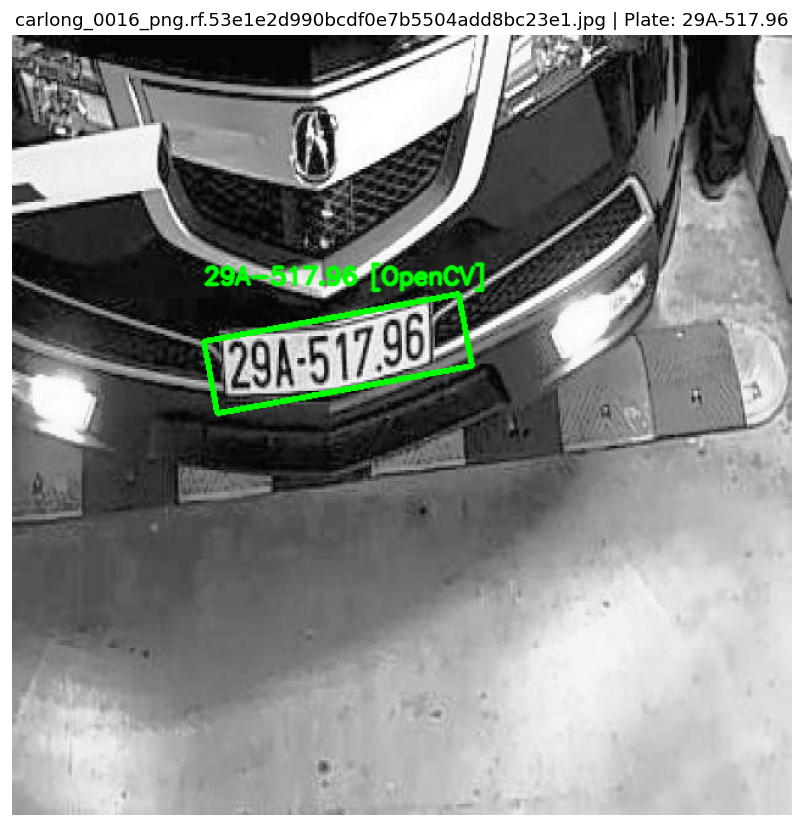

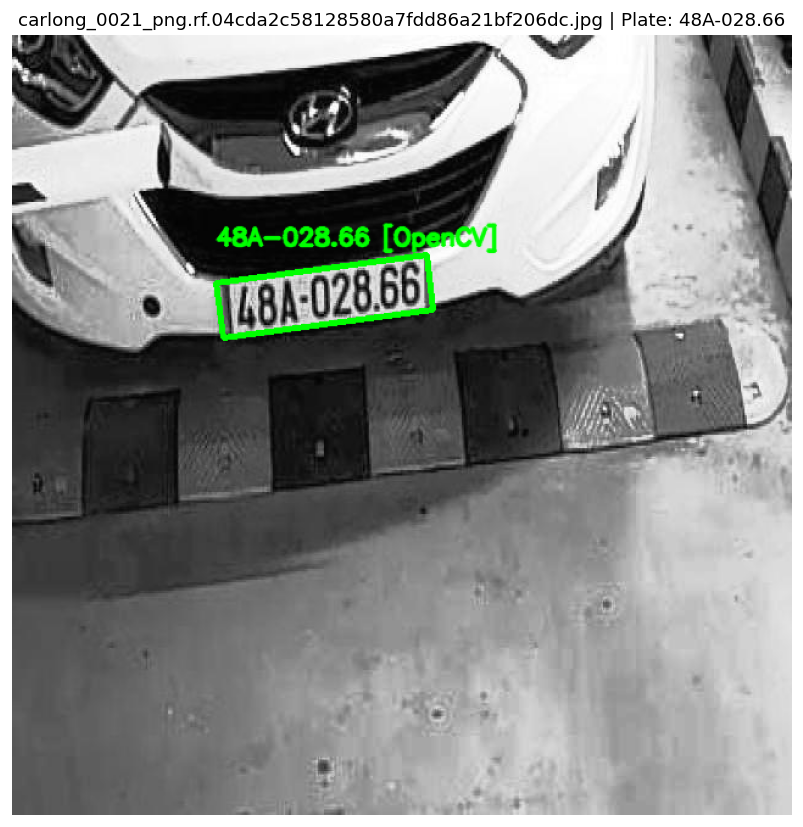

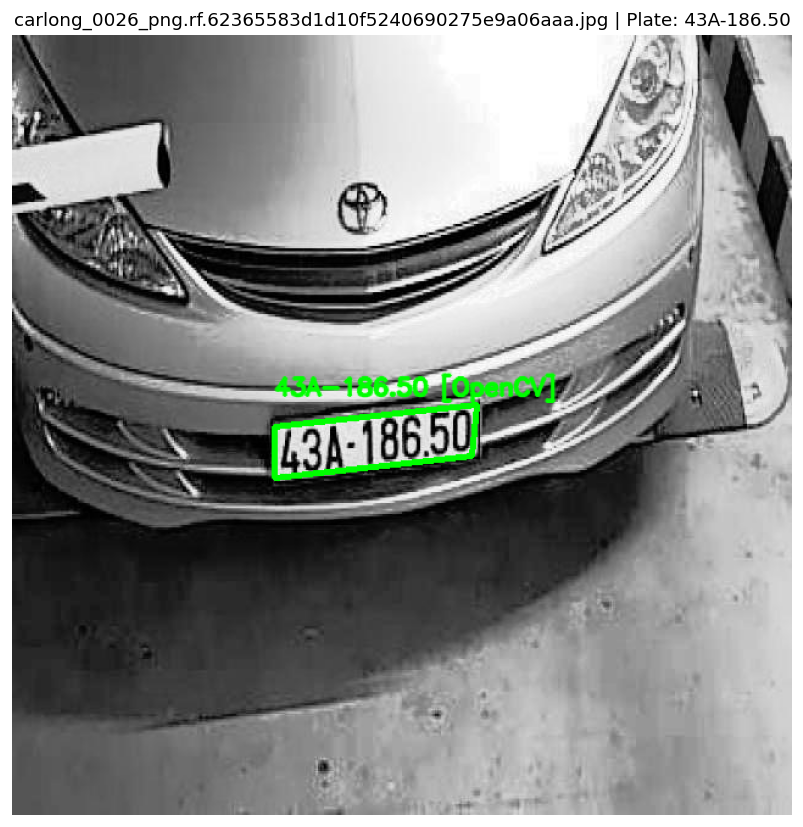

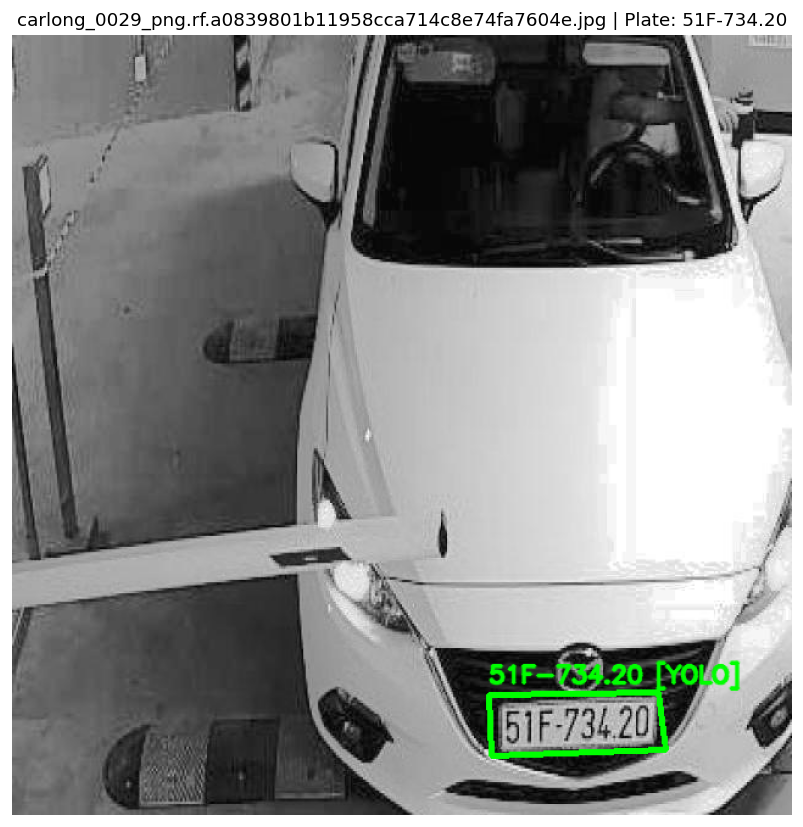

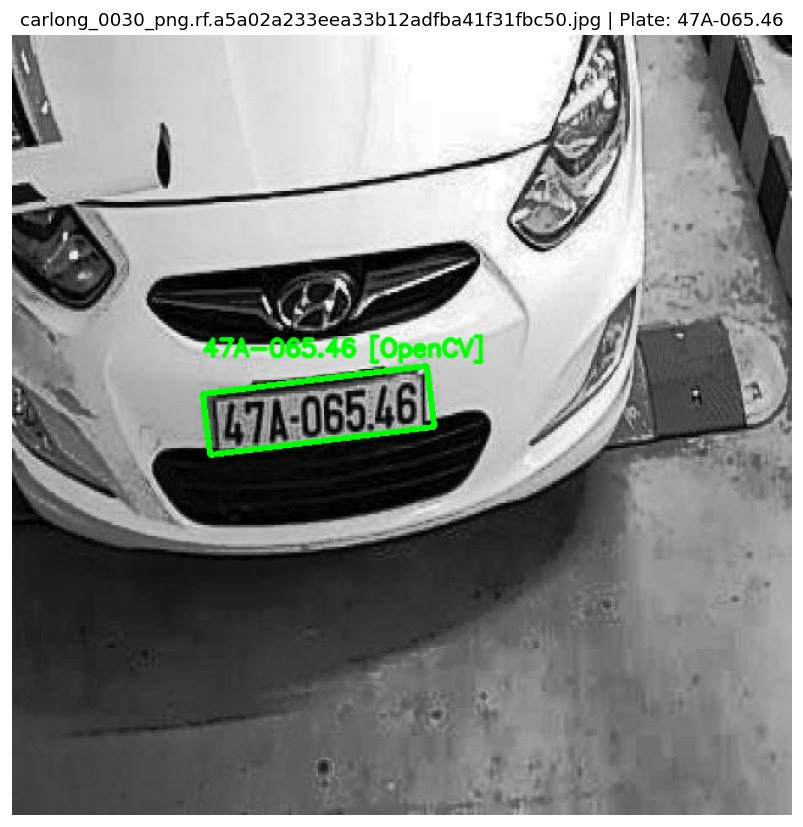

...

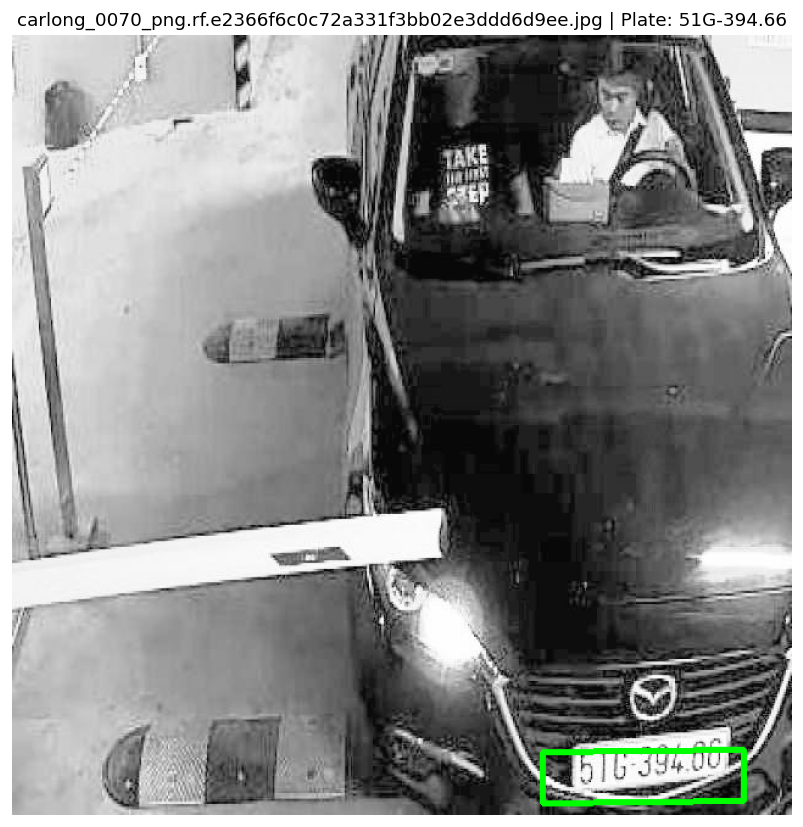

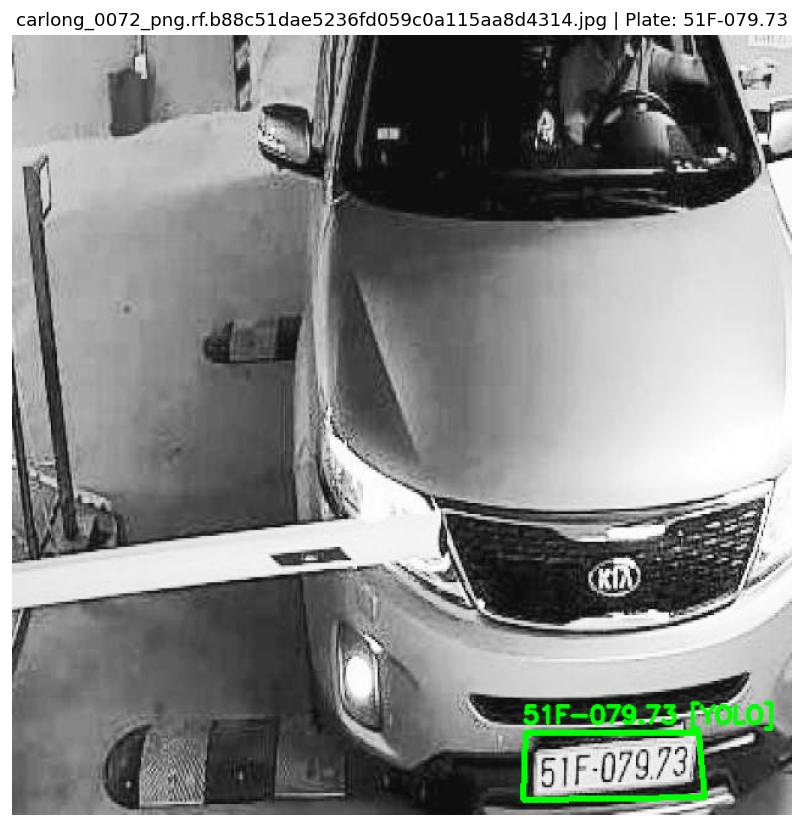

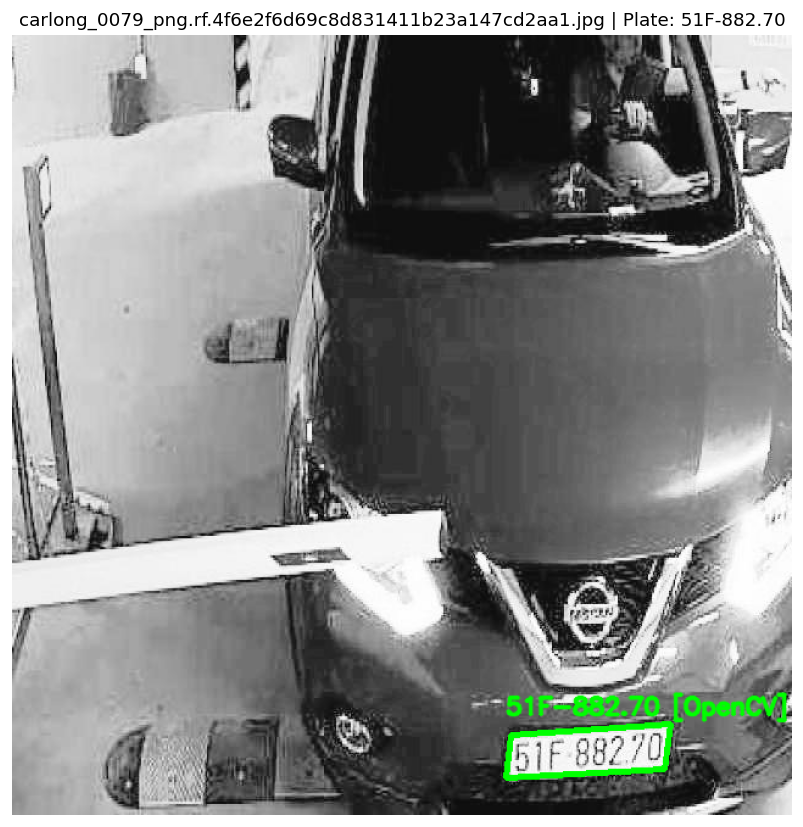

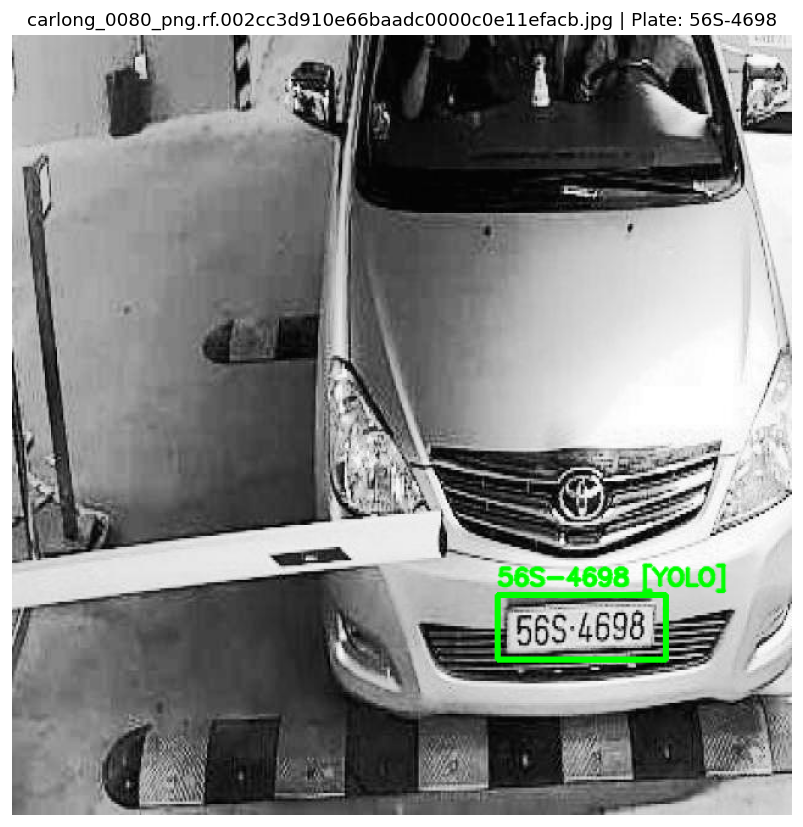

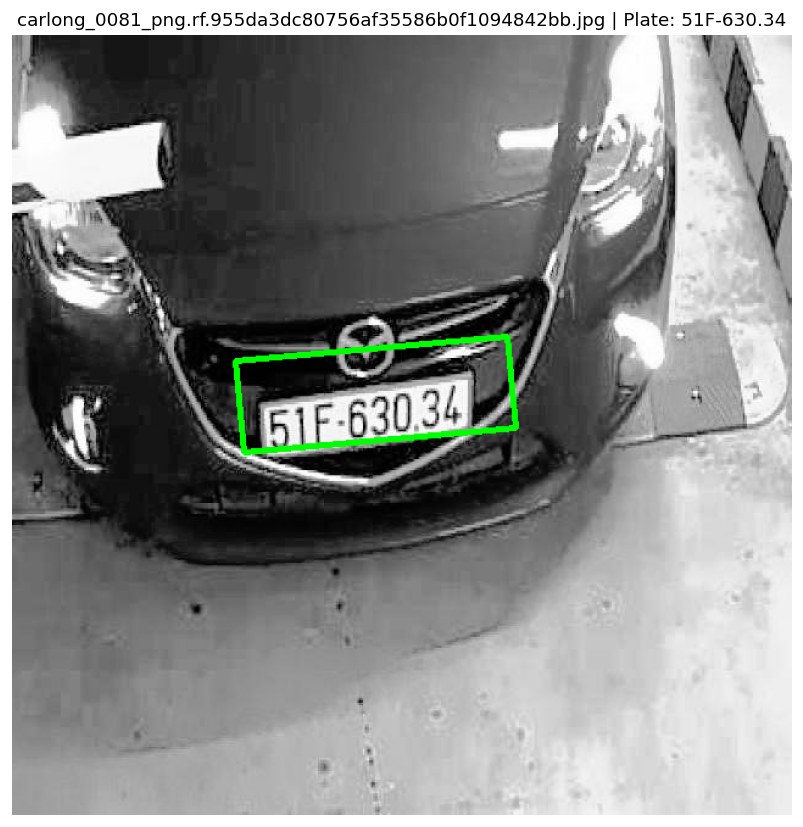


FINAL REPORT
Total images:                 4434
Recognized:                   3791
Not recognized:               643
Errors:                       0
Image recognition success:    85.50%
Average time per image:       1.53 seconds
CSV report: /content/alpr_output/plate_ocr_results.csv
Annotated images: /content/alpr_output/annotated_images
Rectified candidate crops: /content/alpr_output/rectified_plate_crops


,file,plate,status,candidate_count,method,raw_text,processing_seconds
0,carlong_0016_png.rf.53e1e2d990bcdf0e7b5504add8...,29A-517.96,RECOGNIZED,6,opencv_original,29A-517.96,1.245
1,carlong_0021_png.rf.04cda2c58128580a7fdd86a21b...,48A-028.66,RECOGNIZED,6,opencv_original,48A-028.66,1.271
2,carlong_0026_png.rf.62365583d1d10f5240690275e9...,43A-186.50,RECOGNIZED,6,opencv_original,43A-186.50,0.909
3,carlong_0029_png.rf.a0839801b11958cca714c8e74f...,51F-734.20,RECOGNIZED,6,yolo_original,51F-734.20,0.873
4,carlong_0030_png.rf.a5a02a233eea33b12adfba41f3...,47A-065.46,RECOGNIZED,6,opencv_original,47A-065.46,1.242
5,carlong_0049_png.rf.be477b71c2ec7dcc21271ec040...,51F-687.84,RECOGNIZED,6,full_original,51F 687.84,2.588
6,carlong_0052_png.rf.1539d7a70a6cd2596567bfe5bf...,48A-028.66,RECOGNIZED,6,yolo_original,48A-028.66,0.825
7,carlong_0070_png.rf.e2366f6c0c72a331f3bb02e3dd...,51G-394.66,RECOGNIZED,6,full_clahe,51G-394.66,3.252
8,carlong_0072_png.rf.b88c51dae5236fd059c0a115aa...,51F-079.73,RECOGNIZED,6,yolo_original,51F-079.73,1.257
9,carlong_0079_png.rf.4f6e2f6d69c8d831411b23a147...,51F-882.70,RECOGNIZED,6,opencv_original,51F 88270,1.070



Số ảnh chưa nhận diện thành công (NOT_RECOGNIZED + ERROR): 643


,file,status,candidate_count,raw_text,error
16,carlong_0228_png.rf.ad44a52ede3a4d045b27cabcc3...,NOT_RECOGNIZED,6,,
40,carlong_0587_png.rf.e183dacaf5b2cf288e7c16300c...,NOT_RECOGNIZED,6,∠YA-517.96,
94,greenpack_0331_png.rf.776af23ab4438f37c0bf412f...,NOT_RECOGNIZED,6,019.09 | 23-65,
99,greenpack_0392_png.rf.0494c3e7ab26004ebb2a896f...,NOT_RECOGNIZED,6,86·86 | 246.82,
116,greenpack_0599_png.rf.1ebd0399c8ecfd5e21de6198...,NOT_RECOGNIZED,6,426.42 | 18.17,
...,...,...,...,...,...
1696,greenpack_0102_png.rf.7bc20736bc7d9cb76c672517...,NOT_RECOGNIZED,6,0000 | 63.41,
1700,greenpack_0107_png.rf.2f1bb5e5f7008fa5e5ac907d...,NOT_RECOGNIZED,6,6661 | 552-12,
1701,greenpack_0107_png.rf.3f2303a4b0a80aa97dca3ecc...,NOT_RECOGNIZED,6,1939 | ZL-ZS,
1702,greenpack_0107_png.rf.7ed2ad9eb68d607c2ae1cf76...,NOT_RECOGNIZED,6,6661 | 552-12,



Results ZIP: /content/alpr_results.zip
Tải toàn bộ kết quả bằng cell:
from google.colab import files; files.download('/content/alpr_results.zip')


In [9]:
# -*- coding: utf-8 -*-
"""
VIETNAM MOTORBIKE / CAR ALPR - GOOGLE COLAB
YOLOv8n ONNX + OpenCV localization/rectification + image enhancement + PaddleOCR.

- YOLO ONNX is optional. If it is missing or fails to load, OpenCV localization is used.
- PaddleOCR 3.x is preferred; a PaddleOCR 2.x fallback is included.
- The script processes all images by default. Set MAX_IMAGES = 20 for a quick test.
- This is an inference script. Train/export YOLO separately and put the ONNX file at
  /content/license_plate_yolov8n.onnx.

IMPORTANT:
Recognition success means the text passed the heuristic Vietnamese plate parser.
It is not the same as independently verified exact-match accuracy.
"""

# ============================================================
# 1. CONFIGURATION + ENVIRONMENT
# ============================================================
import os
os.environ["FLAGS_enable_pir_api"] = "0"
os.environ["FLAGS_enable_pir_in_executor"] = "0"
os.environ["PADDLE_PDX_ENABLE_MKLDNN_BYDEFAULT"] = "0"
os.environ["FLAGS_use_mkldnn"] = "0"
os.environ["PADDLE_PDX_EAGER_INIT"] = "False"

import re
import json
import csv
import math
import time
import traceback
import zipfile
import shutil
from pathlib import Path
from collections.abc import Iterable

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

# -------- Dataset --------
ZIP_PATH = "/content/dataset_coco.zip"
EXTRACT_DIR = "/content/dataset_coco"
IMAGE_ROOT = EXTRACT_DIR

# -------- Output --------
OUTPUT_ROOT = "/content/alpr_output"
ANNOTATED_DIR = os.path.join(OUTPUT_ROOT, "annotated_images")
CROPS_DIR = os.path.join(OUTPUT_ROOT, "rectified_plate_crops")
CSV_OUTPUT_PATH = os.path.join(OUTPUT_ROOT, "plate_ocr_results.csv")
RESULTS_ZIP_PATH = "/content/alpr_results.zip"

# -------- Batch options --------
MAX_IMAGES = None          # None = all images; set 20 for a short test run
SHOW_PREVIEWS = True
MAX_PREVIEWS = 12
MAX_PLATE_CANDIDATES = 6

# -------- YOLO ONNX --------
YOLO_ONNX_PATH = "/content/license_plate_yolov8n.onnx"
USE_YOLO_ONNX = True
YOLO_INPUT_SIZE = 640      # Must match the exported ONNX input size
YOLO_CONF_THRESHOLD = 0.22
YOLO_NMS_THRESHOLD = 0.45
YOLO_MAX_CANDIDATES = 3

# -------- OCR retry --------
# 12 lets the first candidate test all enhancement variants, including rotations.
MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE = 12
RETRY_CANDIDATE_COUNT = 2
REUSE_EXISTING_OCR = True

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

for folder in (OUTPUT_ROOT, ANNOTATED_DIR, CROPS_DIR):
    os.makedirs(folder, exist_ok=True)


def has_images(folder):
    if not os.path.isdir(folder):
        return False
    for root, _dirs, names in os.walk(folder):
        if any(Path(name).suffix.lower() in IMAGE_EXTENSIONS for name in names):
            return True
    return False


def obtain_dataset_zip():
    """Upload ZIP only when the extracted dataset is not already available."""
    global ZIP_PATH
    if os.path.isfile(ZIP_PATH):
        return ZIP_PATH

    try:
        from google.colab import files
        print(f"Không tìm thấy ZIP tại {ZIP_PATH}.")
        print("Hãy chọn file greenParking.v1i.coco.zip.")
        uploaded = files.upload()
        names = [name for name in uploaded if name.lower().endswith(".zip")]
        if not names:
            raise FileNotFoundError("Bạn chưa tải lên file ZIP.")
        ZIP_PATH = os.path.join("/content", names[0])
        return ZIP_PATH
    except ImportError as exc:
        raise FileNotFoundError(
            f"Không tìm thấy {ZIP_PATH}. Hãy tải ZIP vào /content trước khi chạy."
        ) from exc


if not has_images(EXTRACT_DIR):
    zip_path = obtain_dataset_zip()
    if not zipfile.is_zipfile(zip_path):
        raise RuntimeError(f"File không phải ZIP hợp lệ: {zip_path}")

    if os.path.isdir(EXTRACT_DIR):
        shutil.rmtree(EXTRACT_DIR)
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    print("Đang giải nén dataset...")

    # Prevent ZIP path traversal (Zip Slip).
    destination = os.path.abspath(EXTRACT_DIR)
    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = os.path.abspath(os.path.join(EXTRACT_DIR, member.filename))
            if os.path.commonpath([destination, target]) != destination:
                raise RuntimeError(f"ZIP chứa đường dẫn không an toàn: {member.filename}")
        zf.extractall(EXTRACT_DIR)
    print("Đã giải nén xong.")
else:
    print("Đã tìm thấy dataset đã giải nén; bỏ qua bước giải nén ZIP.")

if not has_images(IMAGE_ROOT):
    raise RuntimeError(f"Không tìm thấy ảnh trong thư mục: {IMAGE_ROOT}")

print("Dataset ZIP:", ZIP_PATH if os.path.isfile(ZIP_PATH) else "(using extracted folder)")
print("Image root:", IMAGE_ROOT)
print("Output root:", OUTPUT_ROOT)

# ============================================================
# 2. INITIALIZE / REUSE PADDLEOCR
# ============================================================
print("\n" + "=" * 70)
print("INITIALIZING PADDLEOCR")
print("=" * 70)

import paddle
from paddleocr import PaddleOCR

paddle_version = getattr(paddle, "__version__", "unknown")
try:
    gpu_count = int(paddle.device.cuda.device_count())
except Exception:
    gpu_count = 0

try:
    cuda_compiled = bool(paddle.is_compiled_with_cuda())
except Exception:
    cuda_compiled = False

USE_PADDLE_GPU = cuda_compiled and gpu_count > 0
OCR_DEVICE = "gpu:0" if USE_PADDLE_GPU else "cpu"
print("PaddlePaddle:", paddle_version)
print("CUDA compiled:", cuda_compiled)
print("GPU count:", gpu_count)
print("OCR device:", OCR_DEVICE)

_existing_ocr = globals().get("ocr") if REUSE_EXISTING_OCR else None
if _existing_ocr is not None and (callable(getattr(_existing_ocr, "predict", None)) or
                                  callable(getattr(_existing_ocr, "ocr", None))):
    ocr = _existing_ocr
    print("Reusing the PaddleOCR instance already initialized in this notebook.")
else:
    try:
        try:
            paddle.device.set_device(OCR_DEVICE)
        except Exception as device_error:
            print("Thông báo: không đặt được Paddle device:", device_error)

        try:
            # PaddleOCR 3.x
            ocr = PaddleOCR(
                use_textline_orientation=True,
                lang="en",
                device=OCR_DEVICE
            )
        except TypeError:
            # PaddleOCR 2.x compatibility
            ocr = PaddleOCR(
                use_angle_cls=True,
                lang="en",
                use_gpu=USE_PADDLE_GPU
            )
        print("PaddleOCR initialized successfully.")
    except Exception as exc:
        raise RuntimeError(
            "Không thể khởi tạo PaddleOCR. Kiểm tra phiên bản PaddlePaddle/PaddleOCR "
            "và runtime.\nChi tiết: " + repr(exc)
        ) from exc

# ============================================================
# 3. VIETNAMESE LICENSE-PLATE FORMAT FILTER
# ============================================================
def parse_vietnam_plate(text):
    """Heuristic parser for common Vietnamese plate patterns; not legal validation."""
    if text is None:
        return None

    clean = re.sub(r"[^A-Z0-9]", "", str(text).upper())
    if len(clean) < 7:
        return None

    digit_map = str.maketrans({
        "O": "0", "Q": "0", "D": "0",
        "I": "1", "L": "1", "Z": "2",
        "S": "5", "G": "6", "B": "8"
    })

    matches = []
    # Common compact lengths: 7, 8, or 9 characters after removing punctuation.
    for start in range(len(clean)):
        for length in (9, 8, 7):
            sample = clean[start:start + length]
            if len(sample) != length:
                continue

            province = sample[:2].translate(digit_map)
            if not province.isdigit() or not (11 <= int(province) <= 99):
                continue

            rest = sample[2:]
            if not rest or not rest[0].isalpha():
                continue

            for series_len in (1, 2):
                if len(rest) <= series_len:
                    continue
                series = rest[:series_len]
                # Series should begin with a letter; a second character may be a digit.
                if not series[0].isalpha():
                    continue
                number = rest[series_len:].translate(digit_map)
                if number.isdigit() and len(number) in (4, 5):
                    if len(number) == 4:
                        formatted = f"{province}{series}-{number}"
                    else:
                        formatted = f"{province}{series}-{number[:3]}.{number[3:]}"
                    matches.append(formatted)

    return max(matches, key=len) if matches else None

# ============================================================
# 4. GENERAL IMAGE HELPERS
# ============================================================
def gamma_correct(image, gamma=1.0):
    """gamma > 1 darkens; gamma < 1 brightens."""
    if image is None or image.size == 0:
        return image
    gamma = max(0.1, float(gamma))
    table = np.array([
        np.clip(((i / 255.0) ** gamma) * 255.0, 0, 255)
        for i in range(256)
    ], dtype=np.uint8)
    return cv2.LUT(image, table)


def clahe_bgr(image, clip_limit=2.5, tile_grid=(8, 8)):
    if image is None or image.size == 0:
        return image
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_chan, a_chan, b_chan = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    enhanced = clahe.apply(l_chan)
    return cv2.cvtColor(cv2.merge((enhanced, a_chan, b_chan)), cv2.COLOR_LAB2BGR)


def suppress_red_influence(image):
    """Alternative luminance view that reduces red-channel influence."""
    b, g, _r = cv2.split(image)
    gray = cv2.addWeighted(g, 0.86, b, 0.14, 0)
    return cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)


def order_points(points):
    """Order a quadrilateral as top-left, top-right, bottom-right, bottom-left."""
    pts = np.asarray(points, dtype=np.float32).reshape(4, 2)
    ordered = np.zeros((4, 2), dtype=np.float32)
    sums = pts.sum(axis=1)
    diffs = np.diff(pts, axis=1).reshape(-1)
    ordered[0] = pts[np.argmin(sums)]
    ordered[2] = pts[np.argmax(sums)]
    ordered[1] = pts[np.argmin(diffs)]
    ordered[3] = pts[np.argmax(diffs)]
    return ordered


def rectify_plate(image, points):
    """Perspective-transform a four-point candidate to a rectangular crop."""
    try:
        rect = order_points(points)
        tl, tr, br, bl = rect
        width = int(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl)))
        height = int(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr)))
        if width < 8 or height < 8:
            return None

        destination = np.array([
            [0, 0], [width - 1, 0],
            [width - 1, height - 1], [0, height - 1]
        ], dtype=np.float32)
        matrix = cv2.getPerspectiveTransform(rect, destination)
        warped = cv2.warpPerspective(
            image, matrix, (width, height),
            flags=cv2.INTER_CUBIC,
            borderMode=cv2.BORDER_REPLICATE
        )
        return warped if warped is not None and warped.size else None
    except Exception:
        return None

# ============================================================
# 5. OPENCV PLATE LOCALIZATION
# ============================================================
def make_detection_gray_variants(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8)).apply(gray)
    b, g, _r = cv2.split(image)
    red_reduced = cv2.addWeighted(g, 0.86, b, 0.14, 0)
    return [gray, clahe, red_reduced]


def make_localization_masks(gray, scale):
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    sobel_x = cv2.Sobel(blurred, cv2.CV_32F, 1, 0, ksize=3)
    sobel_x = cv2.convertScaleAbs(sobel_x)
    _, otsu = cv2.threshold(sobel_x, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    def odd_size(value):
        value = max(3, int(round(value)))
        return value if value % 2 else value + 1

    kernel_sizes = [
        (odd_size(23 * scale), odd_size(3 * scale)),
        (odd_size(13 * scale), odd_size(9 * scale)),
        (odd_size(9 * scale), odd_size(15 * scale)),
        (odd_size(7 * scale), odd_size(7 * scale))
    ]
    masks = []
    for kw, kh in kernel_sizes:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (kw, kh))
        masks.append(cv2.morphologyEx(otsu, cv2.MORPH_CLOSE, kernel))

    blackhat_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (odd_size(17 * scale), odd_size(5 * scale))
    )
    blackhat = cv2.morphologyEx(blurred, cv2.MORPH_BLACKHAT, blackhat_kernel)
    _, blackhat_threshold = cv2.threshold(
        blackhat, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    close_kernel = cv2.getStructuringElement(
        cv2.MORPH_RECT, (odd_size(15 * scale), odd_size(5 * scale))
    )
    masks.append(cv2.morphologyEx(blackhat_threshold, cv2.MORPH_CLOSE, close_kernel))
    edges = cv2.Canny(blurred, 50, 150)
    return masks, edges


def box_iou(box_a, box_b):
    ax, ay, aw, ah = box_a
    bx, by, bw, bh = box_b
    x1, y1 = max(ax, bx), max(ay, by)
    x2, y2 = min(ax + aw, bx + bw), min(ay + ah, by + bh)
    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    union = aw * ah + bw * bh - intersection
    return intersection / union if union > 0 else 0.0


def candidate_score(image, points, contour_area):
    """Heuristic ranking score, not an OCR probability."""
    points = order_points(points)
    tl, tr, br, bl = points
    width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
    height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
    if min(width, height) <= 0:
        return 0.0

    ratio = max(width, height) / max(1.0, min(width, height))
    square_score = math.exp(-abs(math.log(max(ratio, 1e-6) / 1.45)) / 0.70)
    long_score = math.exp(-abs(math.log(max(ratio, 1e-6) / 3.5)) / 0.85)
    ratio_score = max(square_score, long_score)
    rect_area = max(width * height, 1.0)
    shape_score = float(np.clip(contour_area / rect_area, 0.0, 1.0))

    x, y, bw, bh = cv2.boundingRect(points.astype(np.int32))
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(image.shape[1], x + bw), min(image.shape[0], y + bh)
    roi = image[y1:y2, x1:x2]
    if roi.size:
        gray_roi = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
        contrast_score = float(np.clip(np.std(gray_roi) / 65.0, 0.0, 1.0))
        edge_density = float(np.mean(cv2.Canny(gray_roi, 50, 150) > 0))
        edge_score = float(np.clip(edge_density / 0.20, 0.0, 1.0))
    else:
        contrast_score = edge_score = 0.0

    image_area = max(1, image.shape[0] * image.shape[1])
    area_fraction = rect_area / image_area
    area_score = math.exp(-abs(math.log(max(area_fraction, 1e-8) / 0.003)) / 4.5)
    return float(
        0.30 * ratio_score + 0.17 * shape_score
        + 0.21 * contrast_score + 0.17 * edge_score
        + 0.15 * area_score
    )


def locate_plate_candidates(image, max_candidates=MAX_PLATE_CANDIDATES):
    """Find near-square motorcycle plates and long rectangular car plates."""
    if image is None or image.size == 0:
        return []

    img_h, img_w = image.shape[:2]
    image_area = img_h * img_w
    scale = max(0.70, min(max(img_h, img_w) / 1000.0, 2.4))
    min_rect_area = max(200.0, image_area * 0.00002)
    max_rect_area = image_area * 0.12
    min_short_side = max(9.0, 5.0 * scale)
    candidates = []

    def add_candidate(points, contour_area):
        try:
            points = order_points(np.asarray(points, dtype=np.float32).reshape(4, 2))
            tl, tr, br, bl = points
            width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
            height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
            if width < 8 or height < 8:
                return
            ratio = max(width, height) / max(1.0, min(width, height))
            rect_area = width * height
            if ratio > 7.5 or rect_area < min_rect_area or rect_area > max_rect_area:
                return
            if min(width, height) < min_short_side:
                return

            crop = rectify_plate(image, points)
            if crop is None or min(crop.shape[:2]) < 6:
                return

            x, y, bw, bh = cv2.boundingRect(points.astype(np.int32))
            x, y = max(0, x), max(0, y)
            bw, bh = min(img_w - x, bw), min(img_h - y, bh)
            if bw <= 0 or bh <= 0:
                return

            candidates.append({
                "points": points,
                "bbox": (x, y, bw, bh),
                "crop": crop,
                "ratio": float(ratio),
                "area": float(rect_area),
                "score": candidate_score(image, points, float(contour_area)),
                "source": "OpenCV"
            })
        except Exception:
            return

    for view_index, gray in enumerate(make_detection_gray_variants(image)):
        masks, edges = make_localization_masks(gray, scale)
        for mask in masks:
            contours, _ = cv2.findContours(
                mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )
            contours = sorted(contours, key=cv2.contourArea, reverse=True)[:120]
            for contour in contours:
                if len(contour) < 4:
                    continue
                rect = cv2.minAreaRect(contour)
                rw, rh = rect[1]
                if rw >= 1 and rh >= 1:
                    add_candidate(cv2.boxPoints(rect), cv2.contourArea(contour))

        if view_index < 2:
            contours, _ = cv2.findContours(
                edges.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE
            )
            contours = sorted(contours, key=cv2.contourArea, reverse=True)[:180]
            for contour in contours:
                perimeter = cv2.arcLength(contour, True)
                if perimeter <= 0:
                    continue
                approx = cv2.approxPolyDP(contour, 0.025 * perimeter, True)
                if len(approx) == 4 and cv2.isContourConvex(approx):
                    add_candidate(approx.reshape(4, 2), cv2.contourArea(approx))

    candidates.sort(key=lambda item: item["score"], reverse=True)
    selected = []
    for candidate in candidates:
        if not any(box_iou(candidate["bbox"], old["bbox"]) > 0.55 for old in selected):
            selected.append(candidate)
        if len(selected) >= max_candidates:
            break
    return selected

# ============================================================
# 6. CROP ENHANCEMENT FOR OCR
# ============================================================
def upscale_and_pad_plate(crop):
    if crop is None or crop.size == 0:
        return None
    h, w = crop.shape[:2]
    short_side = max(1, min(h, w))
    factor = min(3.0, max(1.0, 100.0 / short_side))
    if max(h, w) * factor > 1800:
        factor = 1800.0 / max(h, w)
    if factor > 1.01:
        crop = cv2.resize(
            crop,
            (max(8, int(w * factor)), max(8, int(h * factor))),
            interpolation=cv2.INTER_CUBIC
        )
    pad = max(5, int(min(crop.shape[:2]) * 0.08))
    return cv2.copyMakeBorder(
        crop, pad, pad, pad, pad,
        cv2.BORDER_CONSTANT, value=(255, 255, 255)
    )


def retinex_ssr_luminance(image, sigma=25.0):
    """Single-scale Retinex on LAB luminance for low-light crops."""
    if image is None or image.size == 0:
        return image
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    luminance = lab[:, :, 0].astype(np.float32) + 1.0
    illumination = cv2.GaussianBlur(
        luminance, (0, 0), sigmaX=sigma, sigmaY=sigma
    ) + 1.0
    ret = np.log(luminance) - np.log(illumination)
    low, high = np.percentile(ret, (1, 99))
    if high <= low:
        return image.copy()
    lab[:, :, 0] = np.clip(
        (ret - low) * 255.0 / (high - low), 0, 255
    ).astype(np.uint8)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)


def unsharp_mask(image, amount=0.45, sigma=1.0):
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=sigma)
    return cv2.addWeighted(image, 1.0 + amount, blurred, -amount, 0)


def kmeans_binary_variant(image):
    """Two-cluster grayscale segmentation used as an auxiliary OCR view."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    original_h, original_w = gray.shape[:2]
    work = gray
    max_dim = max(original_h, original_w)
    if max_dim > 900:
        scale = 900.0 / max_dim
        work = cv2.resize(
            gray,
            (max(2, int(original_w * scale)), max(2, int(original_h * scale))),
            interpolation=cv2.INTER_AREA
        )

    samples = work.reshape((-1, 1)).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    cv2.setRNGSeed(42)
    _compactness, labels, centers = cv2.kmeans(
        samples, 2, None, criteria, 3, cv2.KMEANS_PP_CENTERS
    )
    sorted_centers = np.argsort(centers.reshape(-1))
    binary = np.where(
        labels.reshape(work.shape) == sorted_centers[0], 0, 255
    ).astype(np.uint8)
    if binary.shape != gray.shape:
        binary = cv2.resize(
            binary, (original_w, original_h), interpolation=cv2.INTER_NEAREST
        )
    opened = cv2.morphologyEx(
        binary, cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
    )
    return cv2.cvtColor(opened, cv2.COLOR_GRAY2BGR)


def make_plate_ocr_variants(crop):
    """Generate a bounded set of OCR views, keeping original first."""
    base = upscale_and_pad_plate(crop)
    if base is None:
        return {}

    gray = cv2.cvtColor(base, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8)).apply(gray)
    variants = {
        "original": base,
        "clahe": cv2.cvtColor(clahe, cv2.COLOR_GRAY2BGR),
        "gamma_bright": gamma_correct(base, 0.78),
        "gamma_dark": gamma_correct(base, 1.22),
        "retinex": retinex_ssr_luminance(base),
        "denoise": cv2.fastNlMeansDenoisingColored(base, None, 3, 3, 7, 21),
        "unsharp": unsharp_mask(base, amount=0.45, sigma=1.0)
    }

    min_dim = min(gray.shape[:2])
    block_size = min(31, min_dim if min_dim % 2 else min_dim - 1)
    if block_size >= 3:
        adaptive = cv2.adaptiveThreshold(
            clahe, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
            cv2.THRESH_BINARY, block_size, 5
        )
        variants["adaptive"] = cv2.cvtColor(adaptive, cv2.COLOR_GRAY2BGR)

    _threshold, otsu = cv2.threshold(
        clahe, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )
    variants["otsu"] = cv2.cvtColor(otsu, cv2.COLOR_GRAY2BGR)
    variants["kmeans_open"] = kmeans_binary_variant(base)
    variants["rotate180"] = cv2.rotate(base, cv2.ROTATE_180)

    if base.shape[0] > base.shape[1] * 1.20:
        variants["rotate90"] = cv2.rotate(base, cv2.ROTATE_90_CLOCKWISE)
        variants["rotate270"] = cv2.rotate(base, cv2.ROTATE_90_COUNTERCLOCKWISE)
    return variants


def make_full_image_variants(image):
    """Limited full-frame variants; these may be costly for high-resolution images."""
    return {
        "full_original": image,
        "full_clahe": clahe_bgr(image),
        "full_gamma_dark": gamma_correct(image, 1.18),
        "full_red_suppressed": suppress_red_influence(image),
        "full_retinex": retinex_ssr_luminance(image)
    }

# ============================================================
# 7. YOLO ONNX + OPENCV DNN (OPTIONAL)
# ============================================================
# No torch/ultralytics import is required in this inference runtime.
YOLO_NET = None
if USE_YOLO_ONNX and os.path.isfile(YOLO_ONNX_PATH):
    try:
        YOLO_NET = cv2.dnn.readNetFromONNX(YOLO_ONNX_PATH)
        YOLO_NET.setPreferableBackend(cv2.dnn.DNN_BACKEND_OPENCV)
        YOLO_NET.setPreferableTarget(cv2.dnn.DNN_TARGET_CPU)
        print("YOLO ONNX loaded:", YOLO_ONNX_PATH)
    except Exception as exc:
        YOLO_NET = None
        print("WARNING: YOLO ONNX could not be loaded; using OpenCV-only mode.")
        print("YOLO load error:", repr(exc))
else:
    print("YOLO ONNX missing/disabled; OpenCV-only localization will be used.")
    print("Expected model path:", YOLO_ONNX_PATH)


def letterbox_for_yolo(image, size=YOLO_INPUT_SIZE):
    h, w = image.shape[:2]
    scale = min(size / max(1, w), size / max(1, h))
    nw = max(1, int(round(w * scale)))
    nh = max(1, int(round(h * scale)))
    resized = cv2.resize(image, (nw, nh), interpolation=cv2.INTER_LINEAR)
    dw, dh = size - nw, size - nh
    left, right = dw // 2, dw - dw // 2
    top, bottom = dh // 2, dh - dh // 2
    canvas = cv2.copyMakeBorder(
        resized, top, bottom, left, right,
        cv2.BORDER_CONSTANT, value=(114, 114, 114)
    )
    return canvas, scale, left, top


def rectify_inside_yolo_box(image, bbox):
    """Try to find a plate quadrilateral inside a YOLO box; otherwise use box crop."""
    x, y, bw, bh = map(int, bbox)
    img_h, img_w = image.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(img_w, x + bw), min(img_h, y + bh)
    roi = image[y1:y2, x1:x2]
    if roi.size == 0:
        return None, None

    roi_h, roi_w = roi.shape[:2]
    roi_area = max(1, roi_h * roi_w)
    gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
    gray = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
    edges = cv2.Canny(cv2.GaussianBlur(gray, (3, 3), 0), 35, 130)
    edges = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)), iterations=1
    )
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    contours = sorted(contours, key=cv2.contourArea, reverse=True)[:40]

    best = None
    best_score = -1.0
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < roi_area * 0.22 or area > roi_area * 1.10:
            continue
        perimeter = cv2.arcLength(contour, True)
        if perimeter <= 0:
            continue
        approx = cv2.approxPolyDP(contour, 0.018 * perimeter, True)
        if len(approx) != 4 or not cv2.isContourConvex(approx):
            continue
        rect = order_points(approx.reshape(4, 2).astype(np.float32))
        tl, tr, br, bl = rect
        width = max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))
        height = max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))
        if min(width, height) < 8:
            continue
        ratio = max(width, height) / max(1.0, min(width, height))
        if ratio > 7.5:
            continue
        fill = float(area / roi_area)
        shape = float(np.clip(area / max(width * height, 1.0), 0.0, 1.0))
        score = 0.55 * fill + 0.45 * shape
        if score > best_score:
            best_score, best = score, rect

    if best is not None:
        global_points = best + np.array([x1, y1], dtype=np.float32)
        warped = rectify_plate(image, global_points)
        if warped is not None and warped.size:
            return global_points, warped

    # This fallback is a rectangular crop, not a perspective-corrected crop.
    points = np.array([
        [x1, y1], [x2 - 1, y1],
        [x2 - 1, y2 - 1], [x1, y2 - 1]
    ], dtype=np.float32)
    return points, roi.copy()


def detect_yolo_plate_candidates(image, max_candidates=YOLO_MAX_CANDIDATES):
    if YOLO_NET is None or image is None or image.size == 0:
        return []

    canvas, scale, pad_x, pad_y = letterbox_for_yolo(image)
    blob = cv2.dnn.blobFromImage(
        canvas, scalefactor=1.0 / 255.0,
        size=(YOLO_INPUT_SIZE, YOLO_INPUT_SIZE),
        swapRB=True, crop=False
    )
    YOLO_NET.setInput(blob)
    output = YOLO_NET.forward()
    if isinstance(output, (list, tuple)):
        if not output:
            return []
        output = output[0]

    prediction = np.asarray(output)
    if prediction.ndim == 3:
        prediction = prediction[0]
    if prediction.ndim != 2:
        raise RuntimeError(f"Unexpected YOLO ONNX output dimensions: {prediction.shape}")

    # This decoder targets the trained single-class YOLOv8 export: [1, 5, N].
    if prediction.shape[0] <= 16 and prediction.shape[1] > prediction.shape[0]:
        prediction = prediction.T
    if prediction.shape[1] < 5:
        raise RuntimeError(f"Unexpected YOLO ONNX output shape: {prediction.shape}")

    img_h, img_w = image.shape[:2]
    boxes_xywh, scores = [], []
    for row in prediction:
        cx, cy, bw, bh = map(float, row[:4])
        score = float(np.max(row[4:]))
        if not np.isfinite(score) or score < YOLO_CONF_THRESHOLD:
            continue

        x1 = int(round((cx - bw / 2 - pad_x) / scale))
        y1 = int(round((cy - bh / 2 - pad_y) / scale))
        x2 = int(round((cx + bw / 2 - pad_x) / scale))
        y2 = int(round((cy + bh / 2 - pad_y) / scale))
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(img_w, x2), min(img_h, y2)
        if x2 - x1 < 8 or y2 - y1 < 8:
            continue
        boxes_xywh.append([x1, y1, x2 - x1, y2 - y1])
        scores.append(score)

    if not boxes_xywh:
        return []

    keep = cv2.dnn.NMSBoxes(
        boxes_xywh, scores, YOLO_CONF_THRESHOLD, YOLO_NMS_THRESHOLD
    )
    if keep is None or len(keep) == 0:
        return []
    keep = np.asarray(keep).reshape(-1).tolist()

    candidates = []
    for idx in keep:
        x, y, bw, bh = boxes_xywh[idx]
        padx, pady = max(2, int(bw * 0.04)), max(2, int(bh * 0.07))
        x1, y1 = max(0, x - padx), max(0, y - pady)
        x2, y2 = min(img_w, x + bw + padx), min(img_h, y + bh + pady)
        points, crop = rectify_inside_yolo_box(
            image, (x1, y1, x2 - x1, y2 - y1)
        )
        if points is None or crop is None or crop.size == 0:
            continue
        candidates.append({
            "points": points,
            "bbox": (x1, y1, x2 - x1, y2 - y1),
            "crop": crop,
            "ratio": float(max(x2 - x1, y2 - y1) / max(1, min(x2 - x1, y2 - y1))),
            "area": float((x2 - x1) * (y2 - y1)),
            "score": float(scores[idx]),
            "source": "YOLO"
        })

    candidates.sort(key=lambda item: item["score"], reverse=True)
    return candidates[:max_candidates]


def quad_angle_degrees(points):
    pts = order_points(points)
    dx = float(pts[1][0] - pts[0][0])
    dy = float(pts[1][1] - pts[0][1])
    return abs(math.degrees(math.atan2(dy, dx)))


def locate_plate_candidates_hybrid(image, max_candidates=MAX_PLATE_CANDIDATES):
    cv_candidates = locate_plate_candidates(image, max_candidates=max_candidates)
    yolo_candidates = detect_yolo_plate_candidates(
        image, max_candidates=min(YOLO_MAX_CANDIDATES, max_candidates)
    )

    ordered = []
    unused_cv = list(cv_candidates)
    for yolo_item in yolo_candidates:
        match_idx, match_iou = None, 0.0
        for idx, cv_item in enumerate(unused_cv):
            overlap = box_iou(yolo_item["bbox"], cv_item["bbox"])
            if overlap > match_iou:
                match_iou, match_idx = overlap, idx
        if match_idx is not None and match_iou >= 0.25:
            cv_item = unused_cv.pop(match_idx)
            # Prefer a tilted OpenCV quadrilateral first; otherwise try YOLO crop first.
            if quad_angle_degrees(cv_item["points"]) >= 2.0:
                ordered.extend([cv_item, yolo_item])
            else:
                ordered.extend([yolo_item, cv_item])
        else:
            ordered.append(yolo_item)

    ordered.extend(unused_cv)
    selected = []
    for candidate in ordered:
        duplicate = any(
            candidate.get("source") == old.get("source")
            and box_iou(candidate["bbox"], old["bbox"]) > 0.60
            for old in selected
        )
        if not duplicate:
            selected.append(candidate)
        if len(selected) >= max_candidates:
            break
    return selected

# ============================================================
# 8. PADDLEOCR COMPATIBILITY + RESULT EXTRACTION
# ============================================================
def run_paddle_ocr(image_input):
    """Use PaddleOCR 3.x predict(); fall back to ocr() for older versions."""
    predict_func = getattr(ocr, "predict", None)
    if callable(predict_func):
        try:
            return predict_func(image_input)
        except Exception as predict_error:
            ocr_func = getattr(ocr, "ocr", None)
            if not callable(ocr_func):
                raise predict_error

    ocr_func = getattr(ocr, "ocr", None)
    if callable(ocr_func):
        try:
            return ocr_func(image_input)
        except TypeError:
            return ocr_func(image_input, cls=True)
    raise RuntimeError("PaddleOCR object không có predict() hoặc ocr().")


def result_item_to_dict(item):
    data = item
    if not isinstance(data, dict):
        candidate = getattr(item, "json", None)
        if callable(candidate):
            try:
                candidate = candidate()
            except Exception:
                candidate = None
        if candidate is None:
            candidate = getattr(item, "to_dict", None)
            if callable(candidate):
                try:
                    candidate = candidate()
                except Exception:
                    candidate = None
        data = candidate

    if isinstance(data, str):
        try:
            data = json.loads(data)
        except Exception:
            return None
    if not isinstance(data, dict):
        return None
    if isinstance(data.get("res"), dict):
        data = data["res"]
    return data


def is_polygon(value):
    try:
        arr = np.asarray(value)
        if arr.ndim == 1 and arr.size == 4:
            return True
        return arr.ndim == 2 and arr.shape[0] >= 3 and arr.shape[1] >= 2
    except Exception:
        return False


def extract_ocr_items(ocr_output):
    """Normalize common PaddleOCR 2.x and 3.x output structures."""
    blocks = []

    def add_block(poly, text):
        if text is None:
            return
        text = str(text).strip()
        if not text:
            return
        try:
            arr = np.asarray(poly, dtype=np.float32)
        except Exception:
            return

        if arr.ndim == 1 and arr.size == 4:
            x1, y1, x2, y2 = arr.tolist()
            pts = [(x1, y1), (x2, y1), (x2, y2), (x1, y2)]
        elif arr.ndim == 2 and arr.shape[0] >= 3 and arr.shape[1] >= 2:
            pts = [(float(point[0]), float(point[1])) for point in arr]
        else:
            return
        if not all(np.isfinite(value) for point in pts for value in point):
            return
        blocks.append({
            "box": pts,
            "text": text,
            "cx": float(np.mean([point[0] for point in pts])),
            "cy": float(np.mean([point[1] for point in pts]))
        })

    def consume(item, depth=0):
        if item is None or depth > 12:
            return
        data = result_item_to_dict(item)
        if data is not None:
            texts = data.get("rec_texts", data.get("rec_text", data.get("texts")))
            polys = data.get("rec_polys", data.get("dt_polys", data.get("polys")))
            if polys is None:
                polys = data.get("rec_boxes", data.get("boxes"))
            if texts is not None and polys is not None:
                if isinstance(texts, str):
                    add_block(polys, texts)
                    return
                try:
                    for text_value, polygon in zip(list(texts), list(polys)):
                        add_block(polygon, text_value)
                    return
                except Exception:
                    pass
            for key in ("res", "result", "results", "data"):
                if key in data and data[key] is not item:
                    consume(data[key], depth + 1)
            return

        if isinstance(item, (list, tuple)):
            # PaddleOCR 2.x element: [polygon, (recognized_text, confidence)]
            if len(item) >= 2 and is_polygon(item[0]):
                text_info = item[1]
                if isinstance(text_info, (list, tuple)) and len(text_info) > 0:
                    add_block(item[0], text_info[0])
                    return
                if isinstance(text_info, str):
                    add_block(item[0], text_info)
                    return
            for sub_item in item:
                consume(sub_item, depth + 1)
            return

        if isinstance(item, Iterable) and not isinstance(item, (str, bytes, np.ndarray)):
            try:
                for sub_item in item:
                    consume(sub_item, depth + 1)
            except Exception:
                pass

    consume(ocr_output)
    return blocks


def plate_from_blocks(blocks):
    if not blocks:
        return None, "", []

    ordered = sorted(blocks, key=lambda block: (block["cy"], block["cx"]))
    raw_text = " | ".join(block["text"] for block in ordered)
    compact_text = "".join(block["text"] for block in ordered)
    plate = parse_vietnam_plate(compact_text)
    if plate:
        return plate, raw_text, [block["box"] for block in ordered]

    # Try adjacent OCR text blocks in case the detector split a plate into parts.
    for i in range(len(ordered)):
        for j in range(i + 1, len(ordered)):
            plate = parse_vietnam_plate(ordered[i]["text"] + ordered[j]["text"])
            if plate:
                return plate, raw_text, [ordered[i]["box"], ordered[j]["box"]]

    for block in ordered:
        plate = parse_vietnam_plate(block["text"])
        if plate:
            return plate, raw_text, [block["box"]]
    return None, raw_text, []


def run_ocr_and_parse(image_input):
    raw_result = run_paddle_ocr(image_input)
    blocks = extract_ocr_items(raw_result)
    return plate_from_blocks(blocks)

# ============================================================
# 9. OUTPUT PATH HELPERS
# ============================================================
def output_path_for(image_path, root_dir):
    try:
        relative = os.path.relpath(image_path, IMAGE_ROOT)
    except Exception:
        relative = os.path.basename(image_path)
    if relative.startswith(".."):
        relative = os.path.basename(image_path)
    output_path = os.path.join(root_dir, relative)
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    return output_path

# ============================================================
# 10. COMPLETE SINGLE-IMAGE PIPELINE
# ============================================================
def recognize_plate_paddle(image_path, show_preview=False):
    record = {
        "file": os.path.basename(image_path),
        "path": image_path,
        "candidate_count": 0,
        "method": "",
        "raw_text": "",
        "plate": "",
        "status": "NOT_RECOGNIZED",
        "error": "",
        "processing_seconds": 0.0,
        "annotated_path": "",
        "rectified_crop_path": ""
    }
    started = time.time()

    image = cv2.imread(image_path)
    if image is None:
        record["status"] = "ERROR"
        record["error"] = "Could not read image file."
        record["processing_seconds"] = round(time.time() - started, 3)
        return record

    output_image = image.copy()
    best_raw_text = ""
    detected_plate = None
    selected_candidate = None
    selected_method = ""
    target_text_boxes = []

    candidates = locate_plate_candidates_hybrid(
        image, max_candidates=MAX_PLATE_CANDIDATES
    )
    record["candidate_count"] = len(candidates)

    # Pass 1: OCR the original version of every candidate crop.
    for index, candidate in enumerate(candidates):
        try:
            variants = make_plate_ocr_variants(candidate["crop"])
            if not variants:
                continue
            plate, raw_text, _text_boxes = run_ocr_and_parse(variants["original"])
            if len(raw_text) > len(best_raw_text):
                best_raw_text = raw_text
            if plate:
                detected_plate = plate
                selected_candidate = candidate
                selected_method = f"{candidate.get('source', 'candidate').lower()}_original"
                break
        except Exception as exc:
            print(f"Candidate {index + 1} original OCR error: {exc}")

    # Pass 2: enhance only the first few candidates if the original OCR failed.
    if not detected_plate and candidates:
        retry_count = min(RETRY_CANDIDATE_COUNT, len(candidates))
        for index in range(retry_count):
            candidate = candidates[index]
            try:
                variants = make_plate_ocr_variants(candidate["crop"])
                if index == 0:
                    retry_names = [
                        "clahe", "retinex", "gamma_bright", "denoise",
                        "unsharp", "adaptive", "otsu", "kmeans_open",
                        "rotate180", "gamma_dark", "rotate90", "rotate270"
                    ]
                else:
                    retry_names = ["clahe", "retinex", "gamma_bright", "adaptive"]

                retry_names = retry_names[:MAX_ENHANCEMENT_RETRIES_PER_CANDIDATE]
                for variant_name in retry_names:
                    variant_image = variants.get(variant_name)
                    if variant_image is None:
                        continue
                    try:
                        plate, raw_text, _text_boxes = run_ocr_and_parse(variant_image)
                        if len(raw_text) > len(best_raw_text):
                            best_raw_text = raw_text
                        if plate:
                            detected_plate = plate
                            selected_candidate = candidate
                            selected_method = (
                                f"{candidate.get('source', 'candidate').lower()}_{variant_name}"
                            )
                            break
                    except Exception as exc:
                        print(f"Candidate {index + 1} / {variant_name} OCR error: {exc}")
                if detected_plate:
                    break
            except Exception as exc:
                print(f"Candidate {index + 1} enhancement error: {exc}")

    # Pass 3: full-image fallback. Use NumPy arrays (compatible with OCR 2.x and 3.x).
    if not detected_plate:
        try:
            full_variants = make_full_image_variants(image)
            full_attempts = [
                ("full_original", image),
                ("full_clahe", full_variants["full_clahe"]),
                ("full_gamma_dark", full_variants["full_gamma_dark"]),
                ("full_red_suppressed", full_variants["full_red_suppressed"]),
                ("full_retinex", full_variants["full_retinex"])
            ]
            for method, input_image in full_attempts:
                try:
                    plate, raw_text, text_boxes = run_ocr_and_parse(input_image)
                    if len(raw_text) > len(best_raw_text):
                        best_raw_text = raw_text
                    if plate:
                        detected_plate = plate
                        selected_method = method
                        target_text_boxes = text_boxes
                        break
                except Exception as exc:
                    print(f"Full-image OCR ({method}) error: {exc}")
        except Exception as exc:
            print("Full-image enhancement error:", exc)

    # Draw detected plate in green; failed localization candidate in yellow.
    if selected_candidate is not None:
        points = np.asarray(selected_candidate["points"], dtype=np.int32).reshape((-1, 1, 2))
        cv2.polylines(output_image, [points], True, (0, 255, 0), 3)
        x, y, _w, _h = selected_candidate["bbox"]
        source_label = selected_candidate.get("source", "PLATE")
        label = f"{detected_plate or 'PLATE CANDIDATE'} [{source_label}]"
        cv2.putText(
            output_image, label,
            (max(0, x), max(24, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.65,
            (0, 255, 0), 2, cv2.LINE_AA
        )

        crop_path = output_path_for(image_path, CROPS_DIR)
        crop_path = os.path.splitext(crop_path)[0] + "_rectified.jpg"
        if cv2.imwrite(crop_path, selected_candidate["crop"]):
            record["rectified_crop_path"] = crop_path

    elif detected_plate and target_text_boxes:
        for box in target_text_boxes:
            points = np.asarray(box, dtype=np.int32)
            if points.ndim == 2 and points.shape[1] >= 2:
                cv2.polylines(
                    output_image, [points.reshape((-1, 1, 2))],
                    True, (0, 255, 0), 3
                )

    elif candidates:
        best = candidates[0]
        points = np.asarray(best["points"], dtype=np.int32).reshape((-1, 1, 2))
        cv2.polylines(output_image, [points], True, (0, 255, 255), 2)
        x, y, _w, _h = best["bbox"]
        cv2.putText(
            output_image, "CANDIDATE - OCR FAILED",
            (max(0, x), max(24, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, 0.60,
            (0, 255, 255), 2, cv2.LINE_AA
        )

    annotated_path = output_path_for(image_path, ANNOTATED_DIR)
    if cv2.imwrite(annotated_path, output_image):
        record["annotated_path"] = annotated_path

    record["raw_text"] = best_raw_text
    record["method"] = selected_method
    if detected_plate:
        record["plate"] = detected_plate
        record["status"] = "RECOGNIZED"
    else:
        record["status"] = "NOT_RECOGNIZED"

    record["processing_seconds"] = round(time.time() - started, 3)

    if show_preview:
        plt.figure(figsize=(12, 7))
        plt.imshow(cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        title = f"Plate: {detected_plate}" if detected_plate else "Plate not confirmed"
        plt.title(f"{os.path.basename(image_path)} | {title}", fontsize=11)
        plt.tight_layout()
        plt.show()
        plt.close()

    return record

# ============================================================
# 11. DISCOVER INPUT IMAGES
# ============================================================
def find_images(root_dir):
    image_paths = []
    if not os.path.isdir(root_dir):
        print(f"Input directory does not exist: {root_dir}")
        return image_paths
    for root, dirs, filenames in os.walk(root_dir):
        dirs.sort()
        filenames.sort()
        for filename in filenames:
            if Path(filename).suffix.lower() in IMAGE_EXTENSIONS:
                image_paths.append(os.path.join(root, filename))
    return image_paths

# ============================================================
# 12. BATCH PROCESSING + CSV + SUMMARY + ZIP
# ============================================================
print("\n" + "=" * 70)
print("SCANNING DATASET IMAGES")
print("=" * 70)
image_files = find_images(IMAGE_ROOT)
if MAX_IMAGES is not None:
    image_files = image_files[:max(0, int(MAX_IMAGES))]

total_images = len(image_files)
print("Input root:", IMAGE_ROOT)
print("Images selected:", total_images)
print("YOLO active:", YOLO_NET is not None)
print("OCR device:", OCR_DEVICE)

if total_images == 0:
    raise RuntimeError("Không tìm thấy ảnh. Hãy kiểm tra ZIP và cấu trúc thư mục dataset.")

all_results = []
preview_count = 0
print("\nSTARTING PLATE LOCALIZATION + OCR")

for index, image_path in enumerate(tqdm(image_files, desc="ALPR", unit="image"), start=1):
    show_this = SHOW_PREVIEWS and preview_count < MAX_PREVIEWS
    try:
        result = recognize_plate_paddle(image_path, show_preview=show_this)
    except Exception as exc:
        result = {
            "file": os.path.basename(image_path),
            "path": image_path,
            "candidate_count": 0,
            "method": "",
            "raw_text": "",
            "plate": "",
            "status": "ERROR",
            "error": repr(exc),
            "processing_seconds": 0.0,
            "annotated_path": "",
            "rectified_crop_path": ""
        }
        print(f"\nUNHANDLED IMAGE ERROR [{index}/{total_images}]: {exc}")
        traceback.print_exc(limit=1)
    all_results.append(result)
    if show_this:
        preview_count += 1

fieldnames = [
    "file", "path", "candidate_count", "method", "raw_text",
    "plate", "status", "error", "processing_seconds",
    "annotated_path", "rectified_crop_path"
]
with open(CSV_OUTPUT_PATH, "w", newline="", encoding="utf-8-sig") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(all_results)

recognized = sum(item["status"] == "RECOGNIZED" for item in all_results)
not_recognized = sum(item["status"] == "NOT_RECOGNIZED" for item in all_results)
errors = sum(item["status"] == "ERROR" for item in all_results)
success_rate = 100.0 * recognized / total_images if total_images else 0.0
average_seconds = (
    sum(float(item.get("processing_seconds", 0.0)) for item in all_results) / total_images
    if total_images else 0.0
)

print("\n" + "=" * 70)
print("FINAL REPORT")
print("=" * 70)
print(f"Total images:                 {total_images}")
print(f"Recognized:                   {recognized}")
print(f"Not recognized:               {not_recognized}")
print(f"Errors:                       {errors}")
print(f"Image recognition success:    {success_rate:.2f}%")
print(f"Average time per image:       {average_seconds:.2f} seconds")
print("CSV report:", CSV_OUTPUT_PATH)
print("Annotated images:", ANNOTATED_DIR)
print("Rectified candidate crops:", CROPS_DIR)
print("=" * 70)

# Display the first 30 rows for inspection.
df_results = pd.DataFrame(all_results)
display(df_results[[
    "file", "plate", "status", "candidate_count", "method", "raw_text",
    "processing_seconds"
]].head(30))

# Show failed items separately, including ERROR.
df_failed = df_results[df_results["status"] != "RECOGNIZED"]
print(f"\nSố ảnh chưa nhận diện thành công (NOT_RECOGNIZED + ERROR): {len(df_failed)}")
if len(df_failed):
    display(df_failed[[
        "file", "status", "candidate_count", "raw_text", "error"
    ]].head(100))

# Create one archive containing CSV, annotations and candidate crops.
if os.path.exists(RESULTS_ZIP_PATH):
    os.remove(RESULTS_ZIP_PATH)
shutil.make_archive(RESULTS_ZIP_PATH[:-4], "zip", root_dir=OUTPUT_ROOT)
print("\nResults ZIP:", RESULTS_ZIP_PATH)
print("Tải toàn bộ kết quả bằng cell:")
print("from google.colab import files; files.download('/content/alpr_results.zip')")

# Optional direct download (uncomment in Colab if wanted):
# from google.colab import files
# files.download(RESULTS_ZIP_PATH)


In [ ]:

# ============================================================
# CELL RIÊNG: XUẤT 2 FILE EXCEL THÀNH CÔNG / THẤT BẠI
# KHÔNG CHẠY LẠI QUÁ TRÌNH NHẬN DIỆN ALPR
# ============================================================

import os
import csv
import json
import shutil
import math
from datetime import datetime

from PIL import Image as PILImage, ImageOps
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

# ------------------------------------------------------------
# 1. ĐƯỜNG DẪN
# ------------------------------------------------------------

OUTPUT_ROOT = globals().get("OUTPUT_ROOT", "/content/alpr_output")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

SUCCESS_FILE = os.path.join(
    OUTPUT_ROOT, "ALPR_ANH_THANH_CONG.xlsx"
)

FAILED_FILE = os.path.join(
    OUTPUT_ROOT, "ALPR_ANH_THAT_BAI.xlsx"
)

TEMP_DIR = os.path.join(OUTPUT_ROOT, "_excel_temp")
os.makedirs(TEMP_DIR, exist_ok=True)

CSV_PATH = os.path.join(
    OUTPUT_ROOT, "plate_ocr_results.csv"
)

# ------------------------------------------------------------
# 2. LẤY KẾT QUẢ ĐÃ CHẠY, KHÔNG CHẠY LẠI ALPR
# ------------------------------------------------------------

if "all_results" in globals() and all_results:
    results = [dict(x) for x in all_results]
    print("Đang lấy kết quả từ all_results có sẵn.")

elif os.path.isfile(CSV_PATH):
    with open(CSV_PATH, "r", encoding="utf-8-sig", newline="") as f:
        results = list(csv.DictReader(f))
    print("Đang lấy kết quả từ CSV có sẵn.")

else:
    raise FileNotFoundError(
        "Không tìm thấy all_results hoặc plate_ocr_results.csv. "
        "Hãy chạy ALPR một lần để tạo dữ liệu kết quả."
    )

print("Tổng số kết quả:", len(results))

# ------------------------------------------------------------
# 3. TÁCH THÀNH CÔNG VÀ THẤT BẠI
# ------------------------------------------------------------

success_results = [
    r for r in results
    if str(r.get("status", "")).upper() == "RECOGNIZED"
]

failed_results = [
    r for r in results
    if str(r.get("status", "")).upper() != "RECOGNIZED"
]

print("Thành công:", len(success_results))
print("Thất bại:", len(failed_results))

# ------------------------------------------------------------
# 4. HÀM XỬ LÝ THÔNG TIN
# ------------------------------------------------------------

def safe_path(value):
    if value is None:
        return ""
    value = str(value)
    if value.lower() in ("", "none", "nan"):
        return ""
    return value


def get_dataset_split(image_path):
    parts = os.path.normpath(image_path).lower().split(os.sep)

    for name in ("train", "valid", "test"):
        if name in parts:
            return name

    return "unknown"


def get_image_info(image_path):
    info = {
        "image_format": "",
        "image_width": None,
        "image_height": None,
        "image_size_kb": None,
        "image_readable": False,
        "image_modified_time": ""
    }

    if not image_path or not os.path.isfile(image_path):
        return info

    try:
        with PILImage.open(image_path) as img:
            info["image_width"], info["image_height"] = img.size
            info["image_format"] = img.format or ""
            info["image_readable"] = True

        info["image_size_kb"] = round(
            os.path.getsize(image_path) / 1024, 2
        )

        info["image_modified_time"] = datetime.fromtimestamp(
            os.path.getmtime(image_path)
        ).strftime("%Y-%m-%d %H:%M:%S")

    except Exception as e:
        info["image_error"] = str(e)

    return info


def create_thumbnail(source_path, output_path):
    if not source_path or not os.path.isfile(source_path):
        return None

    try:
        with PILImage.open(source_path) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            img.thumbnail((160, 105))

            canvas = PILImage.new("RGB", (165, 110), "white")
            x = (165 - img.width) // 2
            y = (110 - img.height) // 2
            canvas.paste(img, (x, y))
            canvas.save(output_path, "JPEG", quality=85)

        return output_path

    except Exception:
        return None


def excel_safe(value):
    if value is None:
        return ""

    if hasattr(value, "item"):
        try:
            value = value.item()
        except Exception:
            pass

    if isinstance(value, (dict, list, tuple)):
        return json.dumps(value, ensure_ascii=False, default=str)

    if isinstance(value, float) and math.isnan(value):
        return ""

    if isinstance(value, (str, int, float, bool)):
        return value

    return str(value)


# ------------------------------------------------------------
# 5. CHUẨN BỊ DỮ LIỆU BÁO CÁO
# ------------------------------------------------------------

IMAGE_COLUMNS = [
    "Ảnh gốc",
    "Ảnh đã đánh dấu",
    "Ảnh crop biển số"
]

BASE_COLUMNS = [
    "STT",
    *IMAGE_COLUMNS,
    "Tập dữ liệu",
    "Định dạng ảnh",
    "Chiều rộng ảnh (px)",
    "Chiều cao ảnh (px)",
    "Dung lượng ảnh (KB)",
    "Ảnh đọc được",
    "Thời gian sửa file"
]

# Lấy tất cả các trường đã được lưu trong kết quả cũ.
# Không tự tạo thông tin confidence nếu chương trình chưa lưu.
ALL_RESULT_KEYS = list(dict.fromkeys(
    key for result in results for key in result.keys()
))

EXTRA_COLUMNS = [
    "Tổng thời gian chạy báo cáo"
]

COLUMNS = list(dict.fromkeys(
    BASE_COLUMNS + ALL_RESULT_KEYS + EXTRA_COLUMNS
))


# ------------------------------------------------------------
# 6. HÀM XUẤT MỘT FILE EXCEL
# ------------------------------------------------------------

def export_report(data, output_path, report_type):

    wb = Workbook()
    ws = wb.active
    ws.title = "ALPR Report"

    ws.append(COLUMNS)

    # Định dạng tiêu đề
    header_fill = PatternFill(
        "solid", fgColor="244062"
    )

    for cell in ws[1]:
        cell.fill = header_fill
        cell.font = Font(
            bold=True, color="FFFFFF", size=10
        )
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True
        )

    ws.row_dimensions[1].height = 35

    # Lưu đường dẫn ảnh để chèn ảnh sau khi thêm dòng
    image_paths_per_row = []

    # Tạo các dòng dữ liệu
    for index, result in enumerate(data, start=1):

        original_path = safe_path(result.get("path", ""))
        annotated_path = safe_path(result.get("annotated_path", ""))
        crop_path = safe_path(result.get("rectified_crop_path", ""))

        info = get_image_info(original_path)

        row_data = {
            "STT": index,
            "Ảnh gốc": "",
            "Ảnh đã đánh dấu": "",
            "Ảnh crop biển số": "",
            "Tập dữ liệu": get_dataset_split(original_path),
            **info,
            **result,
            "Tổng thời gian chạy báo cáo": datetime.now().strftime(
                "%Y-%m-%d %H:%M:%S"
            )
        }

        ws.append([
            excel_safe(row_data.get(column, ""))
            for column in COLUMNS
        ])

        excel_row = index + 1
        ws.row_dimensions[excel_row].height = 85

        image_paths_per_row.append([
            original_path,
            annotated_path,
            crop_path
        ])

    # Chèn ảnh vào 3 cột riêng
    image_column_numbers = [2, 3, 4]

    for row_index, image_paths in enumerate(
        image_paths_per_row, start=2
    ):

        for col_index, source_path in zip(
            image_column_numbers, image_paths
        ):

            thumb_path = os.path.join(
                TEMP_DIR,
                f"{report_type}_{row_index}_{col_index}.jpg"
            )

            thumbnail = create_thumbnail(
                source_path, thumb_path
            )

            if thumbnail:
                img = XLImage(thumbnail)
                img.width = 150
                img.height = 100

                cell = (
                    f"{get_column_letter(col_index)}{row_index}"
                )
                ws.add_image(img, cell)

    # Độ rộng cột
    for col_index, column_name in enumerate(COLUMNS, start=1):

        if column_name in IMAGE_COLUMNS:
            width = 23
        elif "path" in column_name.lower() or "đường dẫn" in column_name.lower():
            width = 45
        elif "error" in column_name.lower() or "lỗi" in column_name.lower():
            width = 45
        elif "raw_text" in column_name.lower():
            width = 35
        elif "json" in column_name.lower():
            width = 45
        else:
            width = 20

        ws.column_dimensions[
            get_column_letter(col_index)
        ].width = width

    # Định dạng dữ liệu
    border = Border(
        bottom=Side(style="thin", color="D9E2F3")
    )

    for row in ws.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(
                vertical="center",
                wrap_text=True
            )
            cell.border = border

    # Tô màu trạng thái
    if "status" in COLUMNS:
        status_col = COLUMNS.index("status") + 1

        for row in range(2, ws.max_row + 1):
            cell = ws.cell(row, status_col)
            if str(cell.value).upper() == "RECOGNIZED":
                cell.fill = PatternFill(
                    "solid", fgColor="E2F0D9"
                )
            else:
                cell.fill = PatternFill(
                    "solid", fgColor="FCE4D6"
                )

    ws.freeze_panes = "E2"

    if ws.max_row >= 2:
        ws.auto_filter.ref = ws.dimensions

    ws.sheet_view.zoomScale = 75

    wb.properties.title = report_type
    wb.properties.creator = "ALPR System"

    wb.save(output_path)

    print(
        f"Đã tạo {os.path.basename(output_path)} "
        f"với {len(data)} ảnh."
    )


# ------------------------------------------------------------
# 7. XUẤT HAI FILE RIÊNG BIỆT
# ------------------------------------------------------------

export_report(
    success_results,
    SUCCESS_FILE,
    "ALPR_SUCCESS"
)

export_report(
    failed_results,
    FAILED_FILE,
    "ALPR_FAILED"
)

# ------------------------------------------------------------
# 8. XÓA ẢNH TẠM
# ------------------------------------------------------------

shutil.rmtree(TEMP_DIR, ignore_errors=True)

# ------------------------------------------------------------
# 9. THỐNG KÊ
# ------------------------------------------------------------

total = len(results)
success_count = len(success_results)
failed_count = len(failed_results)

success_rate = (
    success_count / total * 100 if total else 0
)

print("\n" + "=" * 60)
print("HOÀN THÀNH XUẤT BÁO CÁO ALPR")
print("=" * 60)

print(f"Tổng số ảnh: {total}")
print(f"Ảnh thành công: {success_count}")
print(f"Ảnh thất bại: {failed_count}")
print(f"Tỷ lệ nhận diện theo bộ lọc: {success_rate:.2f}%")

print("\nFILE 1:", SUCCESS_FILE)
print("FILE 2:", FAILED_FILE)

print("=" * 60)


Đang lấy kết quả từ all_results có sẵn.
Tổng số kết quả: 4434
Thành công: 3791
Thất bại: 643
Đã tạo ALPR_ANH_THANH_CONG.xlsx với 3791 ảnh.
Đã tạo ALPR_ANH_THAT_BAI.xlsx với 643 ảnh.

HOÀN THÀNH XUẤT BÁO CÁO ALPR
Tổng số ảnh: 4434
Ảnh thành công: 3791
Ảnh thất bại: 643
Tỷ lệ nhận diện theo bộ lọc: 85.50%

FILE 1: /content/alpr_output/ALPR_ANH_THANH_CONG.xlsx
FILE 2: /content/alpr_output/ALPR_ANH_THAT_BAI.xlsx


In [ ]:

from google.colab import files

files.download(
    "/content/alpr_output/ALPR_ANH_THANH_CONG.xlsx"
)

files.download(
    "/content/alpr_output/ALPR_ANH_THAT_BAI.xlsx"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:


# ============================================================
# MOTORBIKE ALPR - EXPORT EXCEL WITH REAL EMBEDDED IMAGES
# 2 FILES: SUCCESS AND FAILED
# KHONG CHAY LAI NHAN DIEN
# ============================================================

import os
import csv
import json
import math
import shutil
from datetime import datetime

from PIL import Image as PILImage, ImageOps
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter

# ============================================================
# 1. DUONG DAN DUNG THEO CODE ALPR BAN GUI
# ============================================================

OUTPUT_ROOT = globals().get("OUTPUT_ROOT", "/content/alpr_output")
IMAGE_ROOT = globals().get("IMAGE_ROOT", "/content/greenParking_dataset")

ANNOTATED_DIR = os.path.join(
    OUTPUT_ROOT, "annotated_images"
)

CROPS_DIR = os.path.join(
    OUTPUT_ROOT, "rectified_plate_crops"
)

CSV_PATH = os.path.join(
    OUTPUT_ROOT, "plate_ocr_results.csv"
)

SUCCESS_FILE = os.path.join(
    OUTPUT_ROOT, "ALPR_XE_MAY_THANH_CONG.xlsx"
)

FAILED_FILE = os.path.join(
    OUTPUT_ROOT, "ALPR_XE_MAY_THAT_BAI.xlsx"
)

TEMP_DIR = os.path.join(
    OUTPUT_ROOT, "_REAL_EXCEL_IMAGES"
)

os.makedirs(TEMP_DIR, exist_ok=True)

REPORT_TIME = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# ============================================================
# 2. LAY KET QUA ALPR DA CHAY
# ============================================================

if (
    "all_results" in globals()
    and isinstance(all_results, list)
    and len(all_results) > 0
):
    results = [dict(x) for x in all_results]
    print("Lay du lieu tu all_results.")

elif os.path.isfile(CSV_PATH):

    with open(CSV_PATH, "r", encoding="utf-8-sig", newline="") as f:
        results = list(csv.DictReader(f))

    print("Lay du lieu tu CSV.")

else:
    raise FileNotFoundError(
        "Khong tim thay all_results hoac CSV ALPR."
    )

if not results:
    raise ValueError("Danh sach ket qua rong.")

# ============================================================
# 3. TACH THANH CONG / THAT BAI
# ============================================================

success_results = [
    r for r in results
    if str(r.get("status", "")).upper() == "RECOGNIZED"
]

failed_results = [
    r for r in results
    if str(r.get("status", "")).upper() != "RECOGNIZED"
]

print("Tong anh:", len(results))
print("Thanh cong:", len(success_results))
print("That bai:", len(failed_results))

# ============================================================
# 4. TIM ANH GOC / ANH SAU / ANH CROP
# ============================================================

def clean_path(value):
    if value is None:
        return ""
    value = str(value).strip()
    if value.lower() in ("", "none", "nan"):
        return ""
    return value


def find_file_by_basename(folder, filename):
    """Tim file theo ten neu duong dan cu khong con ton tai."""

    if not folder or not os.path.isdir(folder) or not filename:
        return ""

    for root, dirs, files in os.walk(folder):
        dirs.sort()
        if filename in files:
            return os.path.join(root, filename)

    return ""


def resolve_image_paths(item):

    original = clean_path(item.get("path", ""))

    # 1. ANH GOC
    if not original or not os.path.isfile(original):
        original = find_file_by_basename(
            IMAGE_ROOT,
            clean_path(item.get("file", ""))
        )

    # 2. ANH SAU NHAN DIEN: annotated_path
    after = clean_path(item.get("annotated_path", ""))

    if not after or not os.path.isfile(after):

        after = ""

        if original and os.path.isdir(IMAGE_ROOT):
            try:
                relative = os.path.relpath(original, IMAGE_ROOT)

                if not relative.startswith(".."):
                    possible = os.path.join(
                        ANNOTATED_DIR, relative
                    )

                    if os.path.isfile(possible):
                        after = possible

            except Exception:
                pass

        if not after:
            after = find_file_by_basename(
                ANNOTATED_DIR,
                os.path.basename(original)
            )

    # 3. ANH CROP BIEN SO
    crop = clean_path(item.get("rectified_crop_path", ""))

    if not crop or not os.path.isfile(crop):

        crop = ""

        if original and os.path.isdir(IMAGE_ROOT):

            try:
                relative = os.path.relpath(original, IMAGE_ROOT)

                if not relative.startswith(".."):

                    possible = os.path.join(
                        CROPS_DIR, relative
                    )

                    possible = (
                        os.path.splitext(possible)[0]
                        + "_rectified.jpg"
                    )

                    if os.path.isfile(possible):
                        crop = possible

            except Exception:
                pass

    return original, after, crop


# ============================================================
# 5. KIEM TRA ANH THUC TE TRUOC KHI XUAT
# ============================================================

resolved_results = []

for item in results:

    original, after, crop = resolve_image_paths(item)

    resolved_results.append({
        "item": item,
        "original": original,
        "after": after,
        "crop": crop
    })

before_count = sum(
    bool(x["original"]) for x in resolved_results
)

after_count = sum(
    bool(x["after"]) for x in resolved_results
)

crop_count = sum(
    bool(x["crop"]) for x in resolved_results
)

print("\n" + "=" * 60)
print("KIEM TRA ANH TRUOC KHI XUAT EXCEL")
print("=" * 60)

print("Tim thay anh goc:", before_count)
print("Tim thay anh sau nhan dien:", after_count)
print("Tim thay anh crop:", crop_count)

if before_count == 0:
    raise RuntimeError(
        "KHONG TIM THAY ANH GOC. Kiem tra IMAGE_ROOT."
    )

if after_count == 0:
    raise RuntimeError(
        "KHONG TIM THAY ANH SAU NHAN DIEN. "
        "Kiem tra thu muc annotated_images. "
        "Khong xuat Excel dang text-only."
    )

# ============================================================
# 6. IMAGE METADATA
# ============================================================

def get_image_metadata(path):

    info = {
        "Dinh dang anh": "",
        "Chieu rong (px)": "",
        "Chieu cao (px)": "",
        "Dung luong (KB)": "",
        "Anh doc duoc": False,
        "Thoi gian sua file": ""
    }

    if not path or not os.path.isfile(path):
        return info

    try:

        with PILImage.open(path) as img:
            info["Dinh dang anh"] = img.format or ""
            info["Chieu rong (px)"] = img.width
            info["Chieu cao (px)"] = img.height
            info["Anh doc duoc"] = True

        info["Dung luong (KB)"] = round(
            os.path.getsize(path) / 1024, 2
        )

        info["Thoi gian sua file"] = datetime.fromtimestamp(
            os.path.getmtime(path)
        ).strftime("%Y-%m-%d %H:%M:%S")

    except Exception:
        pass

    return info


# ============================================================
# 7. TAO ANH THU NHO DE NHUNG VAO EXCEL
# ============================================================

def prepare_excel_image(source, destination):

    if not source or not os.path.isfile(source):
        return None

    try:

        with PILImage.open(source) as img:

            img = ImageOps.exif_transpose(img).convert("RGB")

            img.thumbnail((220, 150))

            canvas = PILImage.new(
                "RGB", (230, 160), "white"
            )

            x = (230 - img.width) // 2
            y = (160 - img.height) // 2

            canvas.paste(img, (x, y))

            canvas.save(
                destination,
                format="JPEG",
                quality=90
            )

        return destination

    except Exception as exc:

        print("Loi xu ly anh:", source, exc)
        return None


# ============================================================
# 8. SAFE EXCEL VALUE
# ============================================================

def safe_value(value):

    if value is None:
        return ""

    if hasattr(value, "item"):
        try:
            value = value.item()
        except Exception:
            pass

    if isinstance(value, (dict, list, tuple)):
        return json.dumps(
            value, ensure_ascii=False, default=str
        )

    if isinstance(value, float) and math.isnan(value):
        return ""

    if isinstance(value, (str, int, float, bool)):
        return value

    return str(value)


# ============================================================
# 9. MODEL CONFIGURATION
# ============================================================

config = {
    "PaddlePaddle version": globals().get(
        "paddle_version", "Not saved"
    ),

    "OCR device": globals().get(
        "OCR_DEVICE", "Not saved"
    ),

    "YOLO ONNX active": (
        globals().get("YOLO_NET") is not None
        if "YOLO_NET" in globals() else "Not saved"
    ),

    "YOLO ONNX path": globals().get(
        "YOLO_ONNX_PATH", "Not saved"
    ),

    "YOLO input size": globals().get(
        "YOLO_INPUT_SIZE", "Not saved"
    ),

    "YOLO confidence threshold": globals().get(
        "YOLO_CONF_THRESHOLD", "Not saved"
    ),

    "YOLO NMS threshold": globals().get(
        "YOLO_NMS_THRESHOLD", "Not saved"
    ),

    "YOLO max candidates": globals().get(
        "YOLO_MAX_CANDIDATES", "Not saved"
    ),

    "MAX_PLATE_CANDIDATES": globals().get(
        "MAX_PLATE_CANDIDATES", "Not saved"
    )
}

# ============================================================
# 10. EXCEL COLUMNS
# ============================================================

COLUMNS = [
    "STT",

    "ANH TRUOC NHAN DIEN",
    "ANH SAU NHAN DIEN",
    "ANH CROP BIEN SO",

    "Ten file",
    "Duong dan anh goc",
    "Duong dan anh sau",
    "Duong dan anh crop",

    "Tap du lieu",
    "Dinh dang anh",
    "Chieu rong (px)",
    "Chieu cao (px)",
    "Dung luong (KB)",
    "Anh doc duoc",
    "Thoi gian sua file",

    "Trang thai",
    "Bien so nhan dien",
    "Van ban OCR tho",
    "Phuong phap nhan dien",
    "Nguon phat hien",

    "So candidate",
    "Candidate score",
    "Candidate ratio",
    "Candidate area (px2)",

    "Bounding box X",
    "Bounding box Y",
    "Bounding box width",
    "Bounding box height",

    "Toa do phat hien JSON",

    "Thoi gian xu ly (giay)",
    "Ly do that bai / loi",

    "PaddlePaddle version",
    "OCR device",
    "YOLO ONNX active",
    "YOLO ONNX path",
    "YOLO input size",
    "YOLO confidence threshold",
    "YOLO NMS threshold",
    "YOLO max candidates",
    "MAX_PLATE_CANDIDATES",

    "Thoi gian xuat bao cao"
]

# ============================================================
# 11. EXPORT WORKBOOK WITH EMBEDDED IMAGES
# ============================================================

def export_excel(records, output_path, report_name):

    wb = Workbook()

    # SHEET OVERVIEW
    summary = wb.active
    summary.title = "Tong_quan"

    total = len(results)
    success = len(success_results)
    failure = len(failed_results)

    rate = success / total * 100 if total else 0

    overview = [
        ["BAO CAO NHAN DIEN BIEN SO XE MAY"],
        ["Loai bao cao", report_name],
        ["Thoi gian xuat", REPORT_TIME],
        ["Tong so anh", total],
        ["Anh thanh cong", success],
        ["Anh that bai", failure],
        ["Ty le thanh cong (%)", round(rate, 2)],
        ["So anh trong file", len(records)],
        ["Anh truoc", "Anh goc tu dataset"],
        ["Anh sau", "Anh da duoc OpenCV ve khung nhan dien"],
        ["Anh crop", "Vung bien so da duoc cat neu co"],
        ["Phuong phap", "YOLO ONNX + OpenCV + PaddleOCR"]
    ]

    for row in overview:
        summary.append(row)

    summary.merge_cells("A1:B1")

    summary["A1"].font = Font(
        bold=True, size=15, color="FFFFFF"
    )

    summary["A1"].fill = PatternFill(
        "solid", fgColor="244062"
    )

    summary["A1"].alignment = Alignment(
        horizontal="center"
    )

    summary.row_dimensions[1].height = 35
    summary.column_dimensions["A"].width = 32
    summary.column_dimensions["B"].width = 75

    for row in range(2, summary.max_row + 1):
        summary.cell(row, 1).font = Font(bold=True)
        summary.cell(row, 1).fill = PatternFill(
            "solid", fgColor="D9EAF7"
        )

        summary.cell(row, 2).alignment = Alignment(
            vertical="center",
            wrap_text=True
        )

    # SHEET DETAILS
    ws = wb.create_sheet("Chi_tiet")

    ws.append(COLUMNS)

    header_fill = PatternFill(
        "solid", fgColor="244062"
    )

    for cell in ws[1]:

        cell.fill = header_fill

        cell.font = Font(
            bold=True,
            color="FFFFFF",
            size=10
        )

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True
        )

    ws.row_dimensions[1].height = 45

    embedded_before = 0
    embedded_after = 0
    embedded_crop = 0

    for index, entry in enumerate(records, start=1):

        item = entry["item"]

        original = entry["original"]
        after = entry["after"]
        crop = entry["crop"]

        metadata = get_image_metadata(original)

        status = str(item.get("status", "")).upper()

        if status == "ERROR":
            reason = item.get("error", "Image processing error")
        elif status == "NOT_RECOGNIZED":
            reason = "Khong nhan dien duoc bien so hop le"
        else:
            reason = ""

        source = item.get("detection_source", "")

        if not source:
            method = str(item.get("method", "")).lower()
            if method.startswith("opencv"):
                source = "OpenCV"
            elif method.startswith("yolo"):
                source = "YOLO"
            elif method.startswith("full"):
                source = "Full-image OCR"
            else:
                source = "Not saved"

        row = {
            "STT": index,

            "ANH TRUOC NHAN DIEN": "",
            "ANH SAU NHAN DIEN": "",
            "ANH CROP BIEN SO": "",

            "Ten file": item.get("file", ""),
            "Duong dan anh goc": original,
            "Duong dan anh sau": after,
            "Duong dan anh crop": crop,

            "Tap du lieu": get_split(original),
            **metadata,

            "Trang thai": status,
            "Bien so nhan dien": item.get("plate", ""),
            "Van ban OCR tho": item.get("raw_text", ""),
            "Phuong phap nhan dien": item.get("method", ""),
            "Nguon phat hien": source,

            "So candidate": item.get("candidate_count", ""),
            "Candidate score": item.get("candidate_score", ""),
            "Candidate ratio": item.get("candidate_ratio", ""),
            "Candidate area (px2)": item.get("candidate_area_px", ""),

            "Bounding box X": item.get("bbox_x", ""),
            "Bounding box Y": item.get("bbox_y", ""),
            "Bounding box width": item.get("bbox_width", ""),
            "Bounding box height": item.get("bbox_height", ""),

            "Toa do phat hien JSON": item.get(
                "detection_points_json", ""
            ),

            "Thoi gian xu ly (giay)": item.get(
                "processing_seconds", 0
            ),

            "Ly do that bai / loi": reason,

            **config,

            "Thoi gian xuat bao cao": REPORT_TIME
        }

        ws.append([
            safe_value(row.get(col, ""))
            for col in COLUMNS
        ])

        excel_row = index + 1

        # Row height big enough for real images
        ws.row_dimensions[excel_row].height = 125

        # ----------------------------------------------------
        # INSERT REAL IMAGE OBJECTS INTO EXCEL CELLS
        # B = BEFORE, C = AFTER, D = CROP
        # ----------------------------------------------------

        image_specs = [
            (2, original, "BEFORE"),
            (3, after, "AFTER"),
            (4, crop, "CROP")
        ]

        for col_index, image_path, label in image_specs:

            if not image_path:
                continue

            thumbnail_path = os.path.join(
                TEMP_DIR,
                f"{report_name}_{index}_{label}.jpg"
            )

            prepared = prepare_excel_image(
                image_path,
                thumbnail_path
            )

            if prepared is None:
                continue

            # THIS LINE EMBEDS THE ACTUAL IMAGE IN XLSX
            excel_image = XLImage(prepared)

            excel_image.width = 185
            excel_image.height = 128

            anchor = (
                f"{get_column_letter(col_index)}{excel_row}"
            )

            ws.add_image(excel_image, anchor)

            if label == "BEFORE":
                embedded_before += 1
            elif label == "AFTER":
                embedded_after += 1
            elif label == "CROP":
                embedded_crop += 1

        # Status formatting
        status_col = COLUMNS.index("Trang thai") + 1

        status_cell = ws.cell(
            excel_row,
            status_col
        )

        if status == "RECOGNIZED":
            status_cell.fill = PatternFill(
                "solid", fgColor="E2F0D9"
            )
        else:
            status_cell.fill = PatternFill(
                "solid", fgColor="FCE4D6"
            )

    # --------------------------------------------------------
    # COLUMN WIDTH
    # --------------------------------------------------------

    custom_widths = {
        "ANH TRUOC NHAN DIEN": 29,
        "ANH SAU NHAN DIEN": 29,
        "ANH CROP BIEN SO": 29,

        "Ten file": 30,
        "Duong dan anh goc": 45,
        "Duong dan anh sau": 45,
        "Duong dan anh crop": 45,

        "Van ban OCR tho": 35,
        "Ly do that bai / loi": 45,
        "Toa do phat hien JSON": 45
    }

    for col_index, col_name in enumerate(COLUMNS, start=1):

        width = custom_widths.get(col_name, 20)

        ws.column_dimensions[
            get_column_letter(col_index)
        ].width = width

    border = Border(
        bottom=Side(style="thin", color="D9E2F3")
    )

    for row_cells in ws.iter_rows(min_row=2):
        for cell in row_cells:
            cell.alignment = Alignment(
                vertical="center",
                wrap_text=True
            )
            cell.border = border

    ws.freeze_panes = "E2"
    ws.auto_filter.ref = ws.dimensions
    ws.sheet_view.zoomScale = 65
    ws.sheet_view.showGridLines = False

    wb.properties.title = report_name
    wb.properties.creator = "Motorbike ALPR"

    # Save workbook WITH embedded image data
    wb.save(output_path)

    print("\nDa luu:", output_path)
    print("So dong:", len(records))
    print("Anh truoc da NHUNG:", embedded_before)
    print("Anh sau da NHUNG:", embedded_after)
    print("Anh crop da NHUNG:", embedded_crop)

    return {
        "before": embedded_before,
        "after": embedded_after,
        "crop": embedded_crop
    }


# ============================================================
# 12. EXPORT TWO EXCEL FILES
# ============================================================

success_entries = [
    x for x in resolved_results
    if str(x["item"].get("status", "")).upper() == "RECOGNIZED"
]

failed_entries = [
    x for x in resolved_results
    if str(x["item"].get("status", "")).upper() != "RECOGNIZED"
]

stats_success = export_excel(
    success_entries,
    SUCCESS_FILE,
    "XE_MAY_THANH_CONG"
)

stats_failed = export_excel(
    failed_entries,
    FAILED_FILE,
    "XE_MAY_THAT_BAI"
)

# ============================================================
# 13. VERIFY EXCEL REALLY CONTAINS EMBEDDED IMAGES
# ============================================================

from zipfile import ZipFile

def count_embedded_images(xlsx_path):

    with ZipFile(xlsx_path, "r") as zf:
        return len([
            name for name in zf.namelist()
            if name.startswith("xl/media/")
        ])


success_media = count_embedded_images(SUCCESS_FILE)
failed_media = count_embedded_images(FAILED_FILE)

print("\n" + "=" * 65)
print("KIEM TRA ANH DUOC NHUNG THUC SU VAO EXCEL")
print("=" * 65)

print(
    "Excel thanh cong - so file anh:",
    success_media
)

print(
    "Excel that bai - so file anh:",
    failed_media
)

if success_media == 0 and len(success_entries) > 0:
    raise RuntimeError(
        "File thanh cong khong co anh duoc nhung. "
        "Kiem tra lai duong dan anh."
    )

if failed_media == 0 and len(failed_entries) > 0:
    raise RuntimeError(
        "File that bai khong co anh duoc nhung. "
        "Kiem tra lai duong dan anh."
    )

# Clean temporary images AFTER both workbooks have been saved
shutil.rmtree(TEMP_DIR, ignore_errors=True)

print("\nHOAN THANH XUAT EXCEL CO HINH ANH!")
print("FILE SUCCESS:", SUCCESS_FILE)
print("FILE FAILED:", FAILED_FILE)

# ============================================================
# 14. DOWNLOAD
# ============================================================

try:
    from google.colab import files

    files.download(SUCCESS_FILE)
    files.download(FAILED_FILE)

except ImportError:
    print("Hai file da luu trong:", OUTPUT_ROOT)


Lay du lieu tu all_results.
Tong anh: 1748
Thanh cong: 1720
That bai: 28

KIEM TRA ANH TRUOC KHI XUAT EXCEL
Tim thay anh goc: 1748
Tim thay anh sau nhan dien: 1748
Tim thay anh crop: 1716

Da luu: /content/alpr_output/ALPR_XE_MAY_THANH_CONG.xlsx
So dong: 1720
Anh truoc da NHUNG: 1720
Anh sau da NHUNG: 1720
Anh crop da NHUNG: 1716

Da luu: /content/alpr_output/ALPR_XE_MAY_THAT_BAI.xlsx
So dong: 28
Anh truoc da NHUNG: 28
Anh sau da NHUNG: 28
Anh crop da NHUNG: 0

KIEM TRA ANH DUOC NHUNG THUC SU VAO EXCEL
Excel thanh cong - so file anh: 5156
Excel that bai - so file anh: 56

HOAN THANH XUAT EXCEL CO HINH ANH!
FILE SUCCESS: /content/alpr_output/ALPR_XE_MAY_THANH_CONG.xlsx
FILE FAILED: /content/alpr_output/ALPR_XE_MAY_THAT_BAI.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from openpyxl import load_workbook
from zipfile import ZipFile
import os

for path in [
    "/content/alpr_output/ALPR_XE_MAY_THANH_CONG.xlsx",
    "/content/alpr_output/ALPR_XE_MAY_THAT_BAI.xlsx"
]:
    print("\nFILE:", os.path.basename(path))

    wb = load_workbook(path)

    print("Các sheet:", wb.sheetnames)

    ws = wb["Chi_tiet"]

    print("Số ảnh được nhúng:", len(ws._images))

    for img in ws._images[:5]:
        print("Ảnh tại ô:",
              img.anchor._from.col + 1,
              img.anchor._from.row + 1)

    with ZipFile(path) as z:
        media = [
            n for n in z.namelist()
            if n.startswith("xl/media/")
        ]
        print("Số ảnh thực tế bên trong Excel:", len(media))


FILE: ALPR_XE_MAY_THANH_CONG.xlsx
Các sheet: ['Tong_quan', 'Chi_tiet']
Số ảnh được nhúng: 5156
Ảnh tại ô: 2 2
Ảnh tại ô: 3 2
Ảnh tại ô: 4 2
Ảnh tại ô: 2 3
Ảnh tại ô: 3 3
Số ảnh thực tế bên trong Excel: 5156

FILE: ALPR_XE_MAY_THAT_BAI.xlsx
Các sheet: ['Tong_quan', 'Chi_tiet']
Số ảnh được nhúng: 56
Ảnh tại ô: 2 2
Ảnh tại ô: 3 2
Ảnh tại ô: 2 3
Ảnh tại ô: 3 3
Ảnh tại ô: 2 4
Số ảnh thực tế bên trong Excel: 56


=== SO SÁNH HAI LẦN CHẠY ===
       dataset  total_images  recognized  not_recognized  errors  recomputed_success_pct  failure_pct  avg_seconds_per_image  images_per_second
  GreenParking          1748        1720              28       0                    98.4          1.6                   0.79               1.27
ComputerVision          4434        3791             643       0                    85.5         14.5                   1.53               0.65

Chênh lệch tỷ lệ RECOGNIZED (GreenParking - ComputerVision): 12.90 điểm phần trăm
ComputerVision cần thời gian trung bình gấp 1.94 lần GreenParking.
Tỷ lệ ảnh chưa nhận diện ở ComputerVision cao gấp 9.05 lần GreenParking.


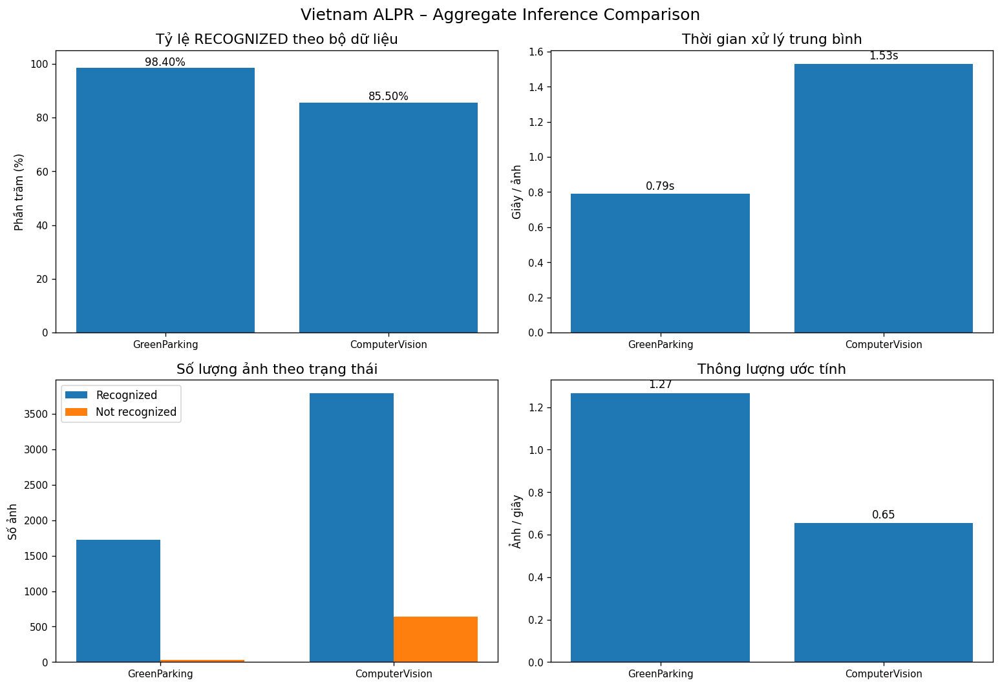

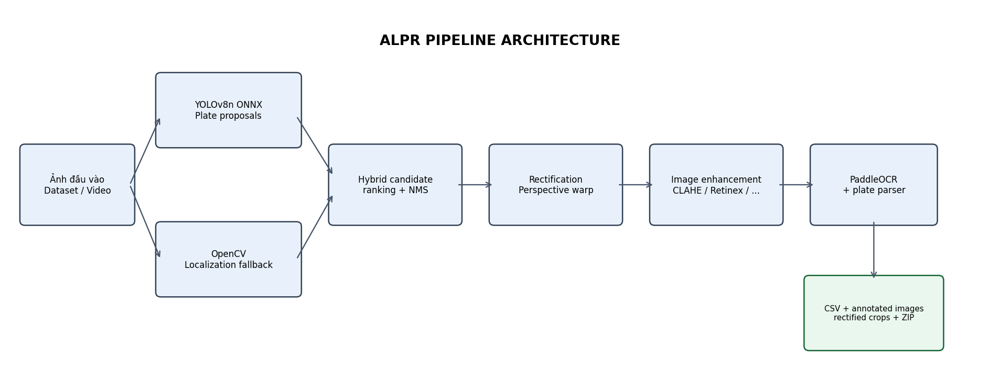


=== SO SÁNH PHƯƠNG PHÁP ĐỊNH VỊ ===


,method,principle,strengths,limitations,training_loss_optimizer_callbacks
0,OpenCV localization,"Sobel/Canny, morphology, contours, minAreaRect...",Không cần train; nhẹ; dễ giải thích; fallback ...,"Nhạy với ánh sáng, nền phức tạp, mờ, góc nghiê...",Không áp dụng – phương pháp xử lý ảnh theo luật
1,YOLOv8n ONNX detector,"Detector deep learning một lớp license_plate, ...",Học đặc trưng từ dữ liệu; thích nghi tốt hơn v...,Cần dữ liệu box đã gán nhãn; phụ thuộc chất lư...,Khi train: box + cls + DFL loss; chọn SGD/Adam...
2,Hybrid hiện tại,"Kết hợp ứng viên YOLO và OpenCV, loại trùng, ư...",Có nhánh dự phòng khi một bộ định vị bỏ sót,Không phải ablation công bằng; candidate được ...,Inference-only trong notebook hiện tại; không ...



Đã lưu dashboard, sơ đồ kiến trúc, CSV/JSON và comparison_report.md tại: /content/alpr_teacher_report


In [10]:
# ============================================================
# A. BÁO CÁO TỔNG HỢP + BIỂU ĐỒ + SƠ ĐỒ KIẾN TRÚC
# ============================================================
from pathlib import Path
import os, json, math, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

REPORT_DIR = "/content/alpr_teacher_report"
os.makedirs(REPORT_DIR, exist_ok=True)

# Số liệu nhập trực tiếp từ FINAL REPORT của hai lần chạy.
summary = pd.DataFrame([
    {
        "dataset": "GreenParking",
        "total_images": 1748,
        "recognized": 1720,
        "not_recognized": 28,
        "errors": 0,
        "reported_success_pct": 98.40,
        "avg_seconds_per_image": 0.79,
    },
    {
        "dataset": "ComputerVision",
        "total_images": 4434,
        "recognized": 3791,
        "not_recognized": 643,
        "errors": 0,
        "reported_success_pct": 85.50,
        "avg_seconds_per_image": 1.53,
    },
])

summary["recomputed_success_pct"] = 100 * summary["recognized"] / summary["total_images"]
summary["failure_pct"] = 100 * (summary["not_recognized"] + summary["errors"]) / summary["total_images"]
summary["images_per_second"] = 1 / summary["avg_seconds_per_image"]
summary["estimated_total_seconds"] = summary["total_images"] * summary["avg_seconds_per_image"]
summary.to_csv(os.path.join(REPORT_DIR, "aggregate_comparison.csv"), index=False, encoding="utf-8-sig")
summary.to_json(os.path.join(REPORT_DIR, "aggregate_comparison.json"), orient="records", force_ascii=False, indent=2)

A, B = summary.iloc[0], summary.iloc[1]
pp_gap = A["recomputed_success_pct"] - B["recomputed_success_pct"]
time_ratio = B["avg_seconds_per_image"] / A["avg_seconds_per_image"]
failure_ratio = B["failure_pct"] / A["failure_pct"] if A["failure_pct"] else np.nan

print("=== SO SÁNH HAI LẦN CHẠY ===")
print(summary[["dataset", "total_images", "recognized", "not_recognized", "errors",
               "recomputed_success_pct", "failure_pct", "avg_seconds_per_image", "images_per_second"]]
      .round(2).to_string(index=False))
print(f"\nChênh lệch tỷ lệ RECOGNIZED (GreenParking - ComputerVision): {pp_gap:.2f} điểm phần trăm")
print(f"ComputerVision cần thời gian trung bình gấp {time_ratio:.2f} lần GreenParking.")
print(f"Tỷ lệ ảnh chưa nhận diện ở ComputerVision cao gấp {failure_ratio:.2f} lần GreenParking.")

# Biểu đồ dashboard
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
labels = summary["dataset"].tolist()

axes[0, 0].bar(labels, summary["recomputed_success_pct"])
axes[0, 0].set_title("Tỷ lệ RECOGNIZED theo bộ dữ liệu")
axes[0, 0].set_ylabel("Phần trăm (%)")
axes[0, 0].set_ylim(0, 105)
for i, v in enumerate(summary["recomputed_success_pct"]):
    axes[0, 0].text(i, v + 1, f"{v:.2f}%", ha="center")

axes[0, 1].bar(labels, summary["avg_seconds_per_image"])
axes[0, 1].set_title("Thời gian xử lý trung bình")
axes[0, 1].set_ylabel("Giây / ảnh")
for i, v in enumerate(summary["avg_seconds_per_image"]):
    axes[0, 1].text(i, v + 0.025, f"{v:.2f}s", ha="center")

x = np.arange(len(labels))
width = 0.36
axes[1, 0].bar(x - width/2, summary["recognized"], width, label="Recognized")
axes[1, 0].bar(x + width/2, summary["not_recognized"], width, label="Not recognized")
axes[1, 0].set_xticks(x, labels)
axes[1, 0].set_title("Số lượng ảnh theo trạng thái")
axes[1, 0].set_ylabel("Số ảnh")
axes[1, 0].legend()

axes[1, 1].bar(labels, summary["images_per_second"])
axes[1, 1].set_title("Thông lượng ước tính")
axes[1, 1].set_ylabel("Ảnh / giây")
for i, v in enumerate(summary["images_per_second"]):
    axes[1, 1].text(i, v + 0.025, f"{v:.2f}", ha="center")

fig.suptitle("Vietnam ALPR – Aggregate Inference Comparison", fontsize=15)
fig.tight_layout()
chart_path = os.path.join(REPORT_DIR, "comparison_dashboard.png")
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Sơ đồ kiến trúc tạo bằng matplotlib (không phụ thuộc Graphviz)
fig, ax = plt.subplots(figsize=(16, 6))
ax.set_xlim(0, 16); ax.set_ylim(0, 6); ax.axis("off")
boxes = [
    (0.3, 2.4, 1.7, 1.2, "Ảnh đầu vào\nDataset / Video"),
    (2.5, 3.7, 2.2, 1.1, "YOLOv8n ONNX\nPlate proposals"),
    (2.5, 1.2, 2.2, 1.1, "OpenCV\nLocalization fallback"),
    (5.3, 2.4, 2.0, 1.2, "Hybrid candidate\nranking + NMS"),
    (7.9, 2.4, 2.0, 1.2, "Rectification\nPerspective warp"),
    (10.5, 2.4, 2.0, 1.2, "Image enhancement\nCLAHE / Retinex / ..."),
    (13.1, 2.4, 1.9, 1.2, "PaddleOCR\n+ plate parser"),
]
for x0, y0, w, h, label in boxes:
    patch = FancyBboxPatch((x0, y0), w, h, boxstyle="round,pad=0.08", linewidth=1.5,
                           edgecolor="#334155", facecolor="#e8f1fb")
    ax.add_patch(patch)
    ax.text(x0+w/2, y0+h/2, label, ha="center", va="center", fontsize=10)

def arrow(p1, p2):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="->", mutation_scale=14,
                                 linewidth=1.4, color="#475569"))
arrow((2.0, 3.0), (2.5, 4.15))
arrow((2.0, 3.0), (2.5, 1.75))
arrow((4.7, 4.15), (5.3, 3.15))
arrow((4.7, 1.75), (5.3, 2.85))
arrow((7.3, 3.0), (7.9, 3.0))
arrow((9.9, 3.0), (10.5, 3.0))
arrow((12.5, 3.0), (13.1, 3.0))
# Output group
out = FancyBboxPatch((13.0, 0.3), 2.1, 1.1, boxstyle="round,pad=0.08", linewidth=1.5,
                     edgecolor="#166534", facecolor="#e9f7ef")
ax.add_patch(out)
ax.text(14.05, 0.85, "CSV + annotated images\nrectified crops + ZIP", ha="center", va="center", fontsize=9)
arrow((14.05, 2.4), (14.05, 1.4))
ax.text(8, 5.35, "ALPR PIPELINE ARCHITECTURE", ha="center", fontsize=16, weight="bold")
fig.tight_layout()
architecture_path = os.path.join(REPORT_DIR, "pipeline_architecture.png")
fig.savefig(architecture_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# Bảng đối chiếu hai phương pháp định vị đang có trong code
method_comparison = pd.DataFrame([
    {
        "method": "OpenCV localization",
        "principle": "Sobel/Canny, morphology, contours, minAreaRect, heuristic ranking",
        "strengths": "Không cần train; nhẹ; dễ giải thích; fallback khi thiếu model",
        "limitations": "Nhạy với ánh sáng, nền phức tạp, mờ, góc nghiêng và plate nhỏ",
        "training_loss_optimizer_callbacks": "Không áp dụng – phương pháp xử lý ảnh theo luật",
    },
    {
        "method": "YOLOv8n ONNX detector",
        "principle": "Detector deep learning một lớp license_plate, dự đoán bounding box + confidence",
        "strengths": "Học đặc trưng từ dữ liệu; thích nghi tốt hơn với đa dạng bối cảnh nếu dữ liệu train đủ",
        "limitations": "Cần dữ liệu box đã gán nhãn; phụ thuộc chất lượng train/export; tốn tài nguyên hơn OpenCV",
        "training_loss_optimizer_callbacks": "Khi train: box + cls + DFL loss; chọn SGD/AdamW; early stopping/scheduler",
    },
    {
        "method": "Hybrid hiện tại",
        "principle": "Kết hợp ứng viên YOLO và OpenCV, loại trùng, ưu tiên candidate theo quy tắc",
        "strengths": "Có nhánh dự phòng khi một bộ định vị bỏ sót",
        "limitations": "Không phải ablation công bằng; candidate được ưu tiên theo logic heuristic",
        "training_loss_optimizer_callbacks": "Inference-only trong notebook hiện tại; không có loss curve",
    },
])
method_comparison.to_csv(os.path.join(REPORT_DIR, "localization_methods_comparison.csv"), index=False, encoding="utf-8-sig")
print("\n=== SO SÁNH PHƯƠNG PHÁP ĐỊNH VỊ ===")
try:
    display(method_comparison)
except NameError:
    print(method_comparison.to_string(index=False))

# Bản Markdown dùng được trong báo cáo
report_text = f"""# Kết quả thực nghiệm ALPR\n\n## So sánh hai bộ dữ liệu\n\n| Chỉ tiêu | GreenParking | ComputerVision |\n|---|---:|---:|\n| Tổng số ảnh | {int(A.total_images):,} | {int(B.total_images):,} |\n| RECOGNIZED | {int(A.recognized):,} | {int(B.recognized):,} |\n| NOT_RECOGNIZED | {int(A.not_recognized):,} | {int(B.not_recognized):,} |\n| ERROR | {int(A.errors):,} | {int(B.errors):,} |\n| Tỷ lệ RECOGNIZED tính lại | {A.recomputed_success_pct:.2f}% | {B.recomputed_success_pct:.2f}% |\n| Thời gian trung bình | {A.avg_seconds_per_image:.2f} s/ảnh | {B.avg_seconds_per_image:.2f} s/ảnh |\n| Thông lượng ước tính | {A.images_per_second:.2f} ảnh/s | {B.images_per_second:.2f} ảnh/s |\n\nGreenParking cao hơn ComputerVision {pp_gap:.2f} điểm phần trăm về tỷ lệ RECOGNIZED. ComputerVision cần thời gian trung bình gấp {time_ratio:.2f} lần. Tỷ lệ NOT_RECOGNIZED của ComputerVision cao gấp {failure_ratio:.2f} lần.\n\n## Diễn giải và giới hạn\n\nHai lần chạy sử dụng cùng pipeline YOLOv8n ONNX + OpenCV + PaddleOCR, cùng runtime PaddlePaddle 3.2.0, CUDA GPU và cùng mô hình ONNX theo log. Vì vậy đây là **so sánh kết quả trên hai bộ dữ liệu**, không phải so sánh hai kiến trúc AI. Hai bộ dữ liệu có số lượng và có thể có độ khó/phân phối ảnh khác nhau; không thể kết luận nguyên nhân chênh lệch chỉ từ bảng tổng hợp.\n\n`RECOGNIZED` chỉ biểu thị chuỗi OCR vượt qua parser heuristic. Chỉ số này không đồng nghĩa exact-match với nhãn thật. Muốn có precision/recall/F1 cho phát hiện biển số và exact-match/CER cho OCR, cần ground-truth tương ứng từng ảnh.\n\nLoss/accuracy curves chỉ có thể lấy từ lịch sử train (ví dụ `results.csv` của lần train YOLO), không thể khôi phục từ inference report.\n"""
with open(os.path.join(REPORT_DIR, "comparison_report.md"), "w", encoding="utf-8") as f:
    f.write(report_text)
print("\nĐã lưu dashboard, sơ đồ kiến trúc, CSV/JSON và comparison_report.md tại:", REPORT_DIR)